# Focused plotting code: Figures 3, 4, 5, Supplementary Figures 4, 7, and 8

Cells that directly save figures are labeled. Run each source section top-to-bottom because upstream processing/functions are required.

# qPCR without Transposase

In [1]:
import marimo as mo

import os
import numpy as np
import pandas as pd
from scipy import stats
import re
from datetime import datetime
import itertools

# plotting packages
import altair as alt
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt

In [2]:
alt.data_transformers.disable_max_rows()

DataTransformerRegistry.enable('default')

In [3]:
figWidth = 600
figHeight = 270
colorScheme = 'plasma'

## The end of each treatment course
UP_DAYS = [0, 7, 14, 21]
DOWN_DAYS = [5, 12, 19]

TreatmentDilution = 30000
LossTreatmentDays = 5
SelectionTreatmentDays = 2
PlasmidList = ["p15A-+", "pBR-+", "CloDF-+", "pUC-+", "p15A++"] 

In [4]:
calibrationFile = pd.ExcelFile('qPCR_withTransposase/2024-1001_yuanchi.xls')

In [5]:
calibrationDF = calibrationFile.parse('Results', header = 46).loc[:336, ['Well Position', 'Sample Name', 'Target Name', \
                                                  'Rep', 'Dilution', 'PCN', 'CT']]
pUC_DF = calibrationDF[calibrationDF['PCN'] == 'pUC']
p15A_DF = calibrationDF[calibrationDF['PCN'] == 'p15A']

# Locate entried for each target
pUC_df_cm = pUC_DF[pUC_DF['Target Name'] == 'cmR']
pUC_df_kan = pUC_DF[pUC_DF['Target Name'] == 'kanR']
pUC_df_tet = pUC_DF[pUC_DF['Target Name'] == 'tetA']

p15A_df_cm = p15A_DF[p15A_DF['Target Name'] == 'cmR']
p15A_df_kan = p15A_DF[p15A_DF['Target Name'] == 'kanR']
p15A_df_tet = p15A_DF[p15A_DF['Target Name'] == 'tetA']

# Use entries with only determined CT values
pUC_df_cm_used = pUC_df_cm[(pUC_df_cm['Dilution'] != -6) & (pUC_df_cm['Dilution'] != -7)]
pUC_df_kan_used = pUC_df_kan[(pUC_df_kan['Dilution'] != -6) & (pUC_df_kan['Dilution'] != -7)]
pUC_df_tet_used = pUC_df_tet[(pUC_df_tet['Dilution'] != -6) & (pUC_df_tet['Dilution'] != -7) ]

p15A_df_cm_used = p15A_df_cm[p15A_df_cm['Dilution'] != -6]
p15A_df_kan_used = p15A_df_kan[p15A_df_kan['Dilution'] != -6]
p15A_df_tet_used = p15A_df_tet[p15A_df_tet['Dilution'] != -6]

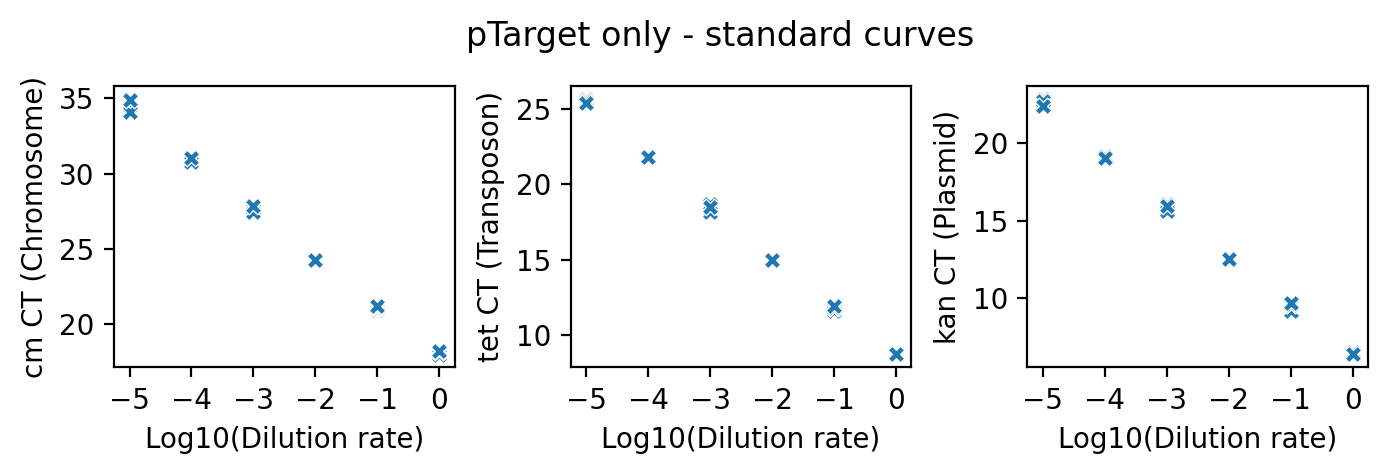

In [6]:
figPUC, axesPUC = plt.subplots(1,3, figsize = (7, 2), dpi = 200)
plt.tight_layout()
sns.scatterplot(x = 'Dilution', y = 'CT', data = pUC_df_cm_used, ax = axesPUC[0], 
              marker = 'X')
sns.scatterplot(x = 'Dilution', y = 'CT', data = pUC_df_tet_used, ax = axesPUC[1], 
             marker = 'X')
sns.scatterplot(x = 'Dilution', y = 'CT', data = pUC_df_kan_used, ax = axesPUC[2], 
             marker = 'X')

plt.suptitle('pTarget only - standard curves', va = 'bottom')
axesPUC[0].set_ylabel('cm CT (Chromosome)')
axesPUC[1].set_ylabel('tet CT (Transposon)')
axesPUC[2].set_ylabel('kan CT (Plasmid)')
axesPUC[0].set_xlabel('Log10(Dilution rate)')
axesPUC[1].set_xlabel('Log10(Dilution rate)')
axesPUC[2].set_xlabel('Log10(Dilution rate)')
axesPUC[0].set_xticks([-5,-4,-3,-2,-1,0])
axesPUC[1].set_xticks([-5,-4,-3,-2,-1,0])
axesPUC[2].set_xticks([-5,-4,-3,-2,-1,0])
#plt.savefig('SF8_A.pdf', format="pdf", bbox_inches="tight")
plt.show()

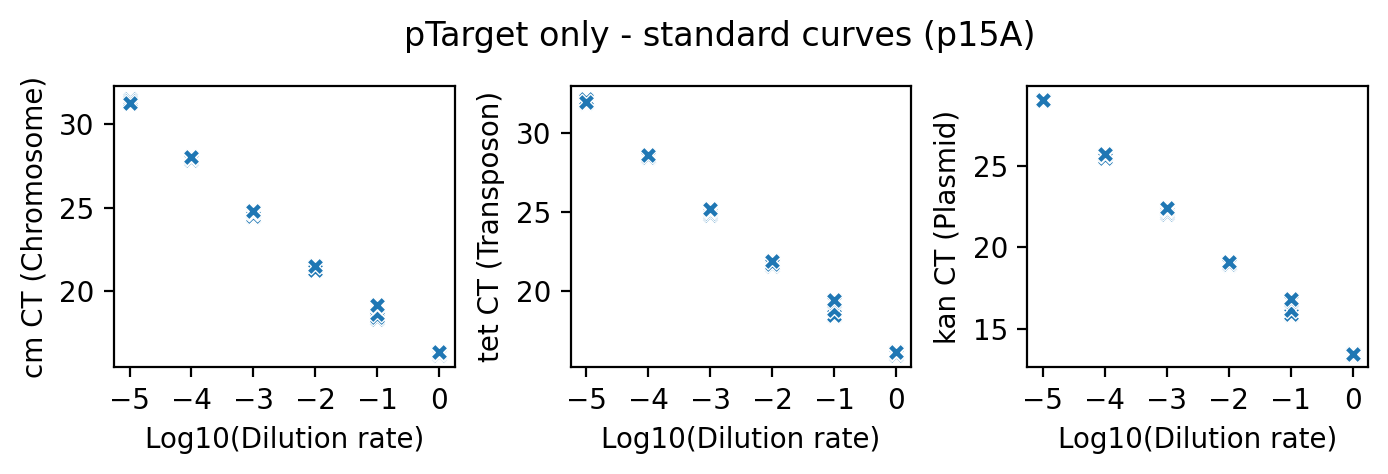

In [7]:
figP15A, axesP15A = plt.subplots(1,3, figsize = (7, 2), dpi = 200)

plt.tight_layout()
sns.scatterplot(x = 'Dilution', y = 'CT', data = p15A_df_cm_used, ax = axesP15A[0], 
              marker = 'X')
sns.scatterplot(x = 'Dilution', y = 'CT', data = p15A_df_tet_used, ax = axesP15A[1], 
             marker = 'X')
sns.scatterplot(x = 'Dilution', y = 'CT', data = p15A_df_kan_used, ax = axesP15A[2], 
             marker = 'X')

plt.suptitle('pTarget only - standard curves (p15A)', va = 'bottom')
axesP15A[0].set_ylabel('cm CT (Chromosome)')
axesP15A[1].set_ylabel('tet CT (Transposon)')
axesP15A[2].set_ylabel('kan CT (Plasmid)')
axesP15A[0].set_xlabel('Log10(Dilution rate)')
axesP15A[1].set_xlabel('Log10(Dilution rate)')
axesP15A[2].set_xlabel('Log10(Dilution rate)')
axesP15A[0].set_xticks([-5,-4,-3,-2,-1,0])
axesP15A[1].set_xticks([-5,-4,-3,-2,-1,0])
axesP15A[2].set_xticks([-5,-4,-3,-2,-1,0])

plt.show()

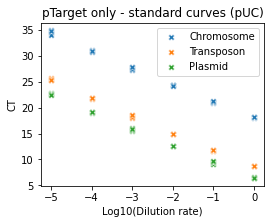

In [8]:
plt.figure(figsize=(4, 3))
sns.scatterplot(x = 'Dilution', y = 'CT', data = pUC_df_cm_used, label='Chromosome', \
              marker = 'X')
sns.scatterplot(x = 'Dilution', y = 'CT', data = pUC_df_tet_used, label='Transposon', \
             marker = 'X')
sns.scatterplot(x = 'Dilution', y = 'CT', data = pUC_df_kan_used, label='Plasmid', \
             marker = 'X')

plt.xlabel('Log10(Dilution rate)')
plt.ylabel('CT')
plt.title('pTarget only - standard curves (pUC)')
plt.show()

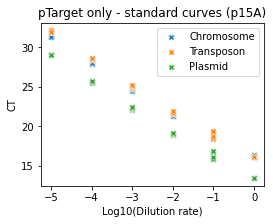

In [9]:
plt.figure(figsize=(4, 3))
sns.scatterplot(x = 'Dilution', y = 'CT', data = p15A_df_cm_used, label='Chromosome', \
              marker = 'X')
sns.scatterplot(x = 'Dilution', y = 'CT', data = p15A_df_tet_used, label='Transposon', \
             marker = 'X')
sns.scatterplot(x = 'Dilution', y = 'CT', data = p15A_df_kan_used, label='Plasmid', \
             marker = 'X')

plt.xlabel('Log10(Dilution rate)')
plt.ylabel('CT')
plt.title('pTarget only - standard curves (p15A)')
plt.show()

# Long-term experimental data analysis starting here

In [10]:
def calculateSlopeAmpEff(targetedDFList):
    slopeList = []
    amplificationFactorList = []
    amplificationEfficiencyList = []

    for df in targetedDFList:
        slope = np.polynomial.polynomial.polyfit(list(df['Dilution']), list(df['CT']), 1)[1]
        amplificationFactor = 10**(-1*(1/slope))
        amplificationEfficiency = (amplificationFactor-1)*100

        slopeList.append(slope)
        amplificationFactorList.append(amplificationFactor)
        amplificationEfficiencyList.append(amplificationEfficiency)

    return slopeList, amplificationFactorList, amplificationEfficiencyList

In [11]:
slopeList, ampFactorList, effList = calculateSlopeAmpEff([pUC_df_cm_used, pUC_df_kan_used, pUC_df_tet_used])

In [14]:
# Import daily qPCR results
D0 = pd.ExcelFile('qPCR_withoutTransposase/10042025_day0_kan_yuanchi.xls').parse('Results', header = 46).loc[:273, ['Well Position', \
                                                'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D0_noKan = pd.ExcelFile('qPCR_withoutTransposase/10042025_day0_nokan_yuanchi.xls').parse('Results', header = 46).loc[:273, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D1 = pd.ExcelFile('qPCR_withoutTransposase/12032025_day01_kan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D1_noKan = pd.ExcelFile('qPCR_withoutTransposase/12032025_day01_nokan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D2 = pd.ExcelFile('qPCR_withoutTransposase/11252025_day02_kan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D2_noKan = pd.ExcelFile('qPCR_withoutTransposase/11252025_day02_nokan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D3 = pd.ExcelFile('qPCR_withoutTransposase/10242025_day03_kan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D3_noKan = pd.ExcelFile('qPCR_withoutTransposase/10242025_day03_nokan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D4 = pd.ExcelFile('qPCR_withoutTransposase/10242025_day04_kan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D4_noKan = pd.ExcelFile('qPCR_withoutTransposase/10242025_day04_nokan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D5 = pd.ExcelFile('qPCR_withoutTransposase/10042025_day05_kan_yuanchi.xls').parse('Results', header = 46).loc[:273, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D5_noKan = pd.ExcelFile('qPCR_withoutTransposase/10042025_day05_nokan_yuanchi.xls').parse('Results', header = 46).loc[:273, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D6 = pd.ExcelFile('qPCR_withoutTransposase/10202025_day06_kan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D6_noKan = pd.ExcelFile('qPCR_withoutTransposase/10202025_day06_nokan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D7 = pd.ExcelFile('qPCR_withoutTransposase/10042025_day07_kan_yuanchi.xls').parse('Results', header = 46).loc[:273, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D7_noKan = pd.ExcelFile('qPCR_withoutTransposase/10042025_day07_nokan_yuanchi.xls').parse('Results', header = 46).loc[:273, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D8 = pd.ExcelFile('qPCR_withoutTransposase/11252025_day08_kan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D8_noKan = pd.ExcelFile('qPCR_withoutTransposase/11252025_day08_nokan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D9 = pd.ExcelFile('qPCR_withoutTransposase/11212025_day09_kan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D9_noKan = pd.ExcelFile('qPCR_withoutTransposase/11212025_day09_nokan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D10 = pd.ExcelFile('qPCR_withoutTransposase/11202025_day10_kan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D10_noKan = pd.ExcelFile('qPCR_withoutTransposase/11202025_day10_nokan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D11 = pd.ExcelFile('qPCR_withoutTransposase/11182025_day11_kan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D11_noKan = pd.ExcelFile('qPCR_withoutTransposase/11182025_day11_nokan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D12 = pd.ExcelFile('qPCR_withoutTransposase/10042025_day12_kan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D12_noKan = pd.ExcelFile('qPCR_withoutTransposase/10042025_day12_nokan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D13 = pd.ExcelFile('qPCR_withoutTransposase/10202025_day13_kan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D13_noKan = pd.ExcelFile('qPCR_withoutTransposase/10202025_day13_nokan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D14 = pd.ExcelFile('qPCR_withoutTransposase/10202025_day14_kan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D14_noKan = pd.ExcelFile('qPCR_withoutTransposase/10202025_day14_nokan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D15 = pd.ExcelFile('qPCR_withoutTransposase/11122025_day15_kan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D15_noKan = pd.ExcelFile('qPCR_withoutTransposase/11122025_day15_nokan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D16 = pd.ExcelFile('qPCR_withoutTransposase/11112025_day16_kan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D16_noKan = pd.ExcelFile('qPCR_withoutTransposase/11112025_day16_nokan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D17 = pd.ExcelFile('qPCR_withoutTransposase/11062025_day17_kan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D17_noKan = pd.ExcelFile('qPCR_withoutTransposase/11062025_day17_nokan_yuanchi.xls').parse('Correct_Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D18 = pd.ExcelFile('qPCR_withoutTransposase/11052025_day18_kan_yuanchi.xls').parse('Correct_Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D18_noKan = pd.ExcelFile('qPCR_withoutTransposase/11052025_day18_nokan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D19 = pd.ExcelFile('qPCR_withoutTransposase/10182025_day19_kan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D19_noKan = pd.ExcelFile('qPCR_withoutTransposase/10182025_day19_nokan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D20 = pd.ExcelFile('qPCR_withoutTransposase/10182025_day20_kan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D20_noKan = pd.ExcelFile('qPCR_withoutTransposase/10182025_day20_nokan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D21 = pd.ExcelFile('qPCR_withoutTransposase/10182025_day21_kan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D21_noKan = pd.ExcelFile('qPCR_withoutTransposase/10182025_day21_nokan_yuanchi.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

In [15]:
# Load in all files
datafiles_Kan = [(D0,0), (D1,1), (D2,2), (D3,3), (D4,4), (D5,5), (D6,6), (D7,7), (D8,8), (D9,9), (D10,10),\
                 (D11,11), (D12,12), (D13,13), (D14,14), (D15,15), (D16,16), (D17,17), (D18,18), \
                 (D19,19), (D20,20), (D21,21)]

datafiles_noKan = [(D0_noKan,0), (D1_noKan,1), (D2_noKan,2), (D3_noKan,3), (D4_noKan,4), (D5_noKan,5), (D6_noKan,6), \
                   (D7_noKan,7), (D8_noKan,8), (D9_noKan,9), (D10_noKan,10), (D11_noKan,11), (D12_noKan,12), \
                   (D13_noKan,13), (D14_noKan,14), (D15_noKan,15), (D16_noKan,16), (D17_noKan,17), \
                   (D18_noKan,18), (D19_noKan,19), (D20_noKan,20), (D21_noKan,21)]

In [16]:
def processOneDay(DF, day):
    print(day)
    calculatedDF = pd.DataFrame()

    # Get all calibrated parameters
    DF.loc[DF['Target Name'] == 'cmR', 'Slope'] = slopeList[0]
    DF.loc[DF['Target Name'] == 'kanR', 'Slope'] = slopeList[1]
    DF.loc[DF['Target Name'] == 'tetA', 'Slope'] = slopeList[2]

    DF.loc[DF['Target Name'] == 'cmR', 'AmpFactor'] = ampFactorList[0]
    DF.loc[DF['Target Name'] == 'kanR', 'AmpFactor'] = ampFactorList[1]
    DF.loc[DF['Target Name'] == 'tetA', 'AmpFactor'] = ampFactorList[2]

    DF.loc[DF['Target Name'] == 'cmR', 'Eff'] = effList[0]
    DF.loc[DF['Target Name'] == 'kanR', 'Eff'] = effList[1]
    DF.loc[DF['Target Name'] == 'tetA', 'Eff'] = effList[2]

    qPCRRepList = list(set(DF['qPCRRep']))
    ExpRepList = list(set(DF['ExpRep']))
    PCNList = list(set(DF['PCN']))
    PCNList = [i for i in PCNList if (i != 'H2O') & (i != 'Blank')]

    qPCR_Exp_PCN_Tuple_List = list(itertools.product(qPCRRepList, ExpRepList, PCNList))

    for t in qPCR_Exp_PCN_Tuple_List:
        df_current = DF[(DF['qPCRRep'] == t[0]) & (DF['ExpRep'] == t[1]) & (DF['PCN'] == t[2])]
        currentSlice = DF.loc[df_current.index]

        if currentSlice.empty == False:
            if 'tetA' in (list(currentSlice['Target Name'])):
                currentSlice = currentSlice[currentSlice['CT'] != 'Undetermined']

                cmR_CT = pd.DataFrame(currentSlice[currentSlice['Target Name'] == 'cmR']['CT']).values[0][0]
                tetA_CT = pd.DataFrame(currentSlice[currentSlice['Target Name'] == 'tetA']['CT']).values[0][0]

                cmR_ampFactor = currentSlice[currentSlice['Target Name'] == 'cmR']['AmpFactor'].values[0]
                tetA_ampFactor = currentSlice[currentSlice['Target Name'] == 'tetA']['AmpFactor'].values[0]

                TCopy = cmR_ampFactor**(cmR_CT)/tetA_ampFactor**(tetA_CT)
                currentSlice['transposon copy'] = TCopy

                if currentSlice['PCN'].values[0] != 'Chromosome':
                    kanR_CT = pd.DataFrame(currentSlice[currentSlice['Target Name'] == 'kanR']['CT']).values[0][0]
                    kanR_ampFactor = currentSlice[currentSlice['Target Name'] == 'kanR']['AmpFactor'].values[0]
                    PCopy = cmR_ampFactor**(cmR_CT)/kanR_ampFactor**(kanR_CT)
                    currentSlice['plasmid copy'] = PCopy
                    currentSlice['T/P'] = (TCopy-1)/PCopy
                else:
                    currentSlice['plasmid copy'] = 0

            else:
                currentSlice = currentSlice[currentSlice['CT'] != 'Undetermined']

                cmR_CT = pd.DataFrame(currentSlice[currentSlice['Target Name'] == 'cmR']['CT']).values[0][0]
                kanR_CT = pd.DataFrame(currentSlice[currentSlice['Target Name'] == 'kanR']['CT']).values[0][0]

                cmR_ampFactor = currentSlice[currentSlice['Target Name'] == 'cmR']['AmpFactor'].values[0]
                kanR_ampFactor = currentSlice[currentSlice['Target Name'] == 'kanR']['AmpFactor'].values[0]

                currentSlice['transposon copy'] = 0
                currentSlice['T/P'] = 0

                if kanR_CT != 'Undetermined':
                    currentSlice['plasmid copy'] = cmR_ampFactor**(cmR_CT)/kanR_ampFactor**(kanR_CT)
                else:
                    currentSlice['plasmid copy'] = 0

            calculatedDF = pd.concat([calculatedDF, currentSlice], ignore_index=True)

    calculatedDF["Day"] = day
    calculatedDF['qPCRRep'] = calculatedDF['qPCRRep'].astype(int)  
    calculatedDF['ExpRep'] = calculatedDF['ExpRep'].astype(int).astype(str)


    return calculatedDF

In [17]:
# Process every file
dataframes_tet10_kan = \
[processOneDay(pair[0], pair[1]) for pair in datafiles_Kan]
dataframes_tet10_noKan = \
[processOneDay(pair[0], pair[1]) for pair in datafiles_noKan]

completeDF_tet10_kan = pd.concat(dataframes_tet10_kan, ignore_index=True)
completeDF_tet10_kan['tet'] = 10
completeDF_tet10_noKan = pd.concat(dataframes_tet10_noKan, ignore_index=True)
completeDF_tet10_noKan['tet'] = 10

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21


In [18]:
# Take out all the calibration and testing wells for further analysis
tet10_kan_DF = completeDF_tet10_kan[(completeDF_tet10_kan['PCN'] != 'cyro_chromosome') & \
                               (completeDF_tet10_kan['PCN'] != 'cyro_pSC101') & \
                               (completeDF_tet10_kan['PCN'] != 'p15ASep')]

# Arrange the PCN based on copy number
tet10_kan_DF["PCN"] = pd.Series(
    tet10_kan_DF["PCN"], dtype="category"
)

tet10_kan_DF["PCN"] = tet10_kan_DF[
            "PCN"
        ].cat.reorder_categories(
            [
                "p15A-+",
                "pBR-+",
                "CloDF-+",
                "pUC-+",
                "p15A++",
            ],
            ordered=True,
        )

# Take out all the calibration and testing wells for further analysis
tet10_noKan_DF = completeDF_tet10_noKan[(completeDF_tet10_noKan['PCN'] != 'cyro_chromosome') & \
                               (completeDF_tet10_noKan['PCN'] != 'cyro_pSC101') & \
                               (completeDF_tet10_noKan['PCN'] != 'p15ASep')]

# Arrange the PCN based on copy number
tet10_noKan_DF["PCN"] = pd.Series(
    tet10_noKan_DF["PCN"], dtype="category"
)

tet10_noKan_DF["PCN"] = tet10_noKan_DF[
            "PCN"
        ].cat.reorder_categories(
            [
                "p15A-+",
                "pBR-+",
                "CloDF-+",
                "pUC-+",
                "p15A++",
            ],
            ordered=True,
        )

In [19]:
# Calculate the log of plasmid copy number and transposon copy number
tet10_kan_DF['log(plasmid copy)'] = np.log10(tet10_kan_DF['plasmid copy'])
tet10_kan_DF['log(transposon copy)'] = np.log10(tet10_kan_DF['transposon copy'])

tet10_noKan_DF['log(plasmid copy)'] = np.log10(tet10_noKan_DF['plasmid copy'])
tet10_noKan_DF['log(transposon copy)'] = np.log10(tet10_noKan_DF['transposon copy'])

In [20]:
completeDF_tet10_kan_copy = tet10_kan_DF.copy(deep=True)
completeDF_tet10_noKan_copy = tet10_noKan_DF.copy(deep=True)

In [21]:
tet10_kan_DF_Use = \
tet10_kan_DF[(tet10_kan_DF['PCN'] != 'p15A')] 

tet10_noKan_DF_Use = \
tet10_noKan_DF[(tet10_noKan_DF['PCN'] != 'p15A')]

tet10_kan_DF_Use_pUC = tet10_kan_DF_Use[tet10_kan_DF_Use['PCN'] == 'pUC']
tet10_noKan_DF_Use_pUC = tet10_noKan_DF_Use[tet10_noKan_DF_Use['PCN'] == 'pUC']

In [22]:
tet10_kan_DF_Use_grouped = tet10_kan_DF_Use.groupby(['Day', 'ExpRep', 'PCN'])[['log(transposon copy)', 'log(plasmid copy)', 'transposon copy', 'plasmid copy', 'T/P']].mean().reset_index().dropna()

tet10_noKan_DF_Use_grouped = tet10_noKan_DF_Use.groupby(['Day', 'ExpRep', 'PCN'])[['log(transposon copy)', 'log(plasmid copy)', 'transposon copy', 'plasmid copy', 'T/P']].mean().reset_index().dropna()

In [23]:
# Get the control chromosome strain results from my previous results
noTransposon_kan_qPCR_timeCourse_DF = pd.read_csv('qPCR_withoutTransposase/noTransposon_kan_qPCR_timeCourse.csv')
noTransposon_kan_qPCR_timeCourse_DF_Chr = noTransposon_kan_qPCR_timeCourse_DF[noTransposon_kan_qPCR_timeCourse_DF['PCN'] == 'Chromosome']

noTransposon_noKan_qPCR_timeCourse_DF = pd.read_csv('qPCR_withoutTransposase/noTransposon_noKan_qPCR_timeCourse.csv')
noTransposon_noKan_qPCR_timeCourse_DF_Chr = noTransposon_noKan_qPCR_timeCourse_DF[noTransposon_noKan_qPCR_timeCourse_DF['PCN'] == 'Chromosome']

In [24]:
# Create two groups of results.
# One for strains without transposase. One for p15A with transposase; did the other three experiments previously already
group_main_list = ['p15A-+', 'pBR-+', 'CloDF-+', 'pUC-+']
group_p15A_pp_list = ['p15A++']

# Filter for the main group (p15A-+, CloDF-+, pUC-+, pBR-+)
df_main = tet10_kan_DF_Use_grouped[tet10_kan_DF_Use_grouped['PCN'].isin(group_main_list)]
# Remove the unused 'p15A++' category from the metadata ---
df_main['PCN'] = df_main['PCN'].astype('category').cat.remove_unused_categories()

# Filter for the p15A++ group
df_p15A_pp = tet10_kan_DF_Use_grouped[tet10_kan_DF_Use_grouped['PCN'].isin(group_p15A_pp_list)]

/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_67811/687994681.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_main['PCN'] = df_main['PCN'].astype('category').cat.remove_unused_categories()


In [25]:
# # Save the main group to one file
df_main.to_csv('qPCR_no-transposase_with-Kan.csv', index=False)

# # Save the p15A++ group to another file
df_p15A_pp.to_csv('qPCR_transposase_with-Kan_p15A.csv', index=False)

print("CSV files saved successfully.")

CSV files saved successfully.


In [26]:
print(df_main['PCN'].value_counts())
print(df_p15A_pp['PCN'].value_counts())

p15A-+     110
pBR-+      110
CloDF-+    110
pUC-+      110
Name: PCN, dtype: int64
p15A++     110
p15A-+       0
pBR-+        0
CloDF-+      0
pUC-+        0
Name: PCN, dtype: int64


In [27]:
treatmentWindows = [(5, 7), (12, 14), (19, 21)]

def add_treatment_windows(ax):
    for window in treatmentWindows:
        ax.axvspan(
            window[0],
            window[1],
            color='green',
            alpha=0.15,
            zorder=100
        )

### Supplementary Figure 8
**Saved outputs:** `SF8A_No_transposase_withK_PCN.pdf`

/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_67811/1972604879.py:10: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  ax_kan = sns.lineplot(


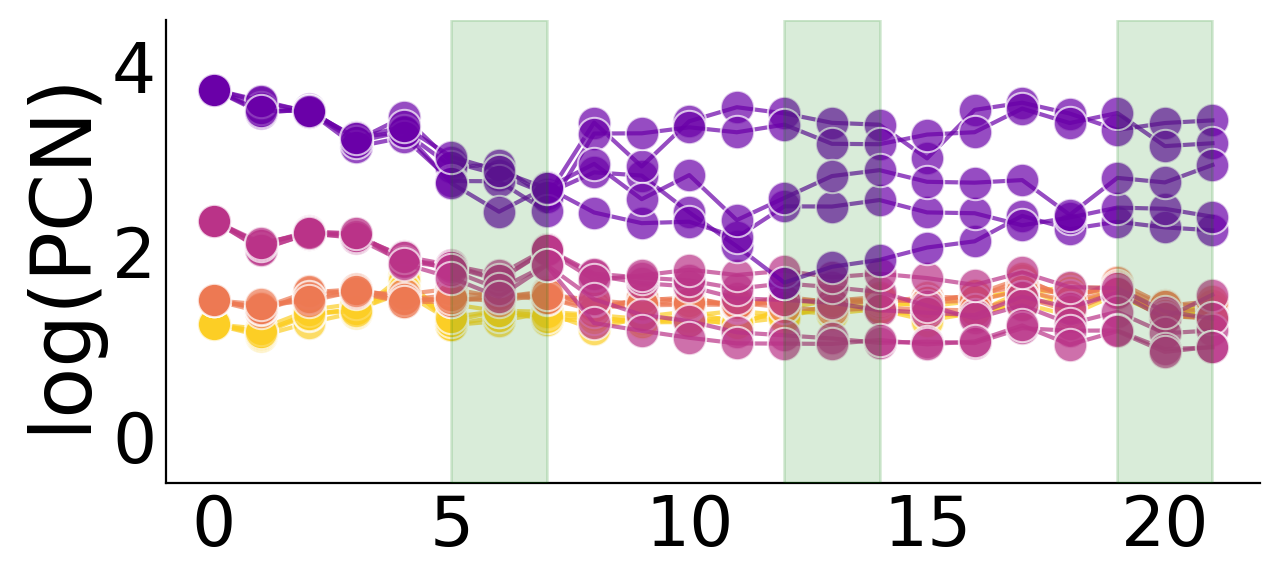

In [28]:
## Experimental conditions: +Kan

# Set up figure size
plt.figure(figsize=(6.5, 3), dpi=200)

# palette02 = ["#7316A2", "#EA9953", "#BC5078", ],
colors = plt.cm.plasma_r(np.linspace(0.1, 0.8, 4))

# Create line plot with points
ax_kan = sns.lineplot(
    data=df_main,
    x='Day',
    y='log(plasmid copy)',
    hue='PCN',  
    units='ExpRep',  # Creates separate lines for each ExpRep (detail in Altair)
    estimator=None,  # Don't aggregate data points
    marker='o',      # Add markers on the line
    markersize=12,   # Large marker size
    alpha=0.7,       # Match opacity from Altair
    palette=colors,
    legend=False     # No legend as in original
)

add_treatment_windows(ax_kan)

# Set axis limits to match Altair scales
plt.xlim(-1, 22)
plt.ylim(-0.5, 4.5)

# Configure axis appearance
ax_kan.tick_params(axis='x', labelsize=25, length=0)
ax_kan.tick_params(axis='y', labelsize=25, length=0)
plt.xticks([0, 5, 10, 15, 20])  # 5 tick marks
plt.yticks([0, 2, 4])  # 3 tick marks
plt.xlabel('')
plt.ylabel('log(PCN)', fontsize=30)
plt.grid(False)

# Remove spines to match minimal Altair style
sns.despine(left=False, bottom=False, right=True, top=True)
# sns.move_legend(ax_kan, "upper left", bbox_to_anchor=(1, 1))

# Use tight layout to optimize spacing
plt.tight_layout()

plt.savefig('Figures_final/supplementary/SF8A_No_transposase_withK_PCN.pdf', format="pdf", bbox_inches="tight")

# Display plot
plt.show()

### Figure 3
**Saved outputs:** `Fig3C_No_transposase_withK_TCN.pdf`

/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_67811/3689032046.py:9: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  ax_kan_TCN = sns.lineplot(


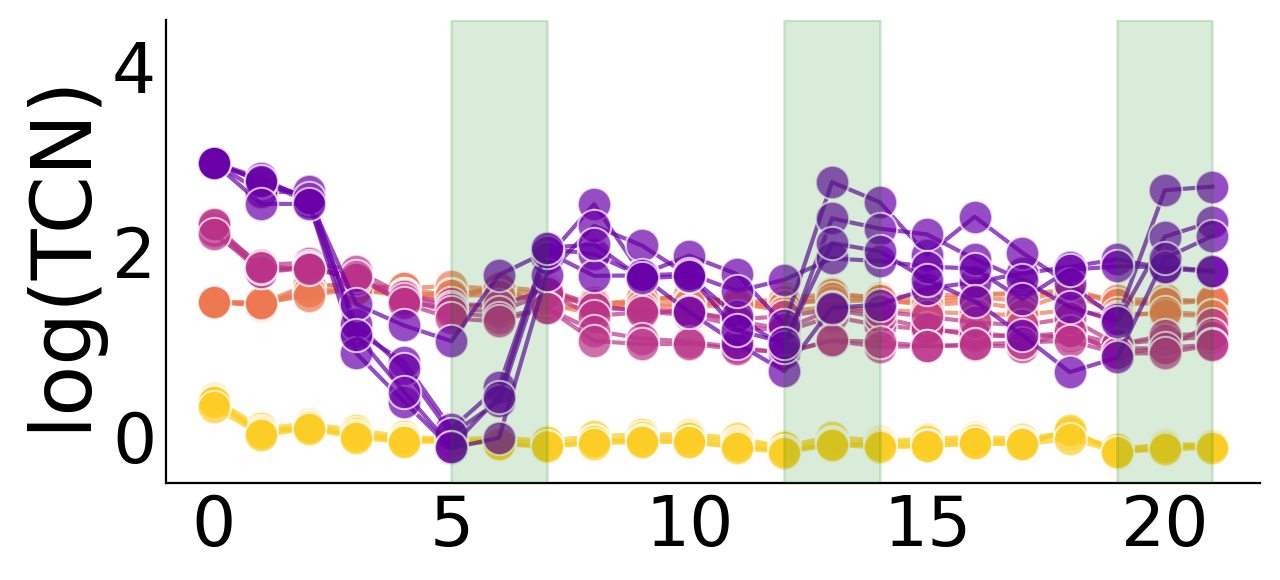

In [29]:
## Experimental conditions: +Kan

# Set up figure size
plt.figure(figsize=(6.5, 3), dpi=200)

# colors = plt.cm.plasma_r(np.linspace(0.1, 0.8, 4))

# Create line plot with points
ax_kan_TCN = sns.lineplot(
    data=df_main,
    x='Day',
    y='log(transposon copy)',
    hue='PCN',  
    units='ExpRep',  # Creates separate lines for each ExpRep (detail in Altair)
    estimator=None,  # Don't aggregate data points
    marker='o',      # Add markers on the line
    markersize=12,   # Large marker size
    alpha=0.7,       # Match opacity from Altair
    palette=colors,
    legend=False     # No legend as in original
)

add_treatment_windows(ax_kan_TCN)

# Set axis limits to match Altair scales
plt.xlim(-1, 22)
plt.ylim(-0.5, 4.5)
#plt.ylim(-1, 4)

# Configure axis appearance
ax_kan_TCN.tick_params(axis='x', labelsize=25, length=0)
ax_kan_TCN.tick_params(axis='y', labelsize=25, length=0)
plt.xticks([0, 5, 10, 15, 20])  # 5 tick marks
# plt.yticks([0, 2, 4])  # 3 tick marks
plt.xlabel('')
plt.ylabel('log(TCN)', fontsize=30)
plt.grid(False)

# Remove spines to match minimal Altair style
sns.despine(left=False, bottom=False, right=True, top=True)
# sns.move_legend(ax_kan_TCN, "upper left", bbox_to_anchor=(1, 1))

# Use tight layout to optimize spacing
plt.tight_layout()

plt.savefig('Figures_final/Figure3/Fig3C_No_transposase_withK_TCN.pdf', format="pdf", bbox_inches="tight")

# Display plot
plt.show()

In [30]:
# Filter for the main group (p15A-+, CloDF-+, pUC-+, pBR-+)
df_main_noKan = tet10_noKan_DF_Use_grouped[tet10_noKan_DF_Use_grouped['PCN'].isin(group_main_list)]
# Remove the unused 'p15A++' category from the metadata ---
df_main_noKan['PCN'] = df_main_noKan['PCN'].astype('category').cat.remove_unused_categories()

# Filter for the p15A++ group
df_p15A_noKan_pp = tet10_noKan_DF_Use_grouped[tet10_noKan_DF_Use_grouped['PCN'].isin(group_p15A_pp_list)]

/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_67811/1871353299.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_main_noKan['PCN'] = df_main_noKan['PCN'].astype('category').cat.remove_unused_categories()


In [31]:
# # Save the main group to one file
df_main_noKan.to_csv('qPCR_no-transposase_no-Kan.csv', index=False)

# # Save the p15A++ group to another file
df_p15A_noKan_pp.to_csv('qPCR_transposase_no-Kan_p15A.csv', index=False)

### Supplementary Figure 8
**Saved outputs:** `SF8A_No_transposase_noK_PCN.pdf`

/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_67811/1406024770.py:4: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  ax_noKan = sns.lineplot(


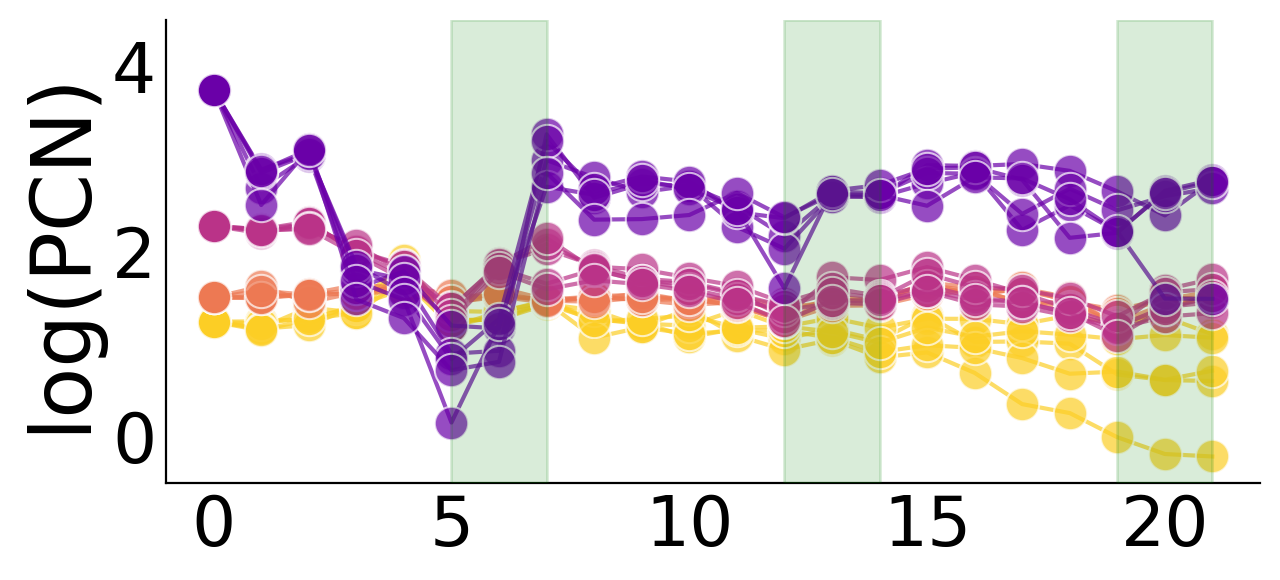

In [32]:
plt.figure(figsize=(6.5, 3), dpi=200)

# Create line plot with points
ax_noKan = sns.lineplot(
    data=df_main_noKan,
    x='Day',
    y='log(plasmid copy)',
    hue='PCN',  
    units='ExpRep',  # Creates separate lines for each ExpRep (detail in Altair)
    estimator=None,  # Don't aggregate data points
    marker='o',      # Add markers on the line
    markersize=12,   # Large marker size
    alpha=0.7,       # Match opacity from Altair
    palette=colors,
    legend=False     # No legend as in original
)

add_treatment_windows(ax_noKan)

# Set axis limits to match Altair scales
plt.xlim(-1, 22)
plt.ylim(-0.5, 4.5)

# Configure axis appearance
ax_noKan.tick_params(axis='x', labelsize=25, length=0)
ax_noKan.tick_params(axis='y', labelsize=25, length=0)
plt.xticks([0, 5, 10, 15, 20])  # 5 tick marks
plt.yticks([0, 2, 4])  # 3 tick marks
plt.xlabel('')
plt.ylabel('log(PCN)', fontsize=30)
plt.grid(False)

# Remove spines to match minimal Altair style
sns.despine(left=False, bottom=False, right=True, top=True)

# Use tight layout to optimize spacing
plt.tight_layout()
plt.savefig('Figures_final/supplementary/SF8A_No_transposase_noK_PCN.pdf', format="pdf", bbox_inches="tight")

# Display plot
plt.show()

### Supplementary Figure 8
**Saved outputs:** `SF8C-No_transposase_K_TCN.pdf`

/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_67811/2638490812.py:7: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  ax_Kan_TCN = sns.lineplot(


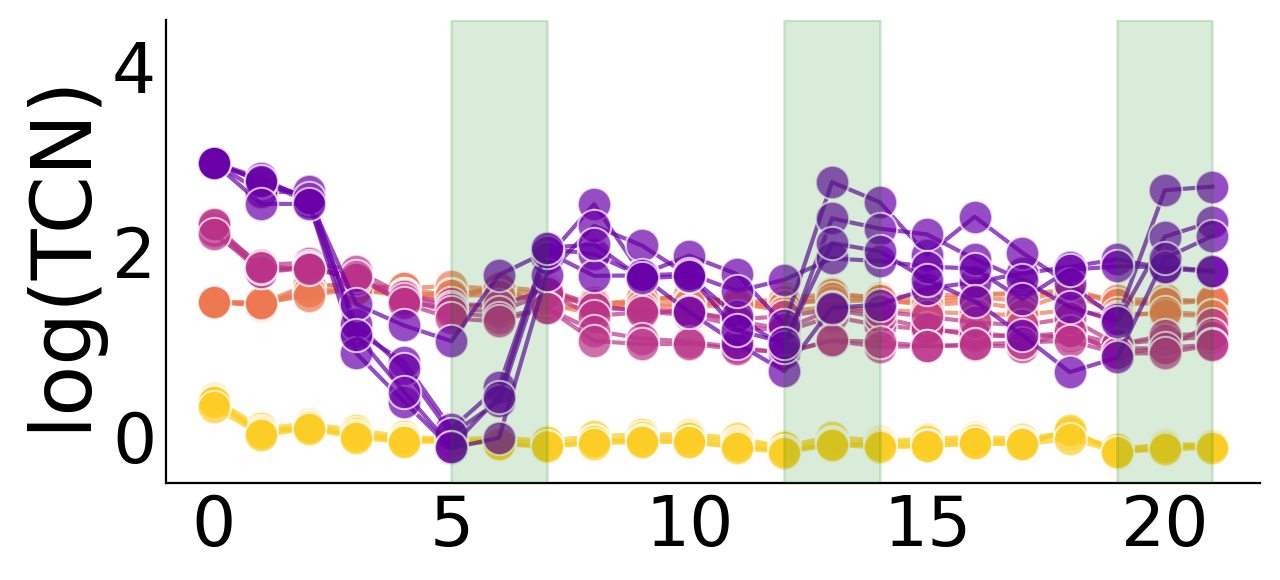

In [33]:
## Experimental conditions: +Kan

# Set up figure size
plt.figure(figsize=(6.5, 3), dpi=200)

# Create line plot with points
ax_Kan_TCN = sns.lineplot(
    data=df_main,
    x='Day',
    y='log(transposon copy)',
    hue='PCN',  
    units='ExpRep',  # Creates separate lines for each ExpRep (detail in Altair)
    estimator=None,  # Don't aggregate data points
    marker='o',      # Add markers on the line
    markersize=12,   # Large marker size
    alpha=0.7,       # Match opacity from Altair
    palette=colors,
    legend=False     # No legend as in original
)

add_treatment_windows(ax_Kan_TCN)

# Set axis limits to match Altair scales
plt.xlim(-1, 22)
plt.ylim(-0.5, 4.5)

# Configure axis appearance
ax_Kan_TCN.tick_params(axis='x', labelsize=25, length=0)
ax_Kan_TCN.tick_params(axis='y', labelsize=25, length=0)
plt.xticks([0, 5, 10, 15, 20])  # 5 tick marks
plt.yticks([0, 2, 4])  # 3 tick marks
plt.xlabel('')
plt.ylabel('log(TCN)', fontsize=30)
plt.grid(False)

# Remove spines to match minimal Altair style
sns.despine(left=False, bottom=False, right=True, top=True)

# Use tight layout to optimize spacing
plt.tight_layout()

plt.savefig('Figures_final/supplementary/SF8C-No_transposase_K_TCN.pdf', format="pdf", bbox_inches="tight")

# Display plot
plt.show()

### Supplementary Figure 8
**Saved outputs:** `SF8C-No_transposase_noK_TCN.pdf`

/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_67811/3672900952.py:7: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  ax_noKan_TCN = sns.lineplot(


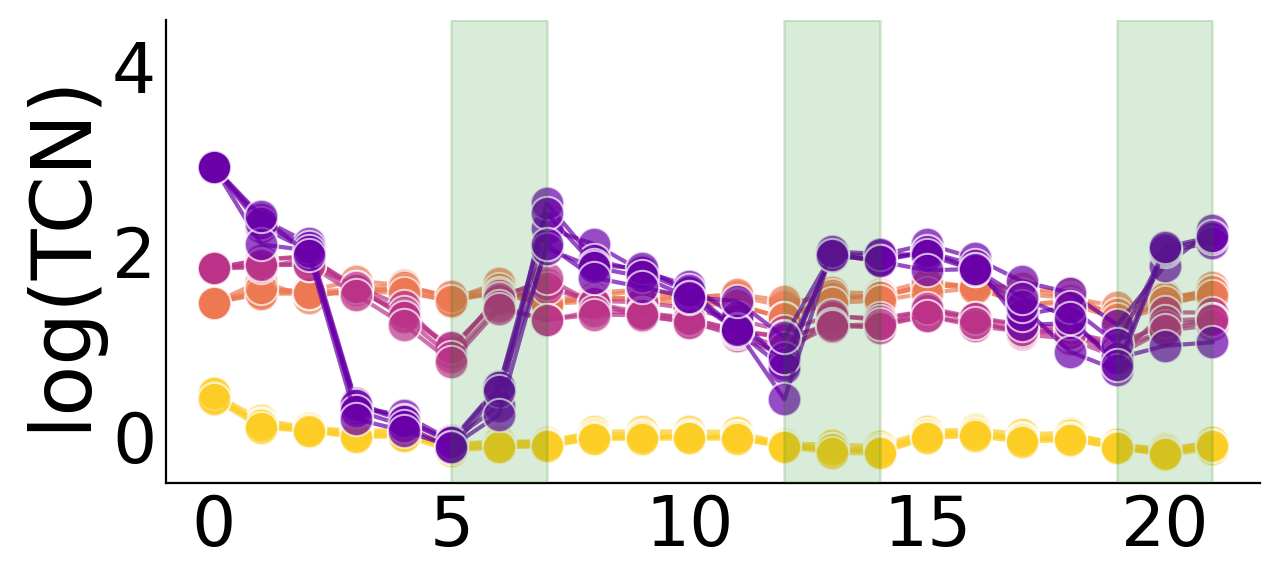

In [34]:
## Experimental conditions: -Kan

# Set up figure size
plt.figure(figsize=(6.5, 3), dpi=200)

# Create line plot with points
ax_noKan_TCN = sns.lineplot(
    data=df_main_noKan,
    x='Day',
    y='log(transposon copy)',
    hue='PCN',  
    units='ExpRep',  # Creates separate lines for each ExpRep (detail in Altair)
    estimator=None,  # Don't aggregate data points
    marker='o',      # Add markers on the line
    markersize=12,   # Large marker size
    alpha=0.7,       # Match opacity from Altair
    palette=colors,
    legend=False     # No legend as in original
)

add_treatment_windows(ax_noKan_TCN)

# Set axis limits to match Altair scales
plt.xlim(-1, 22)
plt.ylim(-0.5, 4.5)

# Configure axis appearance
ax_noKan_TCN.tick_params(axis='x', labelsize=25, length=0)
ax_noKan_TCN.tick_params(axis='y', labelsize=25, length=0)
plt.xticks([0, 5, 10, 15, 20])  # 5 tick marks
plt.yticks([0, 2, 4])  # 3 tick marks
plt.xlabel('')
plt.ylabel('log(TCN)', fontsize=30)
plt.grid(False)

# Remove spines to match minimal Altair style
sns.despine(left=False, bottom=False, right=True, top=True)

# Use tight layout to optimize spacing
plt.tight_layout()

plt.savefig('Figures_final/supplementary/SF8C-No_transposase_noK_TCN.pdf', format="pdf", bbox_inches="tight")

# Display plot
plt.show()

In [35]:
# Calculate PCN by averaging over everyday
tet10_kan_DF_Use_grouped.groupby(['PCN'])['plasmid copy'].mean()

# Combine 2 dataframes for further analysis
tet10_kan_DF_Use_grouped['Kan'] = 'Kan'
tet10_noKan_DF_Use_grouped['Kan'] = 'noKan'

combined_data = pd.concat([tet10_kan_DF_Use_grouped, tet10_noKan_DF_Use_grouped])

In [36]:
# Calculate loss rates
def calculateLossRate(df, qPCRtarget):
    # Make pairs of (Up day, Down day)
    up_down_pair = list(zip(UP_DAYS[:], DOWN_DAYS[:]))

    # Process each plasmid
    for plasmid in PlasmidList:
        if plasmid != 'p15A':
            print(plasmid)
            # Process each pair
            for pair in up_down_pair:
                print(pair)
                # Selection Day result
                denominator = df[(df['Day'] == pair[0]) & (df['PCN'] == plasmid)][qPCRtarget]
                # The last day of no selection After the selection day
                numerator = df[(df['Day'] == pair[1]) & (df['PCN'] == plasmid)][qPCRtarget]

                # Ensure the indexes align
                denominator = denominator.reset_index(drop=True)
                numerator = numerator.reset_index(drop=True)

                # To make the value positive
                loss = denominator/numerator

                loss = loss.dropna()

                indices = df[(df['Day'] == pair[1]) & (df['PCN'] == plasmid)].index

                # Assign the calculated loss back
                df.loc[indices, 'loss'] = loss.values

                # Take mean of all days  
                df.loc[indices, 'mean of loss'] = np.mean(df.loc[indices, 'loss'])

                # Calculate the rate & stats
                generation = LossTreatmentDays * np.log2(TreatmentDilution)    
                loss_rate = np.log(loss)/generation
                loss_rate_mean = np.mean(loss_rate)
                loss_rate_std = np.std(loss_rate)

                # Assign calculated loss rate & stats values to the df
                df.loc[indices, 'rate_of_loss_log('+qPCRtarget+')'] = loss_rate.values
                df.loc[indices, 'mean_of_loss_rate(log('+qPCRtarget+'))'] = loss_rate_mean
                df.loc[indices, 'std_of_loss_rate(log('+qPCRtarget+'))'] = loss_rate_std
                df.loc[indices, 'ci_lower('+qPCRtarget+')'] = loss_rate_mean - loss_rate_std
                df.loc[indices, 'ci_upper('+qPCRtarget+')'] = loss_rate_mean + loss_rate_std

    df = df.fillna(np.nan)

    return df

In [37]:
def makeLossPlotDFs(currentCompleteDF):
    currentCompleteDF_lossCopy = currentCompleteDF.copy(deep=True)
    # for the transposon result
    currentCompleteDF_loss_transposon_df = calculateLossRate(currentCompleteDF_lossCopy, 'transposon copy')
    print(currentCompleteDF_loss_transposon_df)
    # for the plasmid result
    currentCompleteDF_loss_plasmid_df = calculateLossRate(currentCompleteDF_lossCopy, 'plasmid copy')
    # for the T/P result
    currentCompleteDF_loss_ratio_df = calculateLossRate(currentCompleteDF_lossCopy, 'T/P')

    # To postprocess for ploting
    currentCompleteDF_loss_transposon_df_cleaned_scatter = currentCompleteDF_loss_transposon_df.groupby(['PCN','ExpRep'])[['rate_of_loss_log(transposon copy)']].mean().reset_index().dropna()

    currentCompleteDF_loss_plasmid_df_cleaned_scatter = currentCompleteDF_loss_plasmid_df.groupby(['PCN','ExpRep'])[['rate_of_loss_log(plasmid copy)']].mean().reset_index().dropna()

    currentCompleteDF_loss_ratio_df_cleaned_scatter = currentCompleteDF_loss_ratio_df.groupby(['PCN','ExpRep'])[['rate_of_loss_log(T/P)']].mean().reset_index().dropna()

    # Identify overlapping column names
    overlapping_columns = set(currentCompleteDF_loss_transposon_df_cleaned_scatter.columns) & set(currentCompleteDF_loss_plasmid_df_cleaned_scatter.columns) & set(currentCompleteDF_loss_ratio_df_cleaned_scatter.columns)

    # Concatenate DataFrames horizontally, keeping only one occurrence of overlapping columns
    result_df = pd.concat([currentCompleteDF_loss_transposon_df_cleaned_scatter, currentCompleteDF_loss_plasmid_df_cleaned_scatter.loc[:, ~currentCompleteDF_loss_plasmid_df_cleaned_scatter.columns.isin(overlapping_columns)]], axis=1)

    result_df = pd.concat([result_df, currentCompleteDF_loss_ratio_df_cleaned_scatter.loc[:, ~currentCompleteDF_loss_ratio_df_cleaned_scatter.columns.isin(overlapping_columns)]], axis=1)

    return result_df

In [38]:
scatter_kan = makeLossPlotDFs(tet10_kan_DF_Use_grouped)
scatter_noKan = makeLossPlotDFs(tet10_noKan_DF_Use_grouped)

scatter_kan['Kan'] = 1
scatter_noKan['Kan'] = 0

combined_scatter_DF = pd.concat([scatter_kan, scatter_noKan])

combined_scatter_DF['PCN'] = pd.Series(combined_scatter_DF['PCN'], dtype="category")
combined_scatter_DF["PCN"] = combined_scatter_DF["PCN"].cat.reorder_categories(
                [
                'p15A-+',
                'pBR-+',
                'CloDF-+',
                'pUC-+',
                'p15A++',
                ],
            ordered=True,
                )

p15A-+
(0, 5)
(7, 12)
(14, 19)
pBR-+
(0, 5)
(7, 12)
(14, 19)
CloDF-+
(0, 5)
(7, 12)
(14, 19)
pUC-+
(0, 5)
(7, 12)
(14, 19)
p15A++
(0, 5)
(7, 12)
(14, 19)
     Day ExpRep      PCN  log(transposon copy)  log(plasmid copy)  \
0      0      1   p15A-+              0.417081           1.216058   
1      0      1    pBR-+              1.457287           1.474816   
2      0      1  CloDF-+              2.246893           2.334983   
3      0      1    pUC-+              2.959971           3.749673   
4      0      1   p15A++              0.186134           1.589980   
..   ...    ...      ...                   ...                ...   
545   21      5   p15A-+             -0.118324           1.302659   
546   21      5    pBR-+              1.315715           1.282980   
547   21      5  CloDF-+              0.993649           0.974208   
548   21      5    pUC-+              2.168870           2.935258   
549   21      5   p15A++              0.184777           1.464098   

     transposon c

/Library/Frameworks/Python.framework/Versions/3.8/lib/python3.8/site-packages/pandas/core/arraylike.py:397: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Library/Frameworks/Python.framework/Versions/3.8/lib/python3.8/site-packages/pandas/core/arraylike.py:397: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Library/Frameworks/Python.framework/Versions/3.8/lib/python3.8/site-packages/pandas/core/arraylike.py:397: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Library/Frameworks/Python.framework/Versions/3.8/lib/python3.8/site-packages/pandas/core/arraylike.py:397: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [39]:
# Transposon loss rate per generation

alt.Chart(combined_scatter_DF).mark_point(size=70).encode(
    alt.X("PCN", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title=None),
    alt.Y("rate_of_loss_log(transposon copy)", scale=alt.Scale(domain=[-0.02, 0.33]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, ticks=False, grid=False), title=None),
    color=alt.Color('PCN', ).scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    width=150,
    height=150
).configure_header(
    labelFontSize=20  # Adjust this value to change the subtitle size
).properties(
    title=alt.TitleParams(
        text='Transposon loss rate',
        fontSize=20,
        fontWeight='bold',
        # color='grey',
        anchor='middle'
    )
).interactive()

alt.Chart(...)

In [40]:
# plasmid loss rate per generation, PCN

alt.Chart(combined_scatter_DF).mark_point(size=70).encode(
    alt.X("PCN", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title=None),
    alt.Y("rate_of_loss_log(plasmid copy)", axis=alt.Axis(labelFontSize=30, titleFontSize=15, ticks=False, grid=False), title=None),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    width=150, 
    height=150
).configure_header(
    labelFontSize=20  # Adjust this value to change the subtitle size
).properties(
    title=alt.TitleParams(
        text='Plasmid loss rate',
        fontSize=20,
        fontWeight='bold',
        # color='grey',
        anchor='middle'
    )
).interactive()

alt.Chart(...)

In [41]:
# T/P loss rate per generation

alt.Chart(combined_scatter_DF).mark_point(size=70).encode(
    alt.X("PCN", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title=None),
    alt.Y("rate_of_loss_log(T/P)", axis=alt.Axis(labelFontSize=30, titleFontSize=15, ticks=False, grid=False), title=None),

    color=alt.Color('PCN',).scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    width=150,
    height=150
).configure_header(
    labelFontSize=20  # Adjust this value to change the subtitle size
).properties(
    title=alt.TitleParams(
        text='T/P loss rate',
        fontSize=20,
        fontWeight='bold',
        # color='grey',
        anchor='middle'
    )
).interactive()

alt.Chart(...)

In [42]:
# Calculate the averaged PCN
averagePCN = pd.DataFrame(tet10_noKan_DF_Use_grouped.groupby(['PCN'])['plasmid copy'].mean()).reset_index()

combined_scatter_DF.loc[combined_scatter_DF['PCN'] == 'p15A-+', 'averagePCN'] = averagePCN[averagePCN['PCN'] == 'p15A-+']['plasmid copy'].values[0]
combined_scatter_DF.loc[combined_scatter_DF['PCN'] == 'pBR-+', 'averagePCN'] = averagePCN[averagePCN['PCN'] == 'pBR-+']['plasmid copy'].values[0]
combined_scatter_DF.loc[combined_scatter_DF['PCN'] == 'CloDF-+', 'averagePCN'] = averagePCN[averagePCN['PCN'] == 'CloDF-+']['plasmid copy'].values[0]
combined_scatter_DF.loc[combined_scatter_DF['PCN'] == 'pUC-+', 'averagePCN'] = averagePCN[averagePCN['PCN'] == 'pUC-+']['plasmid copy'].values[0]
combined_scatter_DF.loc[combined_scatter_DF['PCN'] == 'p15A++', 'averagePCN'] = averagePCN[averagePCN['PCN'] == 'p15A++']['plasmid copy'].values[0]

In [43]:
averagePCN_rep_noKan_noT = tet10_noKan_DF_Use_grouped.groupby(['PCN', 'ExpRep'])['plasmid copy'].mean().reset_index(name='replicate_averagePCN')

combined_scatter_DF['replicate_averagePCN'] = np.nan
combined_scatter_DF.loc[combined_scatter_DF['Kan'] == 0, 'replicate_averagePCN'] = (
    combined_scatter_DF.loc[combined_scatter_DF['Kan'] == 0, ['PCN', 'ExpRep']]
    .merge(averagePCN_rep_noKan_noT, on=['PCN', 'ExpRep'], how='left')['replicate_averagePCN'].values
)

In [44]:
averagePCN_rep_kan_noT = tet10_kan_DF_Use_grouped.groupby(['PCN', 'ExpRep'])['plasmid copy'].mean().reset_index(name='replicate_averagePCN')

combined_scatter_DF.loc[combined_scatter_DF['Kan'] == 1, 'replicate_averagePCN'] = (
    combined_scatter_DF.loc[combined_scatter_DF['Kan'] == 1, ['PCN', 'ExpRep']]
    .merge(averagePCN_rep_kan_noT, on=['PCN', 'ExpRep'], how='left')['replicate_averagePCN'].values
)

In [45]:
TCN_loss_PCNasX = alt.Chart(combined_scatter_DF).mark_point(size=70).encode(
    alt.X("averagePCN", axis=alt.Axis(labelFontSize=25, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_loss_log(transposon copy)", scale=alt.Scale(domain=[0, 0.33]), axis=alt.Axis(labelFontSize=25, titleFontSize=15, grid=False), title='loss rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='TCN',
    width=200,
    height=200
)

PCN_loss_PCNasX = alt.Chart(combined_scatter_DF).mark_point(size=70).encode(
    alt.X("averagePCN", axis=alt.Axis(labelFontSize=25, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_loss_log(plasmid copy)", scale=alt.Scale(domain=[0, 0.33]), axis=alt.Axis(labelFontSize=25, titleFontSize=15, grid=False), title='loss rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='PCN',
    width=200,
    height=200
)

Ratio_loss_PCNasX = alt.Chart(combined_scatter_DF).mark_point(size=70).encode(
    alt.X("averagePCN", axis=alt.Axis(labelFontSize=25, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_loss_log(T/P)", scale=alt.Scale(domain=[0, 0.33]), axis=alt.Axis(labelFontSize=25, titleFontSize=15, grid=False), title='loss rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='T/P',
    width=200,
    height=200
)

Loss_combined_PCNasX_chart = TCN_loss_PCNasX | PCN_loss_PCNasX | Ratio_loss_PCNasX

Loss_combined_PCNasX_chart.interactive()

alt.HConcatChart(...)

In [46]:
# Calculate gain rates
def calculateGainRate(df, qPCRtarget):
    # Make pairs of (Up day, Down day)
    up_down_pair = list(zip(UP_DAYS[1:], DOWN_DAYS[:]))

    # Process each plasmid
    for plasmid in PlasmidList:
        if plasmid != 'p15A':
            # Process each pair
            for pair in up_down_pair:
                # Selection Day result
                numerator = df[(df['Day'] == pair[0]) & (df['PCN'] == plasmid)][qPCRtarget]
                # The last day of no selection After the selection day
                denominator = df[(df['Day'] == pair[1]) & (df['PCN'] == plasmid)][qPCRtarget]
                # Ensure the indexes align
                denominator = denominator.reset_index(drop=True)
                numerator = numerator.reset_index(drop=True)
                gain = numerator/denominator       
                gain = gain.dropna()

                indices = df[(df['Day'] == pair[0]) & (df['PCN'] == plasmid)].index

                # Assign the calculated gain back
                df.loc[indices, 'gain'] = gain.values

                # Take mean of all days  
                df.loc[indices, 'mean of gain'] = np.mean(df.loc[indices, 'gain'])

                # Calculate the rate & stats
                generation = SelectionTreatmentDays * np.log2(TreatmentDilution)    
                gain_rate = np.log(gain)/generation
                gain_rate_mean = np.mean(gain_rate)
                gain_rate_std = np.std(gain_rate)

                # Assign calculated gain rate & stats values to the df
                df.loc[indices, 'rate_of_gain_log('+qPCRtarget+')'] = gain_rate.values
                df.loc[indices, 'mean_of_gain_rate(log('+qPCRtarget+'))'] = gain_rate_mean
                df.loc[indices, 'std_of_gain_rate(log('+qPCRtarget+'))'] = gain_rate_std
                df.loc[indices, 'ci_lower('+qPCRtarget+')'] = gain_rate_mean - gain_rate_std
                df.loc[indices, 'ci_upper('+qPCRtarget+')'] = gain_rate_mean + gain_rate_std

    df = df.fillna(np.nan)

    return df

In [47]:
def makeGainPlotDFs(currentCompleteDF):
    currentCompleteDF_gainCopy = currentCompleteDF.copy(deep=True)
    # for the transposon result
    currentCompleteDF_gain_transposon_df = calculateGainRate(currentCompleteDF_gainCopy, 'transposon copy')
    # for the plasmid result
    currentCompleteDF_gain_plasmid_df = calculateGainRate(currentCompleteDF_gainCopy, 'plasmid copy')
    # for the T/P result
    currentCompleteDF_gain_ratio_df = calculateGainRate(currentCompleteDF_gainCopy, 'T/P')

    # To postprocess for ploting
    currentCompleteDF_gain_transposon_df_cleaned_scatter = currentCompleteDF_gain_transposon_df.groupby(['PCN','ExpRep'])[['rate_of_gain_log(transposon copy)']].mean().reset_index().dropna()

    currentCompleteDF_gain_plasmid_df_cleaned_scatter = currentCompleteDF_gain_plasmid_df.groupby(['PCN','ExpRep'])[['rate_of_gain_log(plasmid copy)']].mean().reset_index().dropna()

    currentCompleteDF_gain_ratio_df_cleaned_scatter = currentCompleteDF_gain_ratio_df.groupby(['PCN','ExpRep'])[['rate_of_gain_log(T/P)']].mean().reset_index().dropna()

    # Identify overlapping column names
    overlapping_columns = set(currentCompleteDF_gain_transposon_df_cleaned_scatter.columns) & set(currentCompleteDF_gain_plasmid_df_cleaned_scatter.columns) & set(currentCompleteDF_gain_ratio_df_cleaned_scatter.columns)

    # Concatenate DataFrames horizontally, keeping only one occurrence of overlapping columns
    result_df = pd.concat([currentCompleteDF_gain_transposon_df_cleaned_scatter, currentCompleteDF_gain_plasmid_df_cleaned_scatter.loc[:, ~currentCompleteDF_gain_plasmid_df_cleaned_scatter.columns.isin(overlapping_columns)]], axis=1)

    result_df = pd.concat([result_df, currentCompleteDF_gain_ratio_df_cleaned_scatter.loc[:, ~currentCompleteDF_gain_ratio_df_cleaned_scatter.columns.isin(overlapping_columns)]], axis=1)

    return result_df

In [48]:
scatter_gain_kan = makeGainPlotDFs(tet10_kan_DF_Use_grouped)
scatter_gain_noKan = makeGainPlotDFs(tet10_noKan_DF_Use_grouped)

scatter_gain_kan['Kan'] = 1
scatter_gain_noKan['Kan'] = 0

combined_scatter_gain_DF = pd.concat([scatter_gain_kan, scatter_gain_noKan])

combined_scatter_gain_DF['PCN'] = pd.Series(combined_scatter_gain_DF['PCN'], dtype="category")
combined_scatter_gain_DF["PCN"] = combined_scatter_gain_DF["PCN"].cat.reorder_categories(
                [
                'p15A-+',
                'pBR-+',
                'CloDF-+',
                'pUC-+',
                'p15A++'
                ],
            ordered=True,
                )

/Library/Frameworks/Python.framework/Versions/3.8/lib/python3.8/site-packages/pandas/core/arraylike.py:397: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Library/Frameworks/Python.framework/Versions/3.8/lib/python3.8/site-packages/pandas/core/arraylike.py:397: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [49]:
combined_scatter_gain_DF.loc[combined_scatter_DF['PCN'] == 'p15A-+', 'averagePCN'] = averagePCN[averagePCN['PCN'] == 'p15A-+']['plasmid copy'].values[0]
combined_scatter_gain_DF.loc[combined_scatter_DF['PCN'] == 'pBR-+', 'averagePCN'] = averagePCN[averagePCN['PCN'] == 'pBR-+']['plasmid copy'].values[0]
combined_scatter_gain_DF.loc[combined_scatter_DF['PCN'] == 'CloDF-+', 'averagePCN'] = averagePCN[averagePCN['PCN'] == 'CloDF-+']['plasmid copy'].values[0]
combined_scatter_gain_DF.loc[combined_scatter_DF['PCN'] == 'pUC-+', 'averagePCN'] = averagePCN[averagePCN['PCN'] == 'pUC-+']['plasmid copy'].values[0]
combined_scatter_gain_DF.loc[combined_scatter_DF['PCN'] == 'p15A++', 'averagePCN'] = averagePCN[averagePCN['PCN'] == 'p15A++']['plasmid copy'].values[0]

In [50]:
# Gain, TCN

alt.Chart(combined_scatter_gain_DF).mark_point(size=70).encode(
    alt.X("PCN", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title=None),
    alt.Y("rate_of_gain_log(transposon copy)", scale=alt.Scale(domain=[-0.01, 0.42]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, tickCount = 3, ticks=False, grid=False), title=None),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='TCN gain rate',
    width=150,
    height=150
).interactive()

alt.Chart(...)

In [51]:
# Gain, PCN

alt.Chart(combined_scatter_gain_DF).mark_point(size=70).encode(
    alt.X("PCN", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title=None),
    alt.Y("rate_of_gain_log(plasmid copy)", scale=alt.Scale(domain=[-0.01, 0.24]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, tickCount = 3, ticks=False, grid=False), title=None),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='PCN gain rate',
    width=150,
    height=150
).interactive()

alt.Chart(...)

In [52]:
# T/P, gain

alt.Chart(combined_scatter_gain_DF).mark_point(size=70).encode(
    alt.X("PCN", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title=None),
    alt.Y("rate_of_gain_log(T/P)", axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title=None),
    color=alt.Color('PCN', legend=None).scale(scheme=colorScheme,reverse=True),
   shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='T/P gain rate',
    width=150,
    height=150
).interactive()

alt.Chart(...)

In [53]:
TCN_gain = alt.Chart(combined_scatter_gain_DF).mark_point(size=70).encode(
    alt.X("PCN", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_gain_log(transposon copy)", scale=alt.Scale(domain=[0, 0.3]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='gain rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='TCN',
    width=200,
    height=200
)

PCN_gain = alt.Chart(combined_scatter_gain_DF).mark_point(size=70).encode(
    alt.X("PCN", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_gain_log(plasmid copy)", scale=alt.Scale(domain=[0, 0.3]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='gain rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='PCN',
    width=200,
    height=200
)

Ratio_gain = alt.Chart(combined_scatter_gain_DF).mark_point(size=70).encode(
    alt.X("PCN", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_gain_log(T/P)", scale=alt.Scale(domain=[0, 0.3]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='gain rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
   shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='T/P',
    width=200,
    height=200
)

Gain_combined_chart = TCN_gain | PCN_gain | Ratio_gain

Gain_combined_chart.interactive()

alt.HConcatChart(...)

In [54]:
TCN_gain_PCNasX = alt.Chart(combined_scatter_gain_DF).mark_point(size=70).encode(
    alt.X("averagePCN", axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_gain_log(transposon copy)", scale=alt.Scale(domain=[0, 0.3]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='gain rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='TCN',
    width=200,
    height=200
)

PCN_gain_PCNasX = alt.Chart(combined_scatter_gain_DF).mark_point(size=70).encode(
    alt.X("averagePCN", axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_gain_log(plasmid copy)", scale=alt.Scale(domain=[0, 0.3]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='gain rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='PCN',
    width=200,
    height=200
)

Ratio_gain_PCNasX = alt.Chart(combined_scatter_gain_DF).mark_point(size=70).encode(
    alt.X("averagePCN", axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_gain_log(T/P)", scale=alt.Scale(domain=[0, 0.3]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='gain rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='T/P',
    width=200,
    height=200
)

Gain_combined_PCNasX_chart = TCN_gain_PCNasX | PCN_gain_PCNasX | Ratio_gain_PCNasX

Gain_combined_PCNasX_chart.interactive()

alt.HConcatChart(...)

In [55]:
TCN_gain_PCNasX = alt.Chart(combined_scatter_gain_DF).mark_point(size=70).encode(
    alt.X("averagePCN", scale=alt.Scale(type='log'), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_gain_log(transposon copy)", scale=alt.Scale(domain=[0, 0.3]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='gain rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='TCN',
    width=200,
    height=200
)

PCN_gain_PCNasX = alt.Chart(combined_scatter_gain_DF).mark_point(size=70).encode(
    alt.X("averagePCN", scale=alt.Scale(type='log'), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_gain_log(plasmid copy)", scale=alt.Scale(domain=[0, 0.3]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='gain rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='PCN',
    width=200,
    height=200
)

Ratio_gain_PCNasX = alt.Chart(combined_scatter_gain_DF).mark_point(size=70).encode(
    alt.X("averagePCN", scale=alt.Scale(type='log'), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_gain_log(T/P)", scale=alt.Scale(domain=[0, 0.3]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='gain rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='T/P',
    width=200,
    height=200
)

Gain_combined_PCNasX_chart = TCN_gain_PCNasX | PCN_gain_PCNasX | Ratio_gain_PCNasX

Gain_combined_PCNasX_chart.interactive()

alt.HConcatChart(...)

In [56]:
# Assign Jumping column: 0 if '-' is at end or second-to-last position
combined_scatter_gain_DF_toSave = combined_scatter_gain_DF.copy(deep=True)
combined_scatter_gain_DF_toSave = combined_scatter_gain_DF_toSave[combined_scatter_gain_DF_toSave['PCN'] != 'p15A++']
combined_scatter_gain_DF_toSave['Jumping'] = combined_scatter_gain_DF_toSave['PCN'].str.contains('-.{0,1}$').astype(int).replace({1: 0, 0: 1})

# Remove trailing '-' and '+' from PCN column (as before)
combined_scatter_gain_DF_toSave['PCN'] = combined_scatter_gain_DF_toSave['PCN'].str.replace('[-+]$', '', regex=True)
combined_scatter_gain_DF_toSave['PCN'] = combined_scatter_gain_DF_toSave['PCN'].str.replace('[-+]$', '', regex=True)
combined_scatter_gain_DF_toSave

,PCN,ExpRep,rate_of_gain_log(transposon copy),rate_of_gain_log(plasmid copy),rate_of_gain_log(T/P),Kan,averagePCN,Jumping
0,p15A,1,0.002380,-0.007844,-0.000664,1,17.218361,0
1,p15A,2,0.001527,-0.000449,-0.001152,1,17.218361,0
2,p15A,3,0.001636,0.001007,-0.001653,1,17.218361,0
3,p15A,4,0.001931,-0.002216,-0.000443,1,17.218361,0
4,p15A,5,0.001032,-0.003811,0.005676,1,17.218361,0
5,pBR,1,0.001637,-0.005247,0.006957,1,31.711108,0
6,pBR,2,-0.001278,-0.006927,0.005527,1,31.711108,0
7,pBR,3,-0.000506,-0.004435,0.004006,1,31.711108,0
8,pBR,4,-0.001827,-0.007509,0.005614,1,31.711108,0
9,pBR,5,-0.000035,-0.006242,0.006209,1,31.711108,0


In [57]:
# Assign Jumping column: 0 if '-' is at end or second-to-last position
combined_scatter_DF_toSave = combined_scatter_DF.copy(deep=True)
combined_scatter_DF_toSave = combined_scatter_DF_toSave[combined_scatter_DF_toSave['PCN'] != 'p15A++']

combined_scatter_DF_toSave['Jumping'] = combined_scatter_DF_toSave['PCN'].str.contains('-.{0,1}$').astype(int).replace({1: 0, 0: 1})

# Remove trailing '-' and '+' from PCN column (as before)
combined_scatter_DF_toSave['PCN'] = combined_scatter_DF_toSave['PCN'].str.replace('[-+]$', '', regex=True)
combined_scatter_DF_toSave['PCN'] = combined_scatter_DF_toSave['PCN'].str.replace('[-+]$', '', regex=True)
combined_scatter_DF_toSave

,PCN,ExpRep,rate_of_loss_log(transposon copy),rate_of_loss_log(plasmid copy),rate_of_loss_log(T/P),Kan,averagePCN,replicate_averagePCN,Jumping
0,p15A,1,0.006289,-0.005102,-0.008025,1,17.218361,24.097861,0
1,p15A,2,0.005654,-0.001638,-0.005797,1,17.218361,22.637137,0
2,p15A,3,0.005716,-0.001469,-0.003795,1,17.218361,25.082958,0
3,p15A,4,0.005734,-0.001952,-0.003283,1,17.218361,24.650220,0
4,p15A,5,0.005035,-0.002417,-0.002432,1,17.218361,21.866356,0
5,pBR,1,0.000544,-0.001107,0.001711,1,31.711108,31.511257,0
6,pBR,2,-0.000533,-0.002254,0.001697,1,31.711108,32.760184,0
7,pBR,3,-0.000465,-0.001655,0.001218,1,31.711108,30.704262,0
8,pBR,4,0.000834,-0.000926,0.001820,1,31.711108,30.123892,0
9,pBR,5,0.001440,-0.000495,0.002024,1,31.711108,27.831797,0


In [58]:
# Export processed data for final plotting
combined_scatter_gain_DF_toSave.to_csv('noJumping_gain_qPCR_r.csv', index=False)
combined_scatter_DF_toSave.to_csv('noJumping_loss_qPCR_r.csv', index=False)

In [59]:
# Export raw data too
combined_data.to_csv('rawData_r.csv', index=False)

# GFP without Transposase

In [60]:
## excel format and the fluoresence gain one chose
## Check this for each exp, can vary slightly according to platereader setting
OD_START_ROW = 28
GFP_START_ROW = 90

## The end of each treatment course
UP_DAYS = [0, 7, 14, 21]
DOWN_DAYS = [5, 12, 19]

TreatmentDilution = 30000
LossTreatmentDays = 5
SelectionTreatmentDays = 2
PlasmidList = ["p15A", "pBR322", "CloDF13", "pUC", "p15A+", "Chromosome"] 

colorScheme = 'plasma'

In [61]:
# Assign files to their corresponding dates
Day0 = 'GFP_withoutTransposase/09112025_revision_D0.xlsx'
Day1 = 'GFP_withoutTransposase/09122025_revision_D1.xlsx'
Day2 = 'GFP_withoutTransposase/09132025_revision_D2.xlsx'
Day3 = 'GFP_withoutTransposase/09142025_revision_D3.xlsx'
Day4 = 'GFP_withoutTransposase/09152025_revision_D4.xlsx'
Day5 = 'GFP_withoutTransposase/09162025_revision_D5.xlsx'
Day6 = 'GFP_withoutTransposase/09172025_revision_D6.xlsx'
Day7 = 'GFP_withoutTransposase/09182025_revision_D7.xlsx'
Day8 = 'GFP_withoutTransposase/09192025_revision_D8.xlsx'
Day9 = 'GFP_withoutTransposase/09202025_revision_D9.xlsx'
Day10 = 'GFP_withoutTransposase/09212025_revision_D10.xlsx'
Day11 = 'GFP_withoutTransposase/09222025_revision_D11.xlsx'
Day12 = 'GFP_withoutTransposase/09232025_revision_D12.xlsx'
Day13 = 'GFP_withoutTransposase/09242025_revision_D13.xlsx'
Day14 = 'GFP_withoutTransposase/09252025_revision_D14.xlsx'
Day15 = 'GFP_withoutTransposase/09262025_revision_D15.xlsx'
Day16 = 'GFP_withoutTransposase/09272025_revision_D16.xlsx'
Day17 = 'GFP_withoutTransposase/09282025_revision_D17.xlsx'
Day18 = 'GFP_withoutTransposase/09292025_revision_D18.xlsx'
Day19 = 'GFP_withoutTransposase/09302025_revision_D19.xlsx'
Day20 = 'GFP_withoutTransposase/10012025_revision_D20.xlsx'
Day21 = 'GFP_withoutTransposase/10022025_revision_D21.xlsx'

datafiles = [Day0, Day1, Day2, Day3, Day4, Day5, Day6, Day7, Day8, Day9, Day10, Day11, Day12, Day13, Day14, Day15, Day16, Day17, Day18, Day19, Day20, Day21]

In [62]:
### Import data without transposase from data made for first round submission.
### It has cells with one transposase on the chromosome data
noJumping_rawData_GFP_df = pd.read_csv('GFP_withoutTransposase/noJumping_rawData_GFP.csv')

In [63]:
def prepare_metadata(plate_metadata_path):
    metadata_df = pd.read_csv(plate_metadata_path, index_col='<>').rename_axis('PlateRow').reset_index().melt(id_vars=['PlateRow'], var_name='PlateColumn', value_name='Sample')

    metadata_df['Well'] = metadata_df['PlateRow'].astype(str) + metadata_df['PlateColumn'].astype(str)

    metadata_df = metadata_df.drop(columns=['PlateRow', 'PlateColumn'])

    return metadata_df

In [64]:
def duplicate_and_modify(df, column, value, new_values):
    # Find rows that match the condition
    mask = df[column] == value

    # Create a list to store the new rows
    new_rows = []

    # Iterate through matching rows
    for idx, row in df[mask].iterrows():
        # Create duplicates with modified values
        for new_value in new_values:
            new_row = row.copy()
            new_row[column] = new_value
            new_rows.append(new_row)

    # Create a new DataFrame with the new rows
    new_df = pd.DataFrame(new_rows)

    # Combine the new DataFrame with the original, excluding the original matching rows
    mask_inverse = df[df[column] != value]
    result = pd.concat([mask_inverse, new_df], ignore_index=True)

    return result

In [65]:
def duplicate_and_modify_rows(df, condition_column, condition_value, modify_column, new_value):
    """
    Duplicates rows where condition_column equals condition_value,
    and changes the value in modify_column for the duplicated rows.

    :param df: The input DataFrame
    :param condition_column: The column to check for the condition
    :param condition_value: The value to match in the condition column
    :param modify_column: The column to modify in the duplicated rows
    :param new_value: The new value to set in the modified column
    :return: The modified DataFrame
    """
    # Create a mask for rows that meet the condition
    mask = df[condition_column] == condition_value

    # Duplicate the rows that meet the condition
    duplicated_rows = df[mask].copy()

    # Modify the specified column in the duplicated rows
    duplicated_rows[modify_column] = new_value

    # Concatenate the original DataFrame with the duplicated and modified rows
    result_df = pd.concat([df, duplicated_rows], ignore_index=True)

    # Sort the DataFrame to keep the duplicated rows next to their originals
    result_df = result_df.sort_index().reset_index(drop=True)

    return result_df

In [66]:
def prepare_plate_data(excel_filepath, sheetName, day):
    ## import plate layout metadata
    print(day)
    ## Special treatment for tet10, since it does not have the psc101 data
    if excel_filepath == Day0:
        metadata_df = prepare_metadata("GFP_withoutTransposase/plate-layout-metadata_Day0.csv")

        ## OD600 data
        my_OD_df = (
            pd.read_excel(
                excel_filepath,
                sheet_name=sheetName,
                skiprows=OD_START_ROW - 1,
                nrows=3,
                usecols=list(range(0, 12)),
                index_col="<>",
            )
            .rename_axis("PlateRow")
            .reset_index()
            .melt(
                id_vars=["PlateRow"], var_name="PlateColumn", value_name="OD"
            )
        )

        ## GFP data
        my_GFP_df = (
            pd.read_excel(
                excel_filepath,
                sheet_name=sheetName,
                skiprows=86 - 1,
                nrows=3,
                usecols=list(range(0, 12)),
                index_col="<>",
            )
            .rename_axis("PlateRow")
            .reset_index()
            .melt(
                id_vars=["PlateRow"], var_name="PlateColumn", value_name="GFP"
            )
        )

    else:
        if sheetName == "tet10":
            metadata_df = prepare_metadata("GFP_withoutTransposase/plate-layout-metadata_tet10.csv")
        else:
            metadata_df = prepare_metadata("GFP_withoutTransposase/plate-layout-metadata.csv")

        ## OD600 data
        my_OD_df = (
            pd.read_excel(
                excel_filepath,
                sheet_name=sheetName,
                skiprows=OD_START_ROW - 1,
                nrows=5,
                usecols=list(range(0, 12)),
                index_col="<>",
            )
            .rename_axis("PlateRow")
            .reset_index()
            .melt(
                id_vars=["PlateRow"], var_name="PlateColumn", value_name="OD"
            )
        )

        ## GFP data
        my_GFP_df = (
            pd.read_excel(
                excel_filepath,
                sheet_name=sheetName,
                skiprows=GFP_START_ROW - 1,
                nrows=5,
                usecols=list(range(0, 12)),
                index_col="<>",
            )
            .rename_axis("PlateRow")
            .reset_index()
            .melt(
                id_vars=["PlateRow"], var_name="PlateColumn", value_name="GFP"
            )
        )

    ## merge OD and GFP data.
    my_plate_df = pd.merge(my_OD_df, my_GFP_df, on=["PlateRow", "PlateColumn"])

    ## make a 'Well' column
    my_plate_df["Well"] = my_plate_df["PlateRow"].astype(str) + my_plate_df[
        "PlateColumn"
    ].astype(str)
    ## drop the 'PlateRow' and 'PlateColumn' columns
    my_plate_df = my_plate_df.drop(columns=["PlateRow", "PlateColumn"])

    ## merge with metadata based on the 'Well' column
    my_plate_df_with_samples = pd.merge(my_plate_df, metadata_df, on=["Well"])

    ## Calculate the mean GFP & OD for LB only
    LB_ref = my_plate_df_with_samples[
        my_plate_df_with_samples["Sample"] == "LBRef"
    ]
    # print(LB_ref)
    LB_ref_GFP = np.mean(LB_ref["GFP"])
    LB_ref_OD = np.mean(LB_ref["OD"])

    ## remove ref now
    my_plate_df_with_samples = my_plate_df_with_samples[
        ~my_plate_df_with_samples["Sample"].str.contains("LBRef")
    ]

    ## remove Samples containing Water or LB
    my_plate_df_with_samples = my_plate_df_with_samples[
        ~my_plate_df_with_samples["Sample"].str.contains("empty|noUse")
    ]

    ## Splitting the 'Sample' column into two new columns
    my_plate_df_with_samples[["Kan_Plasmid", "Replicate"]] = (
        my_plate_df_with_samples["Sample"].str.split("_", expand=True)
    )

    ## Splitting the 'Sample' column again based on with Kan or not
    my_plate_df_with_samples[["Kan", "Plasmid"]] = (
        my_plate_df_with_samples["Kan_Plasmid"].str.split("-", expand=True)
    )

    my_plate_df_with_samples = my_plate_df_with_samples.drop(['Kan_Plasmid', 'Sample'], axis=1)

    my_plate_df_with_samples = duplicate_and_modify(my_plate_df_with_samples, 'Replicate', '0', ['1','2','3','4','5'])

    ## Sort Plasmid by copy number by encoding the Plasmid Column as Categorical Data
    my_plate_df_with_samples["Plasmid"] = pd.Series(
        my_plate_df_with_samples["Plasmid"], dtype="category"
    )
    
    # now reorder the column based on copy number
    if sheetName == "tet10":
        my_plate_df_with_samples["Plasmid"] = my_plate_df_with_samples[
            "Plasmid"
        ].cat.reorder_categories(
            [
                "p15A",
                "pBR322",
                "CloDF13",
                "pUC",
                "p15A+",

            ],
            ordered=True,
        )
    else:
        my_plate_df_with_samples["Plasmid"] = my_plate_df_with_samples[
            "Plasmid"
        ].cat.reorder_categories(
            [
                "pSC101",
                "p15A",
                "pBR322",
                "CloDF13",
                "pUC",
                "Chromosome",
            ],
            ordered=True,
        )

    ## add the Day of sample collection
    my_plate_df_with_samples["Day"] = day

    ## add the PCN of each plasmid
    my_plate_df_with_samples.loc[
        my_plate_df_with_samples["Plasmid"] == "chromosome", "PCN"
    ] = 0
    my_plate_df_with_samples.loc[
        my_plate_df_with_samples["Plasmid"] == "p15A", "PCN"
    ] = 20
    my_plate_df_with_samples.loc[
        my_plate_df_with_samples["Plasmid"] == "pBR322", "PCN"
    ] = 30
    my_plate_df_with_samples.loc[
        my_plate_df_with_samples["Plasmid"] == "CloDF13", "PCN"
    ] = 60
    my_plate_df_with_samples.loc[
        my_plate_df_with_samples["Plasmid"] == "pUC", "PCN"
    ] = 600
    my_plate_df_with_samples.loc[
        my_plate_df_with_samples["Plasmid"] == "p15A+", "PCN"
    ] = 20

    ## calculate GFP/OD
    my_plate_df_with_samples["GFP/OD"] = (
        my_plate_df_with_samples["GFP"] - LB_ref_GFP
    ) / (my_plate_df_with_samples["OD"] - LB_ref_OD)

    ## calculate log10 (GFP/OD)
    my_plate_df_with_samples["log10(GFP/OD)"] = np.log10(
        my_plate_df_with_samples["GFP/OD"]
    )

    return my_plate_df_with_samples

In [67]:
# Creat a list of dfs for each treatment, each list contains the df of one day
dataframes_tet10 = [prepare_plate_data(df, 'tet10', zero_indexed_day) for zero_indexed_day, df in enumerate(datafiles)]

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21


In [68]:
# Label whether there is Kan selection or not
completeDF_tet10 = pd.concat(dataframes_tet10, ignore_index=True)
completeDF_tet10['tet'] = 10
completeDF_tet10.loc[completeDF_tet10['Kan'] == 'Kan', 'Kan'] = 1
completeDF_tet10.loc[completeDF_tet10['Kan'] == 'noKan', 'Kan'] = 0

completeDF_tet10['Selection'] = completeDF_tet10['Day'].isin([0, 6, 7, 13, 14, 20, 21])

In [69]:
completeDF_tet10_Kan = completeDF_tet10[completeDF_tet10['Kan'] == 1]
completeDF_tet10_NoKan = completeDF_tet10[completeDF_tet10['Kan'] == 0]

In [70]:
# Get the data where there is only one transposon copy on the chromosome from previous submitted data
noJumping_rawData_GFP_df_chr = noJumping_rawData_GFP_df[noJumping_rawData_GFP_df['Plasmid']=='Chromosome']
# Reset index if needed
completeDF_tet10_Kan_WControl = pd.concat([completeDF_tet10_Kan, noJumping_rawData_GFP_df_chr], ignore_index=True)

# Sort DF based on PCN + chr
completeDF_tet10_Kan_WControl["Plasmid"] = pd.Series(
        completeDF_tet10_Kan_WControl["Plasmid"], dtype="category"
    )

In [71]:
completeDF_tet10_Kan_WControl["Plasmid"] = completeDF_tet10_Kan_WControl[
            "Plasmid"
        ].cat.reorder_categories(
            [
                "p15A",
                "pBR322",
                "CloDF13",
                "pUC",
                "p15A+",
                "Chromosome",
            ],
            ordered=True,
        )

In [72]:
### Separate p15A+ out and save 2 files
group_main_list = ['p15A', 'pBR322', 'CloDF13', 'pUC', "Chromosome"]
group_p15A_pp_list = ['p15A+']

# Filter for the main group (p15A-+, CloDF-+, pUC-+, pBR-+)
df_main = completeDF_tet10_Kan_WControl[completeDF_tet10_Kan_WControl['Plasmid'].isin(group_main_list)]
# Remove the unused 'p15A++' category from the metadata ---
df_main['Plasmid'] = df_main['Plasmid'].astype('category').cat.remove_unused_categories()
# Filter for the p15A++ group
df_p15A_pp = completeDF_tet10_Kan_WControl[completeDF_tet10_Kan_WControl['Plasmid'].isin(group_p15A_pp_list)]

# No kan selection
df_main_noKan = completeDF_tet10_NoKan[completeDF_tet10_NoKan['Plasmid'].isin(group_main_list)]
df_main_noKan['Plasmid'] = df_main_noKan['Plasmid'].astype('category').cat.remove_unused_categories()
# Filter for the p15A++ group
df_noKan_p15A_pp = completeDF_tet10_NoKan[completeDF_tet10_NoKan['Plasmid'].isin(group_p15A_pp_list)]

/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_67811/42692614.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_main['Plasmid'] = df_main['Plasmid'].astype('category').cat.remove_unused_categories()
/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_67811/42692614.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_main_noKan['Plasmid'] = df_main_noKan['Plasmid'].astype('category').cat.remove_unused_categories()


In [73]:
# # Save the main group to one file
df_main.to_csv('GFP_no-transposase_with-Kan.csv', index=False)
# # Save the p15A++ group to another file
df_p15A_pp.to_csv('GFP_transposase_with-Kan_p15A.csv', index=False)

# # Save the main group to one file
df_main_noKan.to_csv('GFP_no-transposase_no-Kan.csv', index=False)
# # Save the p15A++ group to another file
df_noKan_p15A_pp.to_csv('GFP_transposase_no-Kan_p15A.csv', index=False)

print("CSV files saved successfully.")

CSV files saved successfully.


In [74]:
treatmentWindows = [(5, 7), (12, 14), (19, 21)]

def add_treatment_windows(ax):
    for window in treatmentWindows:
        ax.axvspan(
            window[0],
            window[1],
            color='green',
            alpha=0.15,
            zorder=100
        )

### Figure 3
**Saved outputs:** `Fig3E_noTransposase.pdf`

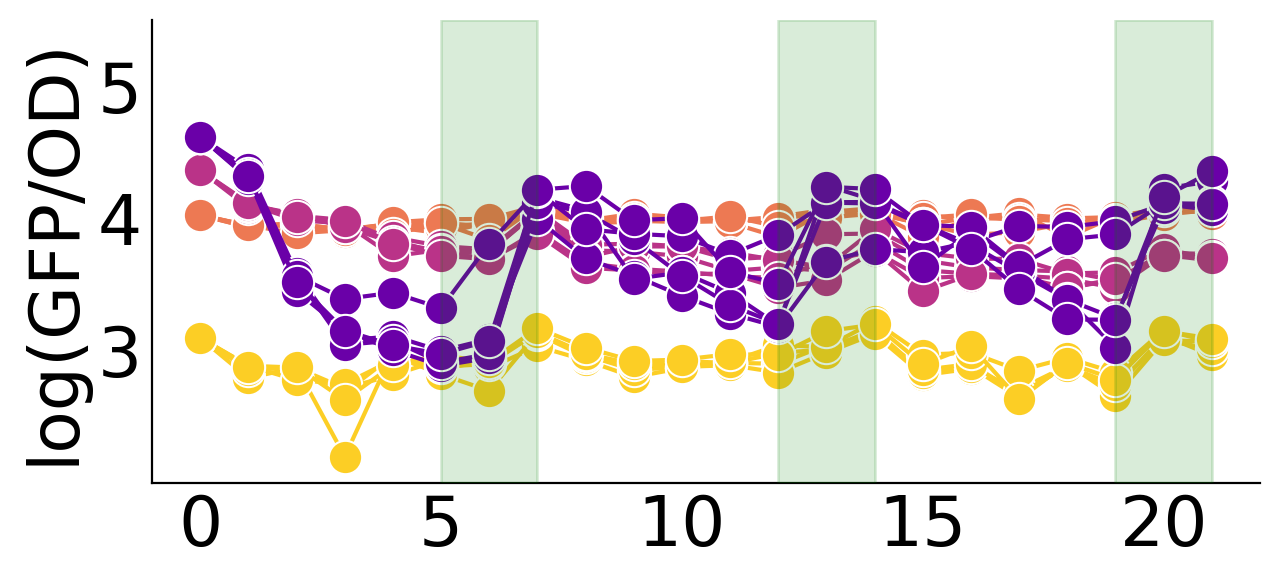

In [75]:
# Set up figure size
plt.figure(figsize=(6.5, 3), dpi=200)

# Generate the 4 plasma colors for the plasmids
plasma_colors = plt.cm.plasma_r(np.linspace(0.1, 0.8, 4))
silver_color = "#D5D5D5"

# 2. Create a Color Dictionary (The Fix)
# --------------------------------------
# This ensures p15A gets the first plasma color and Chr gets silver, 
# no matter what order they appear in the dataframe.
custom_palette = {
    "p15A": plasma_colors[0],
    "pBR322":  plasma_colors[1],
    "CloDF13": plasma_colors[2],
    "pUC":   plasma_colors[3],
    "Chromosome":   silver_color,
}

# Define the order explicitly to match your manual legend labels later
specified_order = ["p15A", "pBR322", "CloDF13", "pUC", "Chromosome"]


# Create line plot with points
ax = sns.lineplot(
    # data=df_main,
    data=df_main[(df_main['Plasmid']!='Chromosome')],
    x='Day',
    y='log10(GFP/OD)',
    hue='Plasmid',  
    hue_order=specified_order,
    units='Replicate',  # Creates separate lines for each ExpRep (detail in Altair)
    estimator=None,  # Don't aggregate data points
    marker='o',      # Add markers on the line
    markersize=12,   # Large marker size
    alpha=1,       # Match opacity from Altair
    palette=custom_palette,
    legend=False # No legend as in original
)

add_treatment_windows(ax)

# Set axis limits to match Altair scales
plt.xlim(-1, 22)
plt.ylim(2, 5.5) # (2.5, 5)

# Configure axis appearance
ax.tick_params(axis='x', labelsize=25, length=0)
ax.tick_params(axis='y', labelsize=25, length=0)
plt.xticks([0, 5, 10, 15, 20])  # 5 tick marks
plt.yticks([3,4, 5])  # 3 tick marks
plt.xlabel('')
plt.ylabel('log(GFP/OD)', fontsize=25)
plt.grid(False)

# Remove spines to match minimal Altair style
sns.despine(left=False, bottom=False, right=True, top=True)

# Use tight layout to optimize spacing
plt.tight_layout()

plt.savefig('Figures_final/Figure3/Fig3E_noTransposase.pdf', format="pdf", bbox_inches="tight")

# Display plot
plt.show()

### Supplementary Figure 8
**Saved outputs:** `SF8E_noTransposase_Kan.pdf`

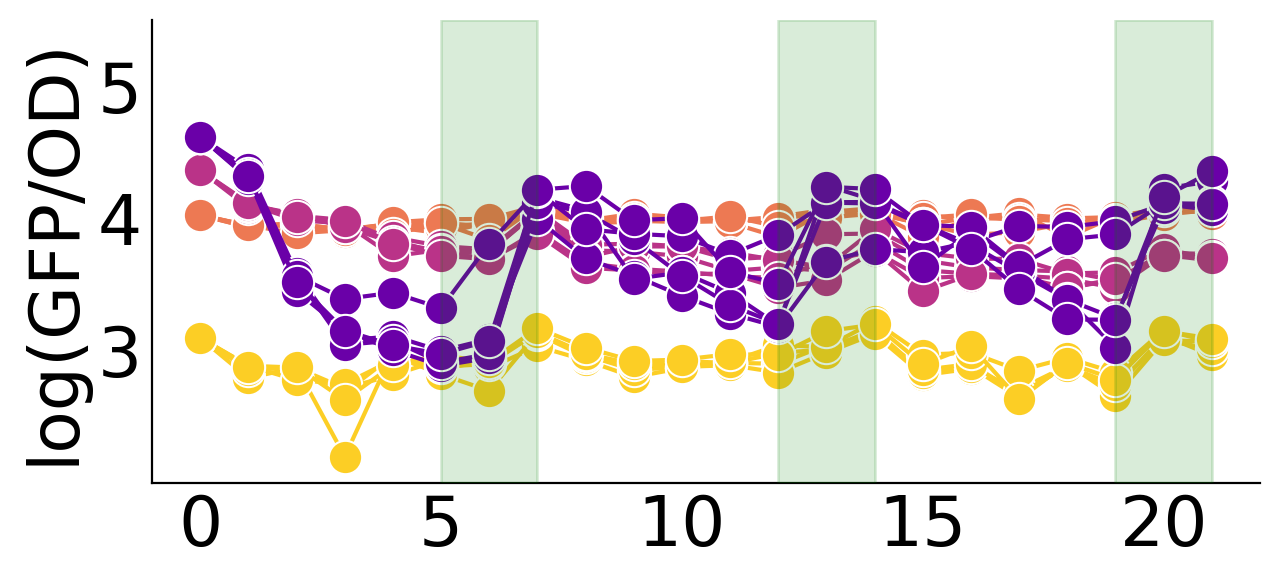

In [76]:
# Set up figure size
plt.figure(figsize=(6.5, 3), dpi=200)

# Create line plot with points
ax_Kan = sns.lineplot(
    data=df_main[df_main['Plasmid']!='Chromosome'],
    x='Day',
    y='log10(GFP/OD)',
    hue='Plasmid',  
    units='Replicate',  # Creates separate lines for each ExpRep (detail in Altair)
    estimator=None,  # Don't aggregate data points
    marker='o',      # Add markers on the line
    markersize=12,   # Large marker size
    alpha=1,       # Match opacity from Altair
    palette=custom_palette ,
    legend=False     # No legend as in original
)

add_treatment_windows(ax_Kan)

# Set axis limits to match Altair scales
plt.xlim(-1, 22)
plt.ylim(2, 5.5)

# Configure axis appearance
ax_Kan.tick_params(axis='x', labelsize=25, length=0)
ax_Kan.tick_params(axis='y', labelsize=25, length=0)
plt.xticks([0, 5, 10, 15, 20])  # 5 tick marks
plt.yticks([3,4, 5])  # 3 tick marks
plt.xlabel('')
plt.ylabel('log(GFP/OD)', fontsize=25)
plt.grid(False)

# Remove spines to match minimal Altair style
sns.despine(left=False, bottom=False, right=True, top=True)

# Use tight layout to optimize spacing
plt.tight_layout()

plt.savefig('Figures_final/supplementary/SF8E_noTransposase_Kan.pdf', format="pdf", bbox_inches="tight")

# Display plot
plt.show()

### Supplementary Figure 8
**Saved outputs:** `SF8E_noTransposase_noKan.pdf`

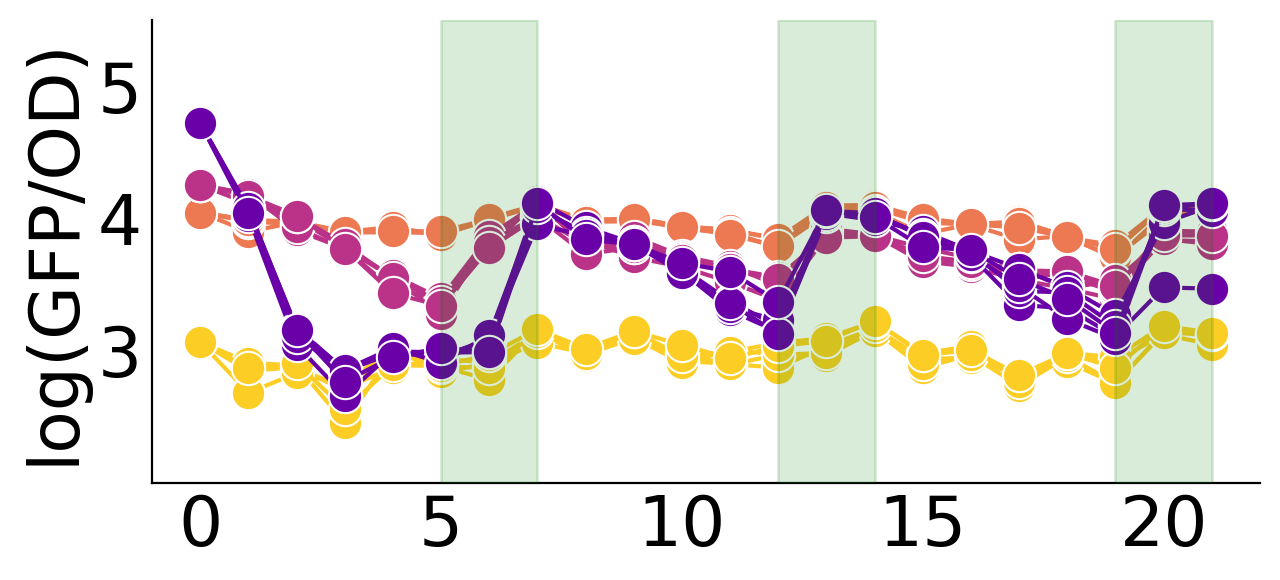

In [77]:
# Set up figure size
plt.figure(figsize=(6.5, 3), dpi=200)

# Create line plot with points
ax_noKan = sns.lineplot(
    data=df_main_noKan[df_main_noKan['Plasmid']!='Chromosome'],
    x='Day',
    y='log10(GFP/OD)',
    hue='Plasmid',  
    units='Replicate',  # Creates separate lines for each ExpRep (detail in Altair)
    estimator=None,  # Don't aggregate data points
    marker='o',      # Add markers on the line
    markersize=12,   # Large marker size
    alpha=1,       # Match opacity from Altair
    palette=custom_palette ,
    legend=False     # No legend as in original
)

add_treatment_windows(ax_noKan)

# Set axis limits to match Altair scales
plt.xlim(-1, 22)
plt.ylim(2, 5.5)

# Configure axis appearance
ax_noKan.tick_params(axis='x', labelsize=25, length=0)
ax_noKan.tick_params(axis='y', labelsize=25, length=0)
plt.xticks([0, 5, 10, 15, 20])  # 5 tick marks
plt.yticks([3,4, 5])  # 3 tick marks
plt.xlabel('')
plt.ylabel('log(GFP/OD)', fontsize=25)
plt.grid(False)

# Remove spines to match minimal Altair style
sns.despine(left=False, bottom=False, right=True, top=True)

# Use tight layout to optimize spacing
plt.tight_layout()

plt.savefig('Figures_final/supplementary/SF8E_noTransposase_noKan.pdf', format="pdf", bbox_inches="tight")

# Display plot
plt.show()

In [78]:
toCSV = pd.concat([completeDF_tet10_Kan_WControl, completeDF_tet10_NoKan], axis=0, ignore_index=True)
toCSV = toCSV.drop(columns=['tet', 'Selection'])

In [79]:
# Sort DF based on PCN + chr
toCSV["Kan"] = pd.Series(
        toCSV["Kan"], dtype="category"
    )

toCSV["Kan"] = toCSV[
            "Kan"
        ].cat.reorder_categories(
            [
                0,
                1
            ],
            ordered=True,
        )

In [80]:
toCSV.to_csv('noTransposase_GFP-OD_r.csv', index=False)

In [81]:
def calculateLossRateAvg(df):
    return_df_list = []
    for plasmid in PlasmidList:
        # print(plasmid)
        if plasmid in df['Plasmid'].values:
            copy_number = list(set(df[df['Plasmid'] == plasmid]['PCN']))[0]

            loss01 = \
            (df[(df['Day'] == UP_DAYS[0]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index() / \
            df[(df['Day'] == DOWN_DAYS[0]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index()).reset_index()['GFP/OD']

            KanSeries = df[(df['Day'] == UP_DAYS[1]) & (df['Plasmid'] == plasmid)]['Kan'].reset_index(drop=True)

            loss02 = \
            (df[(df['Day'] == UP_DAYS[1]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index() / \
            df[(df['Day'] == DOWN_DAYS[1]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index()).reset_index()['GFP/OD']

            loss03 = \
            (df[(df['Day'] == UP_DAYS[2]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index() / \
            df[(df['Day'] == DOWN_DAYS[2]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index()).reset_index()['GFP/OD']

            loss = (loss01+loss02+loss03)/3

            generation = LossTreatmentDays * np.log2(TreatmentDilution)

            loss_rate = np.log(loss)/generation
            # print(loss_rate)
            loss_rate_mean = np.mean(loss_rate)
            loss_rate_std = np.std(loss_rate)
            loss_rate_DF = pd.DataFrame({'Plasmid': plasmid,\
                                         'PCN': copy_number,
                                         'Kan': KanSeries,
                                         'rate_of_loss_log(GFP/OD)': loss_rate})

            return_df_list.append(loss_rate_DF)

    return_df = pd.concat(return_df_list)
    return_df['Plasmid'] = pd.Series(return_df['Plasmid'], dtype="category")

    return_df["Plasmid"] = return_df[
            "Plasmid"
        ].cat.reorder_categories(
            [
                "Chromosome",
                "p15A",
                "pBR322",
                "CloDF13",
                "pUC",
                "p15A+"
            ],
            ordered=True,
        )


    return return_df

In [82]:
completeDF_Final = pd.concat([completeDF_tet10_Kan_WControl, completeDF_tet10_NoKan], axis=0, ignore_index=True)

In [83]:
lossRate_tet10_df = calculateLossRateAvg(completeDF_Final)
lossRate_tet10_df['tet'] = 10

In [84]:
alt.Chart(lossRate_tet10_df).mark_circle(size=60).encode(
    alt.X("PCN", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_loss_log(GFP/OD)", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title='loss rate'),
    color=alt.Color('Plasmid').scale(scheme=colorScheme,reverse=True)
).properties(
    width=200,
    height=200
).facet(
    column=alt.Column('Kan', header=alt.Header(title=None))
).configure_header(
    labelFontSize=20  # Adjust this value to change the subtitle size
).properties(
    title=alt.TitleParams(
        text='loss rate per generation',
        fontSize=20,
        fontWeight='bold',
        # color='grey',
        anchor='middle'
    )
).interactive()

alt.FacetChart(...)

In [85]:
def calculateGainRateAvg(df):
    return_df_list = []
    for plasmid in PlasmidList:
        if plasmid in df['Plasmid'].values:
            copy_number = list(set(df[df['Plasmid'] == plasmid]['PCN']))[0]

            # print(plasmid)
            gain01 = \
            (df[(df['Day'] == UP_DAYS[1]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index() / \
            df[(df['Day'] == DOWN_DAYS[0]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index()).reset_index()['GFP/OD']

            KanSeries = df[(df['Day'] == UP_DAYS[1]) & (df['Plasmid'] == plasmid)]['Kan'].reset_index(drop=True)
            # print(KanSeries)

            gain02 = \
            (df[(df['Day'] == UP_DAYS[2]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index() / \
            df[(df['Day'] == DOWN_DAYS[1]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index()).reset_index()['GFP/OD']

            gain = (gain01+gain02)/2

            generation = SelectionTreatmentDays * np.log2(TreatmentDilution)

            gain_rate = np.log(gain)/generation
            # print(gain_rate)
            gain_rate_mean = np.mean(gain_rate)
            gain_rate_std = np.std(gain_rate)

            gain_rate_DF = pd.DataFrame({'Plasmid': plasmid,\
                                         'PCN': copy_number,
                                         'Kan': KanSeries,
                                         'rate_of_gain_log(GFP/OD)': gain_rate})

            return_df_list.append(gain_rate_DF)

    return_df = pd.concat(return_df_list)
    return_df['Plasmid'] = pd.Series(return_df['Plasmid'], dtype="category")

    return_df["Plasmid"] = return_df[
            "Plasmid"
        ].cat.reorder_categories(
            [
                "Chromosome",
                "p15A",
                "pBR322",
                "CloDF13",
                "pUC",
                "p15A+"
            ],
            ordered=True,
        )


    return return_df

In [86]:
gainRate_tet10_df = calculateGainRateAvg(completeDF_Final)
gainRate_tet10_df['tet'] = 10

In [87]:
alt.Chart(gainRate_tet10_df).mark_circle(size=60).encode(
    alt.X("PCN", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_gain_log(GFP/OD)", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title='gain rate'),
    color=alt.Color('Plasmid').scale(scheme=colorScheme,reverse=True)
).properties(
    width=200,
    height=200
).facet(
    column=alt.Column('Kan', header=alt.Header(title=None))
).configure_header(
    labelFontSize=20  # Adjust this value to change the subtitle size
).properties(
    title=alt.TitleParams(
        text='gain rate per generation',
        fontSize=20,
        fontWeight='bold',
        # color='grey',
        anchor='middle'
    )
).interactive()

alt.FacetChart(...)

In [88]:
# Assign Jumping column: 1 if '+' is at end and for 'Chromosome'
lossRate_tet10_df_toSave = lossRate_tet10_df.copy(deep=True)
lossRate_tet10_df_toSave['Jumping'] = lossRate_tet10_df['Plasmid'].str.contains('\+').astype(int)
lossRate_tet10_df_toSave.loc[lossRate_tet10_df_toSave['Plasmid'] == 'Chromosome', 'Jumping'] = 1
lossRate_tet10_df_toSave['Plasmid'] = lossRate_tet10_df_toSave['Plasmid'].str.replace('\+$', '', regex=True)
lossRate_tet10_df_toSave['rate_of_loss_log(GFP/OD)'] = lossRate_tet10_df_toSave['rate_of_loss_log(GFP/OD)'].astype(float)
lossRate_tet10_df_toSave['Jumping'] = lossRate_tet10_df_toSave['Jumping'].astype(float)


In [89]:
# Assign Jumping column: 1 if '+' is at end and for 'Chromosome'
gainRate_tet10_df_toSave = gainRate_tet10_df.copy(deep=True)
gainRate_tet10_df_toSave['Jumping'] = gainRate_tet10_df['Plasmid'].str.contains('\+').astype(int)
gainRate_tet10_df_toSave.loc[gainRate_tet10_df_toSave['Plasmid'] == 'Chromosome', 'Jumping'] = 1
gainRate_tet10_df_toSave['Plasmid'] = gainRate_tet10_df_toSave['Plasmid'].str.replace('\+$', '', regex=True)
gainRate_tet10_df_toSave['rate_of_gain_log(GFP/OD)'] = gainRate_tet10_df_toSave['rate_of_gain_log(GFP/OD)'].astype(float)
gainRate_tet10_df_toSave['Jumping'] = gainRate_tet10_df_toSave['Jumping'].astype(float)

In [90]:
## Save calcualted rates
gainRate_tet10_df_toSave.to_csv('noJumping_gain_r.csv', index=False)
lossRate_tet10_df_toSave.to_csv('noJumping_loss_r.csv', index=False)

# Save raw data 
completeDF_tet10.to_csv('rawData_GFP_r.csv', index=False)

# qPCR data with Transposase

In [91]:
alt.data_transformers.disable_max_rows()

DataTransformerRegistry.enable('default')

In [92]:
figWidth = 600
figHeight = 270
colorScheme = 'plasma'

## The end of each treatment course
UP_DAYS = [0, 7, 14, 21]
DOWN_DAYS = [5, 12, 19]

TreatmentDilution = 30000
LossTreatmentDays = 5
SelectionTreatmentDays = 2
PlasmidList = ["pBR322", "CloDF", "pUC", "chromosome"]

In [93]:
calibrationFile = pd.ExcelFile('qPCR_withTransposase/2024-1001_yuanchi.xls')

In [94]:
calibrationDF = calibrationFile.parse('Results', header = 46).loc[:336, ['Well Position', 'Sample Name', 'Target Name', \
                                                  'Rep', 'Dilution', 'PCN', 'CT']]
pUC_DF = calibrationDF[calibrationDF['PCN'] == 'pUC']
p15A_DF = calibrationDF[calibrationDF['PCN'] == 'p15A']

# Locate entried for each target
pUC_df_cm = pUC_DF[pUC_DF['Target Name'] == 'cmR']
pUC_df_kan = pUC_DF[pUC_DF['Target Name'] == 'kanR']
pUC_df_tet = pUC_DF[pUC_DF['Target Name'] == 'tetA']

p15A_df_cm = p15A_DF[p15A_DF['Target Name'] == 'cmR']
p15A_df_kan = p15A_DF[p15A_DF['Target Name'] == 'kanR']
p15A_df_tet = p15A_DF[p15A_DF['Target Name'] == 'tetA']

# Use entries with only determined CT values
pUC_df_cm_used = pUC_df_cm[(pUC_df_cm['Dilution'] != -6) & (pUC_df_cm['Dilution'] != -7)]
pUC_df_kan_used = pUC_df_kan[(pUC_df_kan['Dilution'] != -6) & (pUC_df_kan['Dilution'] != -7)]
pUC_df_tet_used = pUC_df_tet[(pUC_df_tet['Dilution'] != -6) & (pUC_df_tet['Dilution'] != -7) ]

p15A_df_cm_used = p15A_df_cm[p15A_df_cm['Dilution'] != -6]
p15A_df_kan_used = p15A_df_kan[p15A_df_kan['Dilution'] != -6]
p15A_df_tet_used = p15A_df_tet[p15A_df_tet['Dilution'] != -6]

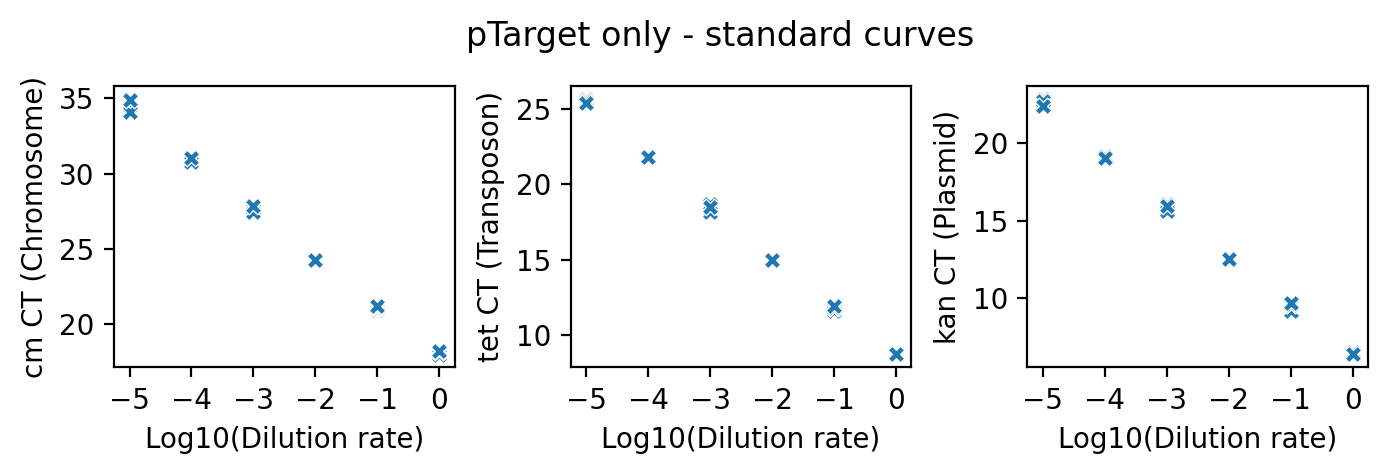

In [95]:
figPUC, axesPUC = plt.subplots(1,3, figsize = (7, 2), dpi = 200)
plt.tight_layout()
sns.scatterplot(x = 'Dilution', y = 'CT', data = pUC_df_cm_used, ax = axesPUC[0], 
              marker = 'X')
sns.scatterplot(x = 'Dilution', y = 'CT', data = pUC_df_tet_used, ax = axesPUC[1], 
             marker = 'X')
sns.scatterplot(x = 'Dilution', y = 'CT', data = pUC_df_kan_used, ax = axesPUC[2], 
             marker = 'X')

plt.suptitle('pTarget only - standard curves', va = 'bottom')
axesPUC[0].set_ylabel('cm CT (Chromosome)')
axesPUC[1].set_ylabel('tet CT (Transposon)')
axesPUC[2].set_ylabel('kan CT (Plasmid)')
axesPUC[0].set_xlabel('Log10(Dilution rate)')
axesPUC[1].set_xlabel('Log10(Dilution rate)')
axesPUC[2].set_xlabel('Log10(Dilution rate)')
axesPUC[0].set_xticks([-5,-4,-3,-2,-1,0])
axesPUC[1].set_xticks([-5,-4,-3,-2,-1,0])
axesPUC[2].set_xticks([-5,-4,-3,-2,-1,0])
#plt.savefig('SF8_A.pdf', format="pdf", bbox_inches="tight")
plt.show()

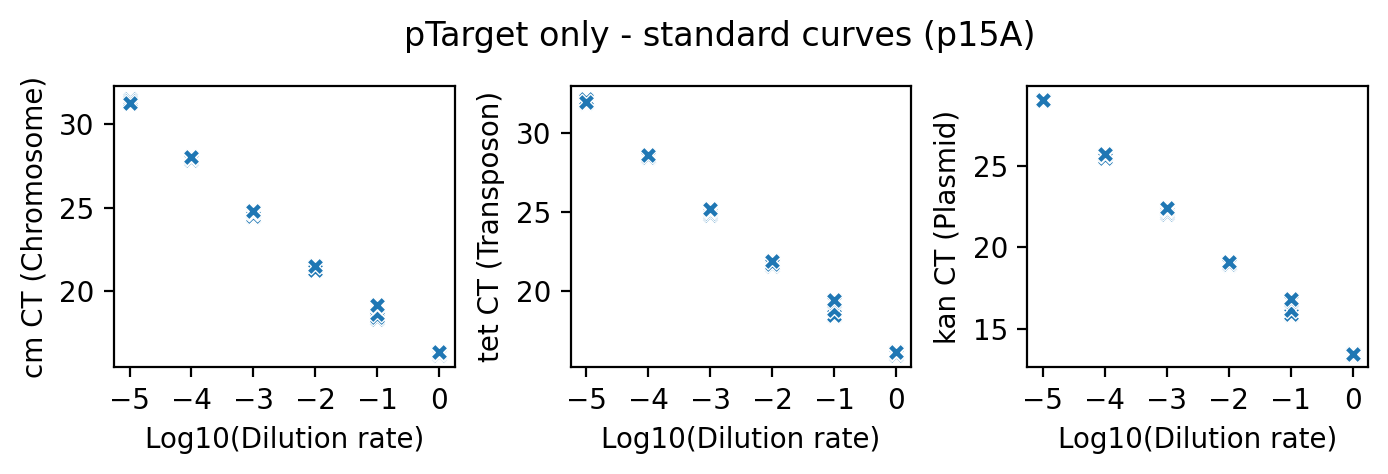

In [96]:
figP15A, axesP15A = plt.subplots(1,3, figsize = (7, 2), dpi = 200)

plt.tight_layout()
sns.scatterplot(x = 'Dilution', y = 'CT', data = p15A_df_cm_used, ax = axesP15A[0], 
              marker = 'X')
sns.scatterplot(x = 'Dilution', y = 'CT', data = p15A_df_tet_used, ax = axesP15A[1], 
             marker = 'X')
sns.scatterplot(x = 'Dilution', y = 'CT', data = p15A_df_kan_used, ax = axesP15A[2], 
             marker = 'X')

plt.suptitle('pTarget only - standard curves (p15A)', va = 'bottom')
axesP15A[0].set_ylabel('cm CT (Chromosome)')
axesP15A[1].set_ylabel('tet CT (Transposon)')
axesP15A[2].set_ylabel('kan CT (Plasmid)')
axesP15A[0].set_xlabel('Log10(Dilution rate)')
axesP15A[1].set_xlabel('Log10(Dilution rate)')
axesP15A[2].set_xlabel('Log10(Dilution rate)')
axesP15A[0].set_xticks([-5,-4,-3,-2,-1,0])
axesP15A[1].set_xticks([-5,-4,-3,-2,-1,0])
axesP15A[2].set_xticks([-5,-4,-3,-2,-1,0])

plt.show()

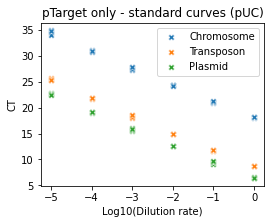

In [97]:
plt.figure(figsize=(4, 3))
sns.scatterplot(x = 'Dilution', y = 'CT', data = pUC_df_cm_used, label='Chromosome', \
              marker = 'X')
sns.scatterplot(x = 'Dilution', y = 'CT', data = pUC_df_tet_used, label='Transposon', \
             marker = 'X')
sns.scatterplot(x = 'Dilution', y = 'CT', data = pUC_df_kan_used, label='Plasmid', \
             marker = 'X')

plt.xlabel('Log10(Dilution rate)')
plt.ylabel('CT')
plt.title('pTarget only - standard curves (pUC)')
plt.show()

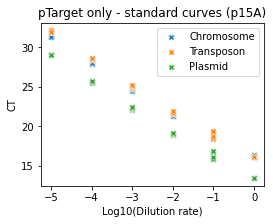

In [98]:
plt.figure(figsize=(4, 3))
sns.scatterplot(x = 'Dilution', y = 'CT', data = p15A_df_cm_used, label='Chromosome', \
              marker = 'X')
sns.scatterplot(x = 'Dilution', y = 'CT', data = p15A_df_tet_used, label='Transposon', \
             marker = 'X')
sns.scatterplot(x = 'Dilution', y = 'CT', data = p15A_df_kan_used, label='Plasmid', \
             marker = 'X')

plt.xlabel('Log10(Dilution rate)')
plt.ylabel('CT')
plt.title('pTarget only - standard curves (p15A)')
plt.show()

In [99]:
def calculateSlopeAmpEff(targetedDFList):
    slopeList = []
    amplificationFactorList = []
    amplificationEfficiencyList = []

    for df in targetedDFList:
        slope = np.polynomial.polynomial.polyfit(list(df['Dilution']), list(df['CT']), 1)[1]
        amplificationFactor = 10**(-1*(1/slope))
        amplificationEfficiency = (amplificationFactor-1)*100

        slopeList.append(slope)
        amplificationFactorList.append(amplificationFactor)
        amplificationEfficiencyList.append(amplificationEfficiency)

    return slopeList, amplificationFactorList, amplificationEfficiencyList

In [100]:
slopeList, ampFactorList, effList = calculateSlopeAmpEff([pUC_df_cm_used, pUC_df_kan_used, pUC_df_tet_used])

In [101]:
# Import daily qPCR results
D0 = pd.ExcelFile('qPCR_withTransposase/D0-2024-10-05.xls').parse('Results', header = 46).loc[:588, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D0_noKan = pd.ExcelFile('qPCR_withTransposase/D0_noKan-2024-11-08.xls').parse('Results', header = 46).loc[:288, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D1 = pd.ExcelFile('qPCR_withTransposase/D1-2024-10-15.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D1_noKan = pd.ExcelFile('qPCR_withTransposase/D1_noKan-2024-10-16.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D2 = pd.ExcelFile('qPCR_withTransposase/D2-2024-10-25.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D2_noKan = pd.ExcelFile('qPCR_withTransposase/D2_noKan-2024-10-26.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D3 = pd.ExcelFile('qPCR_withTransposase/D3-2024-10-28.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D3_noKan = pd.ExcelFile('qPCR_withTransposase/D3_noKan-2024-10-28.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D4 = pd.ExcelFile('qPCR_withTransposase/D4-2024-11-02.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D4_noKan = pd.ExcelFile('qPCR_withTransposase/D4_noKan-2024-11-03.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D5 = pd.ExcelFile('qPCR_withTransposase/D5-2024-11-25.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D5_noKan = pd.ExcelFile('qPCR_withTransposase/D5_noKan-2024-10-19.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D6 = pd.ExcelFile('qPCR_withTransposase/D6-2024-10-30.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D6_noKan = pd.ExcelFile('qPCR_withTransposase/D6_noKan-2024-10-30.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D7 = pd.ExcelFile('qPCR_withTransposase/D7-2024-10-29.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D7_noKan = pd.ExcelFile('qPCR_withTransposase/D7_noKan-2024-10-29.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D8 = pd.ExcelFile('qPCR_withTransposase/D8-2024-11-03.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D8_noKan = pd.ExcelFile('qPCR_withTransposase/D8_noKan-2024-11-03.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D9 = pd.ExcelFile('qPCR_withTransposase/D9-2024-11-06.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D9_noKan = pd.ExcelFile('qPCR_withTransposase/D9_noKan-2024-11-06.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D10 = pd.ExcelFile('qPCR_withTransposase/D10-2024-11-07.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D10_noKan = pd.ExcelFile('qPCR_withTransposase/D10_noKan-2024-11-07.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D11 = pd.ExcelFile('qPCR_withTransposase/D11-2024-11-07.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D11_noKan = pd.ExcelFile('qPCR_withTransposase/D11_noKan-2024-11-07.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D12 = pd.ExcelFile('qPCR_withTransposase/D12-2024-11-10.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D12_noKan = pd.ExcelFile('qPCR_withTransposase/D12_noKan-2024-11-08.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D13 = pd.ExcelFile('qPCR_withTransposase/D13-2024-11-08.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D13_noKan = pd.ExcelFile('qPCR_withTransposase/D13_noKan-2024-11-08.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D14 = pd.ExcelFile('qPCR_withTransposase/D14-2024-10-13.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D14_noKan = pd.ExcelFile('qPCR_withTransposase/D14_noKan-2024-10-17.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D15 = pd.ExcelFile('qPCR_withTransposase/D15-2024-11-08.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D15_noKan = pd.ExcelFile('qPCR_withTransposase/D15_noKan-2024-11-08.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D16 = pd.ExcelFile('qPCR_withTransposase/D16-2024-11-06.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D16_noKan = pd.ExcelFile('qPCR_withTransposase/D16_noKan-2024-11-06.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D17 = pd.ExcelFile('qPCR_withTransposase/D17-2024-11-10.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D17_noKan = pd.ExcelFile('qPCR_withTransposase/D17_noKan-2024-11-10.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D18 = pd.ExcelFile('qPCR_withTransposase/D18-2024-11-04.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D18_noKan = pd.ExcelFile('qPCR_withTransposase/D18_noKan-2024-11-04_02.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D19 = pd.ExcelFile('qPCR_withTransposase/D19-2024-10-11.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D19_noKan = pd.ExcelFile('qPCR_withTransposase/D19_noKan-2024-10-17.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D20 = pd.ExcelFile('qPCR_withTransposase/D20-2024-10-14.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D20_noKan = pd.ExcelFile('qPCR_withTransposase/D20_noKan-2024-10-16.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

D21 = pd.ExcelFile('qPCR_withTransposase/D21-2024-10-30.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]
D21_noKan = pd.ExcelFile('qPCR_withTransposase/D21_noKan-2024-10-30.xls').parse('Results', header = 46).loc[:336, ['Well Position', \
                                                  'qPCRRep', 'ExpRep', 'PCN', 'Target Name', 'CT']]

In [102]:
datafiles_Kan = [(D0,0), (D1,1), (D2,2), (D3,3), (D4,4), (D5,5), (D6,6), (D7,7), (D8,8), (D9,9), (D10,10),\
                 (D11,11), (D12,12), (D13,13), (D14,14), (D15,15), (D16,16), (D17,17), (D18,18), \
                 (D19,19), (D20,20), (D21,21)]

datafiles_noKan = [(D0_noKan,0), (D1_noKan,1), (D2_noKan,2), (D3_noKan,3), (D4_noKan,4), (D5_noKan,5), (D6_noKan,6), \
                   (D7_noKan,7), (D8_noKan,8), (D9_noKan,9), (D10_noKan,10), (D11_noKan,11), (D12_noKan,12), \
                   (D13_noKan,13), (D14_noKan,14), (D15_noKan,15), (D16_noKan,16), (D17_noKan,17), \
                   (D18_noKan,18), (D19_noKan,19), (D20_noKan,20), (D21_noKan,21)]

In [103]:
### P15A data from revision experiments, to be plotted together with the rest 3 plasmids
p15A_withKan_df = pd.read_csv('qPCR_transposase_with-Kan_p15A.csv')
p15A_noKan_df = pd.read_csv('qPCR_transposase_no-Kan_p15A.csv')

In [104]:
def processOneDay(DF, day):
    print(day)
    calculatedDF = pd.DataFrame()

    # Get all calibrated parameters
    DF.loc[DF['Target Name'] == 'cmR', 'Slope'] = slopeList[0]
    DF.loc[DF['Target Name'] == 'kanR', 'Slope'] = slopeList[1]
    DF.loc[DF['Target Name'] == 'tetA', 'Slope'] = slopeList[2]

    DF.loc[DF['Target Name'] == 'cmR', 'AmpFactor'] = ampFactorList[0]
    DF.loc[DF['Target Name'] == 'kanR', 'AmpFactor'] = ampFactorList[1]
    DF.loc[DF['Target Name'] == 'tetA', 'AmpFactor'] = ampFactorList[2]

    DF.loc[DF['Target Name'] == 'cmR', 'Eff'] = effList[0]
    DF.loc[DF['Target Name'] == 'kanR', 'Eff'] = effList[1]
    DF.loc[DF['Target Name'] == 'tetA', 'Eff'] = effList[2]

    qPCRRepList = list(set(DF['qPCRRep']))
    ExpRepList = list(set(DF['ExpRep']))
    PCNList = list(set(DF['PCN']))
    PCNList = [i for i in PCNList if (i != 'H2O') & (i != 'Blank')]

    qPCR_Exp_PCN_Tuple_List = list(itertools.product(qPCRRepList, ExpRepList, PCNList))

    for t in qPCR_Exp_PCN_Tuple_List:
        df_current = DF[(DF['qPCRRep'] == t[0]) & (DF['ExpRep'] == t[1]) & (DF['PCN'] == t[2])]
        currentSlice = DF.loc[df_current.index]

        if currentSlice.empty == False:
            if 'tetA' in (list(currentSlice['Target Name'])):
                currentSlice = currentSlice[currentSlice['CT'] != 'Undetermined']

                cmR_CT = pd.DataFrame(currentSlice[currentSlice['Target Name'] == 'cmR']['CT']).values[0][0]
                tetA_CT = pd.DataFrame(currentSlice[currentSlice['Target Name'] == 'tetA']['CT']).values[0][0]

                cmR_ampFactor = currentSlice[currentSlice['Target Name'] == 'cmR']['AmpFactor'].values[0]
                tetA_ampFactor = currentSlice[currentSlice['Target Name'] == 'tetA']['AmpFactor'].values[0]

                TCopy = cmR_ampFactor**(cmR_CT)/tetA_ampFactor**(tetA_CT)
                currentSlice['transposon copy'] = TCopy

                if currentSlice['PCN'].values[0] != 'Chromosome':
                    kanR_CT = pd.DataFrame(currentSlice[currentSlice['Target Name'] == 'kanR']['CT']).values[0][0]
                    kanR_ampFactor = currentSlice[currentSlice['Target Name'] == 'kanR']['AmpFactor'].values[0]
                    PCopy = cmR_ampFactor**(cmR_CT)/kanR_ampFactor**(kanR_CT)
                    currentSlice['plasmid copy'] = PCopy
                    currentSlice['T/P'] = (TCopy-1)/PCopy
                else:
                    currentSlice['plasmid copy'] = 0

            else:
                currentSlice = currentSlice[currentSlice['CT'] != 'Undetermined']

                cmR_CT = pd.DataFrame(currentSlice[currentSlice['Target Name'] == 'cmR']['CT']).values[0][0]
                kanR_CT = pd.DataFrame(currentSlice[currentSlice['Target Name'] == 'kanR']['CT']).values[0][0]

                cmR_ampFactor = currentSlice[currentSlice['Target Name'] == 'cmR']['AmpFactor'].values[0]
                kanR_ampFactor = currentSlice[currentSlice['Target Name'] == 'kanR']['AmpFactor'].values[0]

                currentSlice['transposon copy'] = 0
                currentSlice['T/P'] = 0

                if kanR_CT != 'Undetermined':
                    currentSlice['plasmid copy'] = cmR_ampFactor**(cmR_CT)/kanR_ampFactor**(kanR_CT)
                else:
                    currentSlice['plasmid copy'] = 0

            calculatedDF = pd.concat([calculatedDF, currentSlice], ignore_index=True)

    calculatedDF["Day"] = day
    calculatedDF['qPCRRep'] = calculatedDF['qPCRRep'].astype(int)  
    calculatedDF['ExpRep'] = calculatedDF['ExpRep'].astype(int).astype(str)


    return calculatedDF

In [105]:
dataframes_tet10_kan = \
[processOneDay(pair[0], pair[1]) for pair in datafiles_Kan]
dataframes_tet10_noKan = \
[processOneDay(pair[0], pair[1]) for pair in datafiles_noKan]

completeDF_tet10_kan = pd.concat(dataframes_tet10_kan, ignore_index=True)
completeDF_tet10_kan['tet'] = 10
completeDF_tet10_noKan = pd.concat(dataframes_tet10_noKan, ignore_index=True)
completeDF_tet10_noKan['tet'] = 10

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21


In [106]:
# Take out all the calibration and testing wells for further analysis
tet10_kan_DF = completeDF_tet10_kan[(completeDF_tet10_kan['PCN'] != 'cyro_chromosome') & \
                               (completeDF_tet10_kan['PCN'] != 'cyro_pSC101') & \
                               (completeDF_tet10_kan['PCN'] != 'p15ASep')]

# Arrange the PCN based on copy number
tet10_kan_DF["PCN"] = pd.Series(
    tet10_kan_DF["PCN"], dtype="category"
)

tet10_kan_DF["PCN"] = tet10_kan_DF[
            "PCN"
        ].cat.reorder_categories(
            [
                "p15A",
                "pBR322",
                "CloDF",
                "pUC",
                "Chromosome",
            ],
            ordered=True,
        )

# Take out all the calibration and testing wells for further analysis
tet10_noKan_DF = completeDF_tet10_noKan[(completeDF_tet10_noKan['PCN'] != 'cyro_chromosome') & \
                               (completeDF_tet10_noKan['PCN'] != 'cyro_pSC101') & \
                               (completeDF_tet10_noKan['PCN'] != 'p15ASep')]

# Arrange the PCN based on copy number
tet10_noKan_DF["PCN"] = pd.Series(
    tet10_noKan_DF["PCN"], dtype="category"
)

tet10_noKan_DF["PCN"] = tet10_noKan_DF[
            "PCN"
        ].cat.reorder_categories(
            [
                "p15A",
                "pBR322",
                "CloDF",
                "pUC",
            ],
            ordered=True,
        )

In [107]:
# Calculate the log of plasmid copy number and transposon copy number
tet10_kan_DF['log(plasmid copy)'] = np.log10(tet10_kan_DF['plasmid copy'])
tet10_kan_DF['log(transposon copy)'] = np.log10(tet10_kan_DF['transposon copy'])

tet10_noKan_DF['log(plasmid copy)'] = np.log10(tet10_noKan_DF['plasmid copy'])
tet10_noKan_DF['log(transposon copy)'] = np.log10(tet10_noKan_DF['transposon copy'])

/Library/Frameworks/Python.framework/Versions/3.8/lib/python3.8/site-packages/pandas/core/arraylike.py:397: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [108]:
completeDF_tet10_kan_copy = tet10_kan_DF.copy(deep=True)
completeDF_tet10_noKan_copy = tet10_noKan_DF.copy(deep=True)

In [109]:
tet10_kan_DF_Use = \
tet10_kan_DF[(tet10_kan_DF['PCN'] != 'p15A')] 

tet10_noKan_DF_Use = \
tet10_noKan_DF[(tet10_noKan_DF['PCN'] != 'p15A')]

tet10_kan_DF_Use_pUC = tet10_kan_DF_Use[tet10_kan_DF_Use['PCN'] == 'pUC']
tet10_noKan_DF_Use_pUC = tet10_noKan_DF_Use[tet10_noKan_DF_Use['PCN'] == 'pUC']

In [110]:
tet10_kan_DF_Use_grouped = tet10_kan_DF_Use.groupby(['Day', 'ExpRep', 'PCN'])[['log(transposon copy)', 'log(plasmid copy)', 'transposon copy', 'plasmid copy', 'T/P']].mean().reset_index().dropna()

tet10_noKan_DF_Use_grouped = tet10_noKan_DF_Use.groupby(['Day', 'ExpRep', 'PCN'])[['log(transposon copy)', 'log(plasmid copy)', 'transposon copy', 'plasmid copy', 'T/P']].mean().reset_index().dropna()

In [111]:
# Get the control chromosome strain results from another file
noTransposon_kan_qPCR_timeCourse_DF = pd.read_csv('qPCR_withTransposase/noTransposon_kan_qPCR_timeCourse.csv')
noTransposon_kan_qPCR_timeCourse_DF_Chr = noTransposon_kan_qPCR_timeCourse_DF[noTransposon_kan_qPCR_timeCourse_DF['PCN'] == 'Chromosome']

noTransposon_noKan_qPCR_timeCourse_DF = pd.read_csv('qPCR_withTransposase/noTransposon_noKan_qPCR_timeCourse.csv')
noTransposon_noKan_qPCR_timeCourse_DF_Chr = noTransposon_noKan_qPCR_timeCourse_DF[noTransposon_noKan_qPCR_timeCourse_DF['PCN'] == 'Chromosome']

In [112]:
# For the control
tet10_kan_DF_Use_grouped_final = pd.concat([tet10_kan_DF_Use_grouped, noTransposon_kan_qPCR_timeCourse_DF_Chr], ignore_index=True)
tet10_noKan_DF_Use_grouped_final = pd.concat([tet10_noKan_DF_Use_grouped, noTransposon_noKan_qPCR_timeCourse_DF_Chr], ignore_index=True)

In [113]:
# Order dataframes again
tet10_kan_DF_Use_grouped_final["PCN"] = pd.Series(
        tet10_kan_DF_Use_grouped_final["PCN"], dtype="category"
    )

tet10_kan_DF_Use_grouped_final["PCN"] = tet10_kan_DF_Use_grouped_final[
            "PCN"
        ].cat.reorder_categories(
            [
                "pBR322",
                "CloDF",
                "pUC",
                "Chromosome",
            ],
            ordered=True,
        )

tet10_noKan_DF_Use_grouped_final["PCN"] = pd.Series(
        tet10_noKan_DF_Use_grouped_final["PCN"], dtype="category"
    )

tet10_noKan_DF_Use_grouped_final["PCN"] = tet10_noKan_DF_Use_grouped_final[
            "PCN"
        ].cat.reorder_categories(
            [
                "pBR322",
                "CloDF",
                "pUC",
                "Chromosome",
            ],
            ordered=True,
        )

In [114]:
tet10_noKan_DF_Use_grouped_final['Kan'] = 0
tet10_kan_DF_Use_grouped_final['Kan'] = 1

In [115]:
toCSV = pd.concat([tet10_noKan_DF_Use_grouped_final, tet10_kan_DF_Use_grouped_final], axis=0, ignore_index=True)

In [116]:
toCSV.to_csv('withTransposase_qPCR.csv', index=False)

In [117]:
# Concate in the p15A data from revision
frames = [p15A_withKan_df, tet10_kan_DF_Use_grouped_final]
# Concatenate them vertically
combined_df = pd.concat(frames, ignore_index=True)

frames_noKan = [p15A_noKan_df, tet10_noKan_DF_Use_grouped_final]
# Concatenate them vertically
combined_noKan_df = pd.concat(frames_noKan, ignore_index=True)

In [118]:
treatmentWindows = [(5, 7), (12, 14), (19, 21)]

def add_treatment_windows(ax):
    for window in treatmentWindows:
        ax.axvspan(
            window[0],
            window[1],
            color='green',
            alpha=0.15,
            zorder=100
        )

### Figure 3
**Saved outputs:** `Fig3C_transposase_withK_TCN.pdf`

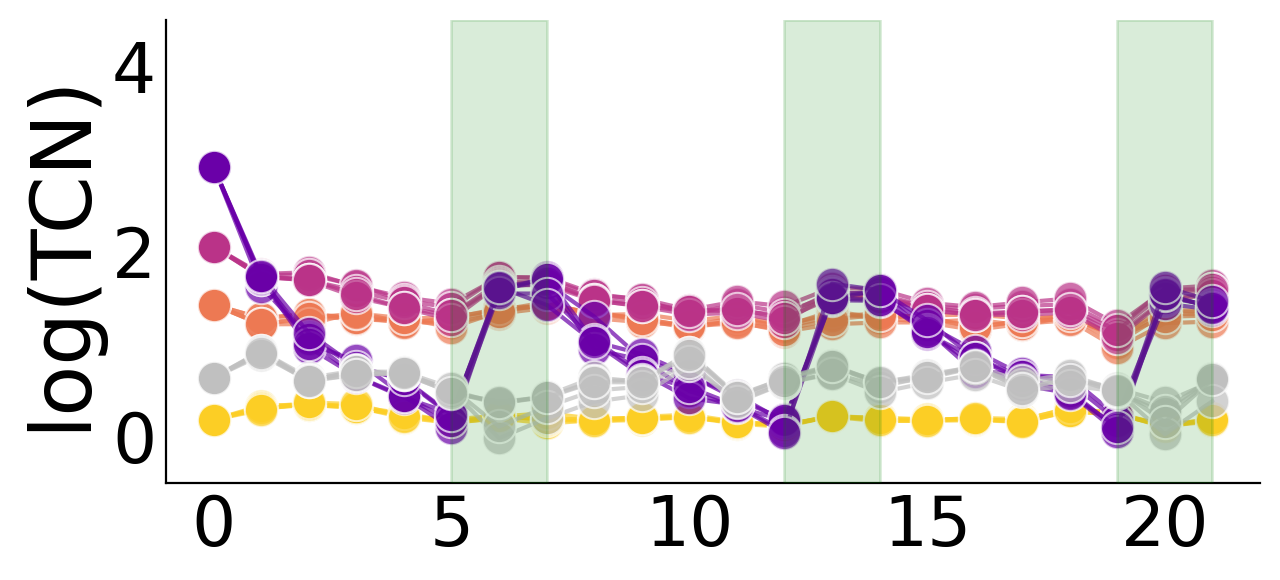

In [119]:
## Experimental conditions: +Kan

# Set up figure size
plt.figure(figsize=(6.5, 3), dpi=200)

# 1. Generate your 4 plasma colors (returns an array of 4 RGBA colors)
plasma_colors = plt.cm.plasma_r(np.linspace(0.1, 0.8, 4))

# 2. Define the keys (category names) exactly as they appear in your 'PCN' column
# based on your plot image, they seem to be:
plasmid_names = ['p15A++', 'pBR322', 'CloDF', 'pUC']

# 3. Create a dictionary mapping each plasmid to a plasma color
# zip() pairs the names with the colors in order
custom_palette = dict(zip(plasmid_names, plasma_colors))

# 4. Add the specific color for Chromosome
custom_palette['Chromosome'] = 'silver'

# Create line plot with points
ax_kan_TCN = sns.lineplot(
    data=combined_df,
    x='Day',
    y='log(transposon copy)',
    hue='PCN',  
    units='ExpRep',  # Creates separate lines for each ExpRep (detail in Altair)
    estimator=None,  # Don't aggregate data points
    marker='o',      # Add markers on the line
    markersize=12,   # Large marker size
    alpha=0.7,       # Match opacity from Altair
    palette=custom_palette,
    legend=False     # No legend as in original
)

add_treatment_windows(ax_kan_TCN)

# Set axis limits to match Altair scales
plt.xlim(-1, 22)
plt.ylim(-0.5, 4.5)

# Configure axis appearance
ax_kan_TCN.tick_params(axis='x', labelsize=25, length=0)
ax_kan_TCN.tick_params(axis='y', labelsize=25, length=0)
plt.xticks([0, 5, 10, 15, 20])  # 5 tick marks
plt.yticks([0, 2, 4])  # 3 tick marks
plt.xlabel('')
plt.ylabel('log(TCN)', fontsize=30)
plt.grid(False)

# Remove spines to match minimal Altair style
sns.despine(left=False, bottom=False, right=True, top=True)

# Use tight layout to optimize spacing
plt.tight_layout()

plt.savefig('Figures_final/Figure3/Fig3C_transposase_withK_TCN.pdf', format="pdf", bbox_inches="tight")

# Display plot
plt.show()

### Figure 4
**Saved outputs:** `Fig4C_withK_PCN.pdf`

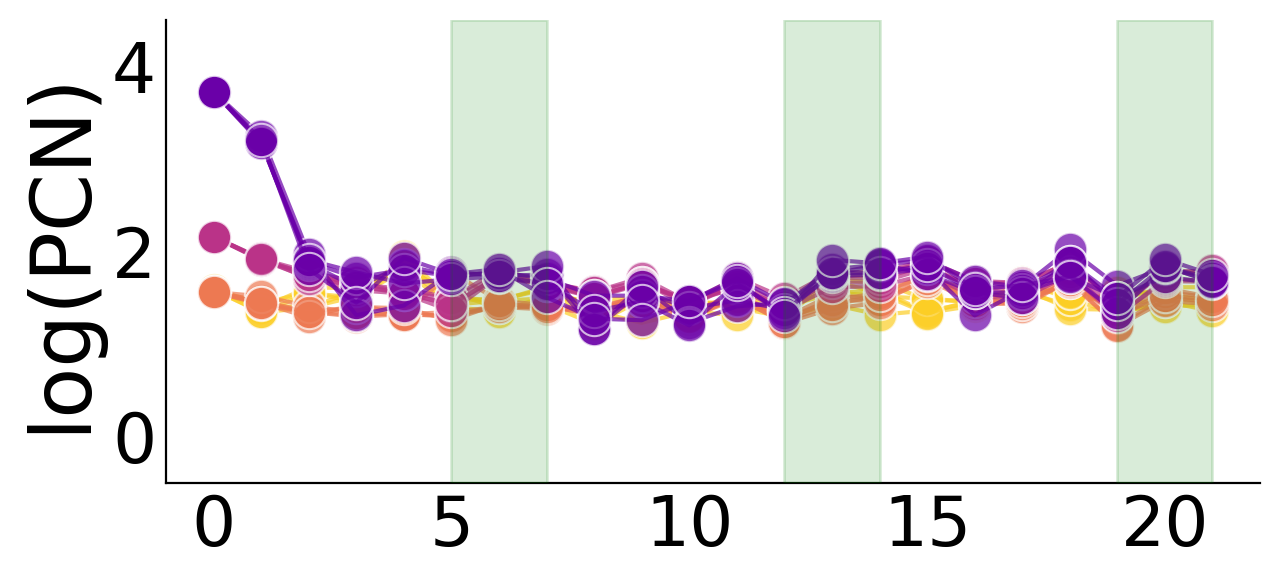

In [120]:
## Experimental conditions: +Kan

# Set up figure size
plt.figure(figsize=(6.5, 3), dpi=200)

# 1. Generate your 4 plasma colors (returns an array of 4 RGBA colors)
plasma_colors = plt.cm.plasma_r(np.linspace(0.1, 0.8, 4))

# 2. Define the keys (category names) exactly as they appear in your 'PCN' column
# based on your plot image, they seem to be:
plasmid_names = ['p15A++', 'pBR322', 'CloDF', 'pUC']

# 3. Create a dictionary mapping each plasmid to a plasma color
# zip() pairs the names with the colors in order
custom_palette = dict(zip(plasmid_names, plasma_colors))

# 4. Add the specific color for Chromosome
custom_palette['Chromosome'] = 'silver'


# Create line plot with points
ax_kan = sns.lineplot(
    data=combined_df[combined_df['PCN']!='Chromosome'],
    x='Day',
    y='log(plasmid copy)',
    hue='PCN',  
    units='ExpRep',  # Creates separate lines for each ExpRep (detail in Altair)
    estimator=None,  # Don't aggregate data points
    marker='o',      # Add markers on the line
    markersize=12,   # Large marker size
    alpha=0.7,       # Match opacity from Altair
    palette=custom_palette,
    legend=False     # No legend as in original
)

add_treatment_windows(ax_kan)

# Set axis limits to match Altair scales
plt.xlim(-1, 22)
plt.ylim(-0.5, 4.5)

# Configure axis appearance
ax_kan.tick_params(axis='x', labelsize=25, length=0)
ax_kan.tick_params(axis='y', labelsize=25, length=0)
plt.xticks([0, 5, 10, 15, 20])  # 5 tick marks
plt.yticks([0, 2, 4])  # 3 tick marks
plt.xlabel('')
plt.ylabel('log(PCN)', fontsize=30)
plt.grid(False)

# Remove spines to match minimal Altair style
sns.despine(left=False, bottom=False, right=True, top=True)

# Use tight layout to optimize spacing
plt.tight_layout()

plt.savefig('Figures_final/Figure4/Fig4C_withK_PCN.pdf', format="pdf", bbox_inches="tight")

# Display plot
plt.show()

### Figure 4
**Saved outputs:** `Fig4E_withK_TCN.pdf`

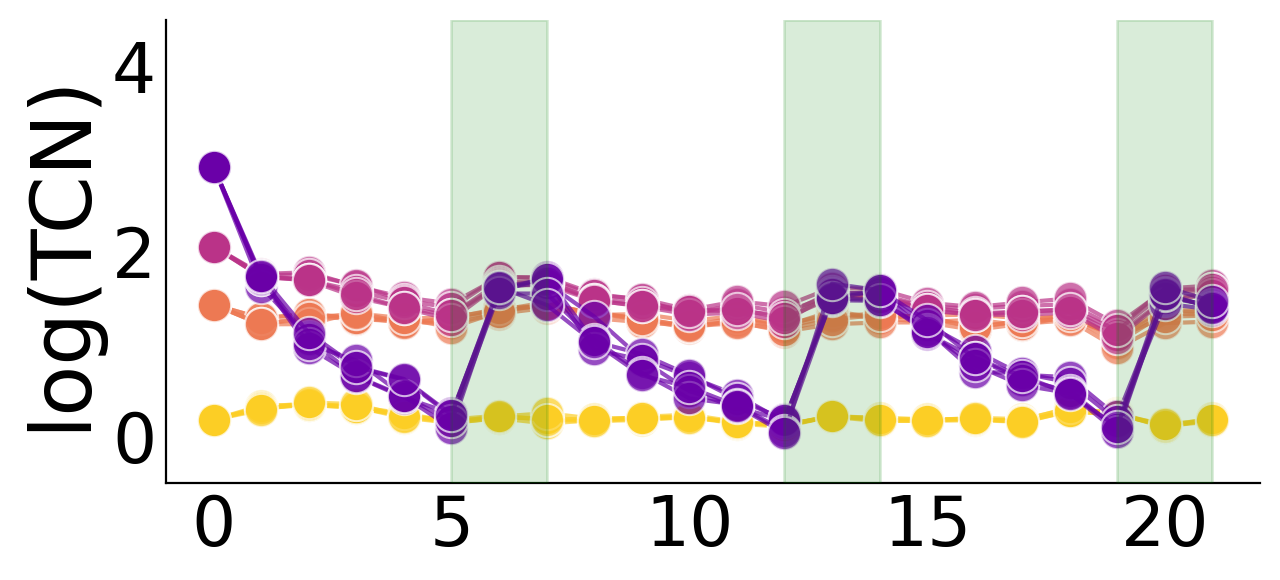

In [121]:
## Experimental conditions: +Kan

# Set up figure size
plt.figure(figsize=(6.5, 3), dpi=200)

# Create line plot with points
ax_kan_TCN = sns.lineplot(
    data=combined_df[combined_df['PCN']!='Chromosome'],
    x='Day',
    y='log(transposon copy)',
    hue='PCN',  
    units='ExpRep',  # Creates separate lines for each ExpRep (detail in Altair)
    estimator=None,  # Don't aggregate data points
    marker='o',      # Add markers on the line
    markersize=12,   # Large marker size
    alpha=0.7,       # Match opacity from Altair
    palette=custom_palette,
    legend=False     # No legend as in original
)

add_treatment_windows(ax_kan_TCN)

# Set axis limits to match Altair scales
plt.xlim(-1, 22)
plt.ylim(-0.5, 4.5)

# Configure axis appearance
ax_kan_TCN.tick_params(axis='x', labelsize=25, length=0)
ax_kan_TCN.tick_params(axis='y', labelsize=25, length=0)
plt.xticks([0, 5, 10, 15, 20])  # 5 tick marks
plt.yticks([0, 2, 4])  # 3 tick marks
plt.xlabel('')
plt.ylabel('log(TCN)', fontsize=30)
plt.grid(False)

# Remove spines to match minimal Altair style
sns.despine(left=False, bottom=False, right=True, top=True)

# Use tight layout to optimize spacing
plt.tight_layout()

plt.savefig('Figures_final/Figure4/Fig4E_withK_TCN.pdf', format="pdf", bbox_inches="tight")

# Display plot
plt.show()

### Supplementary Figure 7
**Saved outputs:** `SF7A_withK_TP.pdf`

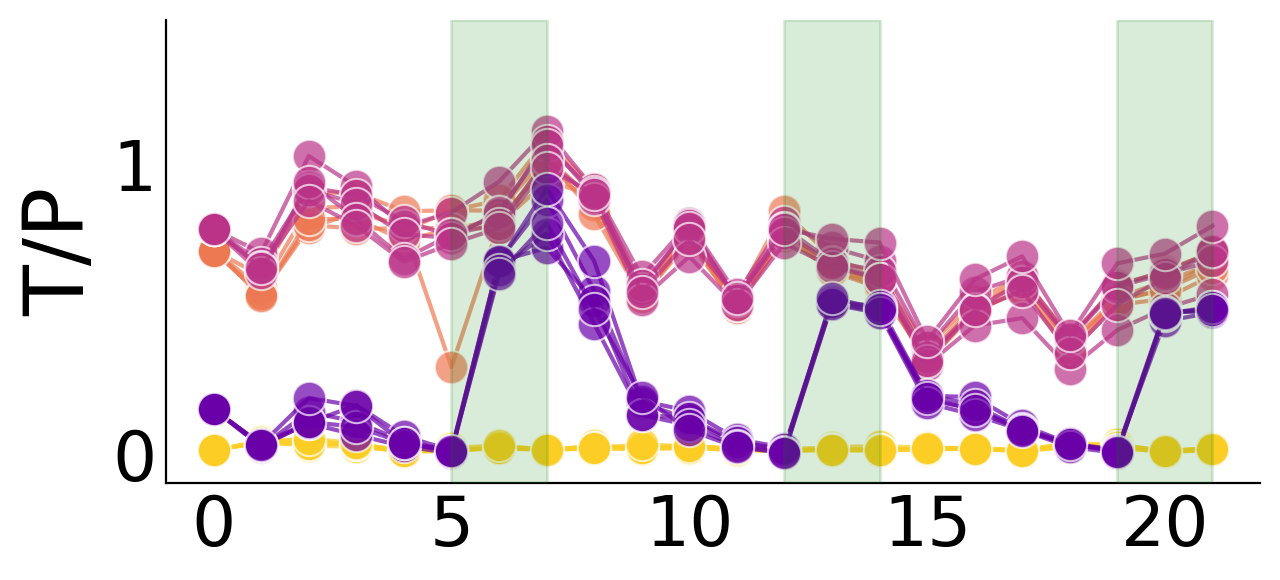

In [122]:
## Experimental conditions: +Kan

# Set up figure size
plt.figure(figsize=(6.5, 3), dpi=200)

# Create line plot with points
ax_kan_TP = sns.lineplot(
    data=combined_df,
    x='Day',
    y='T/P',
    hue='PCN',  
    units='ExpRep',  # Creates separate lines for each ExpRep (detail in Altair)
    estimator=None,  # Don't aggregate data points
    marker='o',      # Add markers on the line
    markersize=12,   # Large marker size
    alpha=0.7,       # Match opacity from Altair
    palette=custom_palette,
    legend=False     # No legend as in original
)

add_treatment_windows(ax_kan_TP)

# Set axis limits to match Altair scales
plt.xlim(-1, 22)
plt.ylim(-0.1, 1.5)

# Configure axis appearance
ax_kan_TP.tick_params(axis='x', labelsize=25, length=0)
ax_kan_TP.tick_params(axis='y', labelsize=25, length=0)
plt.xticks([0, 5, 10, 15, 20])  # 5 tick marks
plt.yticks([0, 1])  # 3 tick marks
plt.xlabel('')
plt.ylabel('T/P', fontsize=30)
plt.grid(False)

# Remove spines to match minimal Altair style
sns.despine(left=False, bottom=False, right=True, top=True)

# Use tight layout to optimize spacing
plt.tight_layout()

plt.savefig('Figures_final/supplementary/SF7A_withK_TP.pdf', format="pdf", bbox_inches="tight")

# Display plot
plt.show()

### Figure 4
**Saved outputs:** `Fig4C_noK_PCN.pdf`

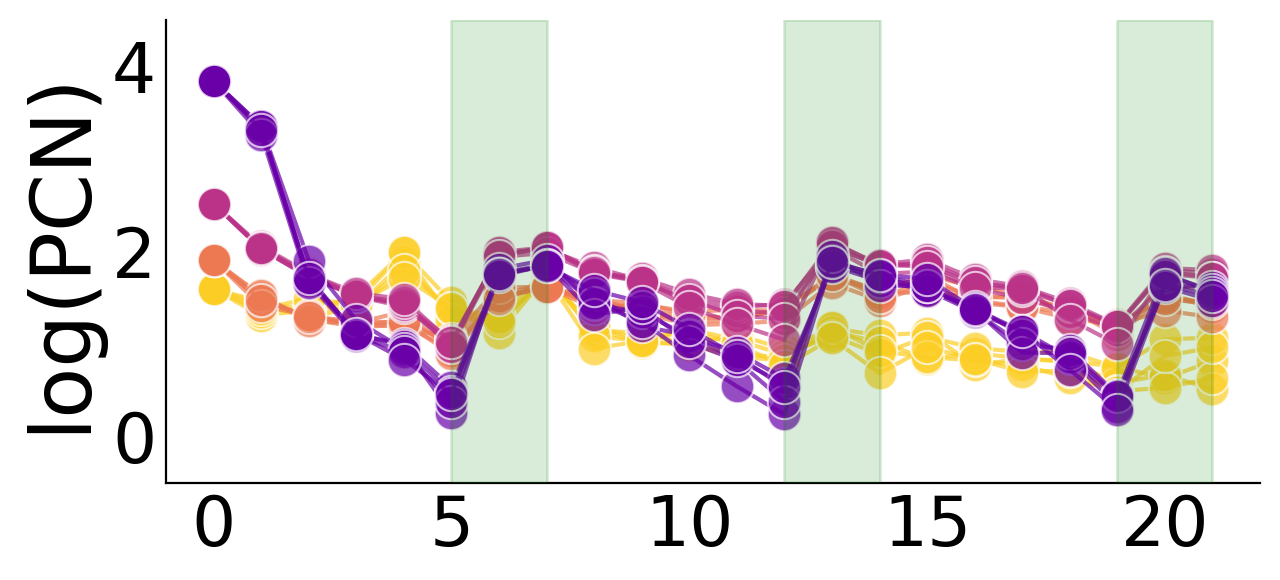

In [123]:
## Experimental conditions: +Kan

# Set up figure size
plt.figure(figsize=(6.5, 3), dpi=200)

df_noKan_noChrom = combined_noKan_df[combined_noKan_df['PCN'] != 'Chromosome']

# Create line plot with points
ax_nokan = sns.lineplot(
    data=df_noKan_noChrom,
    x='Day',
    y='log(plasmid copy)',
    hue='PCN',  
    units='ExpRep',  # Creates separate lines for each ExpRep (detail in Altair)
    estimator=None,  # Don't aggregate data points
    marker='o',      # Add markers on the line
    markersize=12,   # Large marker size
    alpha=0.7,       # Match opacity from Altair
    palette=custom_palette,
    legend=False     # No legend as in original
)

add_treatment_windows(ax_nokan)

# Set axis limits to match Altair scales
plt.xlim(-1, 22)
plt.ylim(-0.5, 4.5)

# Configure axis appearance
ax_nokan.tick_params(axis='x', labelsize=25, length=0)
ax_nokan.tick_params(axis='y', labelsize=25, length=0)
plt.xticks([0, 5, 10, 15, 20])  # 5 tick marks
plt.yticks([0, 2, 4])  # 3 tick marks
plt.xlabel('')
plt.ylabel('log(PCN)', fontsize=30)
plt.grid(False)

# Remove spines to match minimal Altair style
sns.despine(left=False, bottom=False, right=True, top=True)

# Use tight layout to optimize spacing
plt.tight_layout()

plt.savefig('Figures_final/Figure4/Fig4C_noK_PCN.pdf', format="pdf", bbox_inches="tight")

# Display plot
plt.show()

### Figure 4
**Saved outputs:** `Fig4E_noK_TCN.pdf`

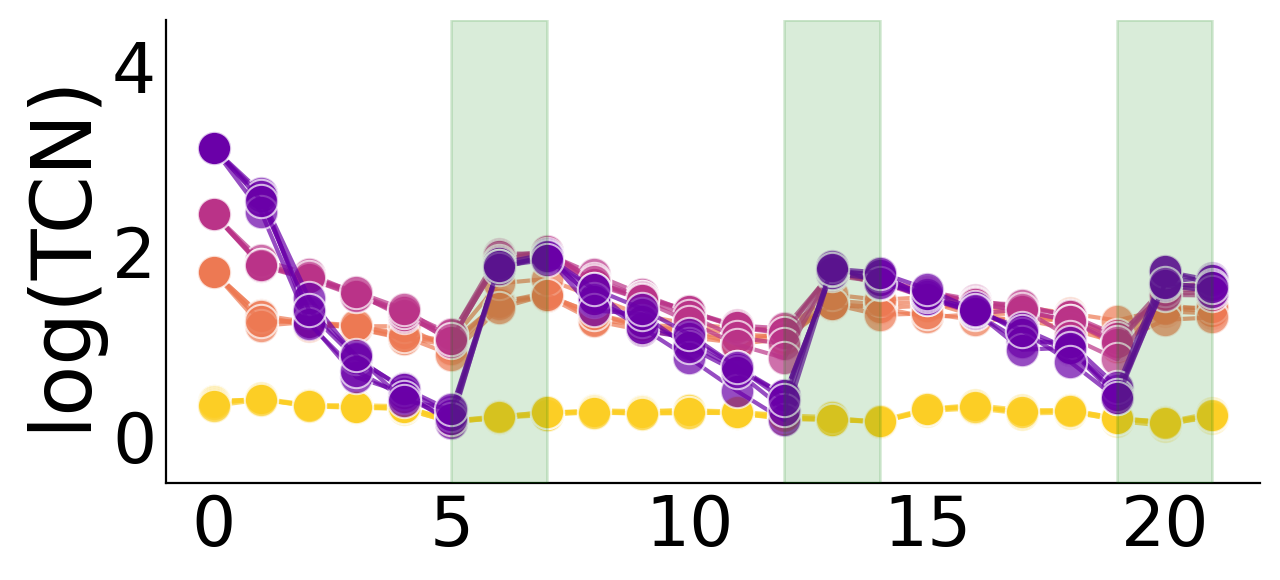

In [124]:
## Experimental conditions: +Kan

# Set up figure size
plt.figure(figsize=(6.5, 3), dpi=200)

# Create line plot with points
ax_nokan_TCN = sns.lineplot(
    data=df_noKan_noChrom,
    x='Day',
    y='log(transposon copy)',
    hue='PCN',  
    units='ExpRep',  # Creates separate lines for each ExpRep (detail in Altair)
    estimator=None,  # Don't aggregate data points
    marker='o',      # Add markers on the line
    markersize=12,   # Large marker size
    alpha=0.7,       # Match opacity from Altair
    palette=custom_palette,
    legend=False     # No legend as in original
)

add_treatment_windows(ax_nokan_TCN)

# Set axis limits to match Altair scales
plt.xlim(-1, 22)
plt.ylim(-0.5, 4.5)

# Configure axis appearance
ax_nokan_TCN.tick_params(axis='x', labelsize=25, length=0)
ax_nokan_TCN.tick_params(axis='y', labelsize=25, length=0)
plt.xticks([0, 5, 10, 15, 20])  # 5 tick marks
plt.yticks([0, 2, 4])  # 3 tick marks
plt.xlabel('')
plt.ylabel('log(TCN)', fontsize=30)
plt.grid(False)

# Remove spines to match minimal Altair style
sns.despine(left=False, bottom=False, right=True, top=True)

# Use tight layout to optimize spacing
plt.tight_layout()

plt.savefig('Figures_final/Figure4/Fig4E_noK_TCN.pdf', format="pdf", bbox_inches="tight")

# Display plot
plt.show()

### Supplementary Figure 7
**Saved outputs:** `SF7A_noK_TP.pdf`

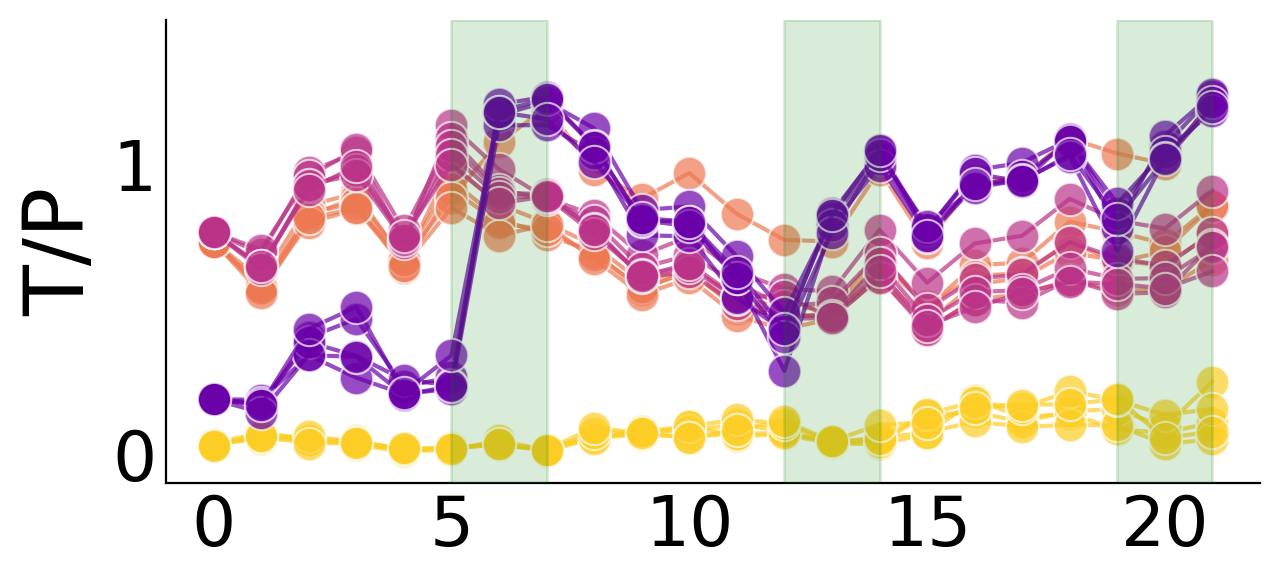

In [125]:
## Experimental conditions: +Kan

# Set up figure size
plt.figure(figsize=(6.5, 3), dpi=200)

# Create line plot with points
ax_nokan_TP = sns.lineplot(
    data=combined_noKan_df,
    x='Day',
    y='T/P',
    hue='PCN',  
    units='ExpRep',  # Creates separate lines for each ExpRep (detail in Altair)
    estimator=None,  # Don't aggregate data points
    marker='o',      # Add markers on the line
    markersize=12,   # Large marker size
    alpha=0.7,       # Match opacity from Altair
    palette=custom_palette,
    legend=False     # No legend as in original
)

add_treatment_windows(ax_nokan_TP)

# Set axis limits to match Altair scales
plt.xlim(-1, 22)
plt.ylim(-0.1, 1.5)

# Configure axis appearance
ax_nokan_TP.tick_params(axis='x', labelsize=25, length=0)
ax_nokan_TP.tick_params(axis='y', labelsize=25, length=0)
plt.xticks([0, 5, 10, 15, 20])  # 5 tick marks
plt.yticks([0, 1])  # 3 tick marks
plt.xlabel('')
plt.ylabel('T/P', fontsize=30)
plt.grid(False)

# Remove spines to match minimal Altair style
sns.despine(left=False, bottom=False, right=True, top=True)

# Use tight layout to optimize spacing
plt.tight_layout()

plt.savefig('Figures_final/supplementary/SF7A_noK_TP.pdf', format="pdf", bbox_inches="tight")

# Display plot
plt.show()

In [126]:
# Calculate PCN by averaging over everyday
tet10_kan_DF_Use_grouped.groupby(['PCN'])['plasmid copy'].mean()

# Combine 2 dataframes for further analysis
tet10_kan_DF_Use_grouped['Kan'] = 'Kan'
tet10_noKan_DF_Use_grouped['Kan'] = 'noKan'

combined_data = pd.concat([tet10_kan_DF_Use_grouped, tet10_noKan_DF_Use_grouped])

In [127]:
PlasmidListNew = ["p15A++", "pBR322", "CloDF", "pUC", "Chromosome"] 
PlasmidListNew_noChr = ["p15A++", "pBR322", "CloDF", "pUC"]

In [128]:
def calculateLossRate(df, qPCRtarget):
    # Make pairs of (Up day, Down day)
    up_down_pair = list(zip(UP_DAYS[:], DOWN_DAYS[:]))
    if qPCRtarget == 'transposon copy':
        PlasmidListUse = PlasmidListNew
    else:
        PlasmidListUse = PlasmidListNew_noChr

    # Process each plasmid
    for plasmid in PlasmidListUse:
        print(plasmid)
        if plasmid != '':  
            # Process each pair
            for pair in up_down_pair:
                # Selection Day result
                denominator = df[(df['Day'] == pair[0]) & (df['PCN'] == plasmid)][qPCRtarget]
                # The last day of no selection After the selection day
                numerator = df[(df['Day'] == pair[1]) & (df['PCN'] == plasmid)][qPCRtarget]

                # Ensure the indexes align
                denominator = denominator.reset_index(drop=True)
                numerator = numerator.reset_index(drop=True)

                # To make the value positive
                loss = denominator/numerator

                loss = loss.dropna()

                indices = df[(df['Day'] == pair[1]) & (df['PCN'] == plasmid)].index

                # Assign the calculated loss back
                df.loc[indices, 'loss'] = loss.values

                # Take mean of all days  
                df.loc[indices, 'mean of loss'] = np.mean(df.loc[indices, 'loss'])

                # Calculate the rate & stats
                generation = LossTreatmentDays * np.log2(TreatmentDilution)    
                loss_rate = np.log(loss)/generation
                loss_rate_mean = np.mean(loss_rate)
                loss_rate_std = np.std(loss_rate)

                # Assign calculated loss rate & stats values to the df
                df.loc[indices, 'rate_of_loss_log('+qPCRtarget+')'] = loss_rate.values
                df.loc[indices, 'mean_of_loss_rate(log('+qPCRtarget+'))'] = loss_rate_mean
                df.loc[indices, 'std_of_loss_rate(log('+qPCRtarget+'))'] = loss_rate_std
                df.loc[indices, 'ci_lower('+qPCRtarget+')'] = loss_rate_mean - loss_rate_std
                df.loc[indices, 'ci_upper('+qPCRtarget+')'] = loss_rate_mean + loss_rate_std

    df = df.fillna(np.nan)

    return df

In [129]:
def makeLossPlotDFs(currentCompleteDF):
    currentCompleteDF_lossCopy = currentCompleteDF.copy(deep=True)
    # for the transposon result
    currentCompleteDF_loss_transposon_df = calculateLossRate(currentCompleteDF_lossCopy, 'transposon copy')
    print('transposon')
    # for the plasmid result
    currentCompleteDF_loss_plasmid_df = calculateLossRate(currentCompleteDF_lossCopy, 'plasmid copy')
    print('plasmid')
    # for the T/P result
    currentCompleteDF_loss_ratio_df = calculateLossRate(currentCompleteDF_lossCopy, 'T/P')
    print('T/P')

    # To postprocess for ploting
    currentCompleteDF_loss_transposon_df_cleaned_scatter = currentCompleteDF_loss_transposon_df.groupby(['PCN','ExpRep'])[['rate_of_loss_log(transposon copy)']].mean().reset_index().dropna()

    currentCompleteDF_loss_plasmid_df_cleaned_scatter = currentCompleteDF_loss_plasmid_df.groupby(['PCN','ExpRep'])[['rate_of_loss_log(plasmid copy)']].mean().reset_index().dropna()

    currentCompleteDF_loss_ratio_df_cleaned_scatter = currentCompleteDF_loss_ratio_df.groupby(['PCN','ExpRep'])[['rate_of_loss_log(T/P)']].mean().reset_index().dropna()

    # Identify overlapping column names
    overlapping_columns = set(currentCompleteDF_loss_transposon_df_cleaned_scatter.columns) & set(currentCompleteDF_loss_plasmid_df_cleaned_scatter.columns) & set(currentCompleteDF_loss_ratio_df_cleaned_scatter.columns)

    # Concatenate DataFrames horizontally, keeping only one occurrence of overlapping columns
    result_df = pd.concat([currentCompleteDF_loss_transposon_df_cleaned_scatter, currentCompleteDF_loss_plasmid_df_cleaned_scatter.loc[:, ~currentCompleteDF_loss_plasmid_df_cleaned_scatter.columns.isin(overlapping_columns)]], axis=1)

    result_df = pd.concat([result_df, currentCompleteDF_loss_ratio_df_cleaned_scatter.loc[:, ~currentCompleteDF_loss_ratio_df_cleaned_scatter.columns.isin(overlapping_columns)]], axis=1)

    return result_df

In [130]:
scatter_kan = makeLossPlotDFs(combined_df)
scatter_noKan = makeLossPlotDFs(combined_noKan_df)

scatter_kan['Kan'] = 1
scatter_noKan['Kan'] = 0

combined_scatter_DF = pd.concat([scatter_kan, scatter_noKan])

combined_scatter_DF['PCN'] = pd.Series(combined_scatter_DF['PCN'], dtype="category")

p15A++
pBR322
CloDF
pUC
Chromosome
transposon
p15A++
pBR322
CloDF
pUC
plasmid
p15A++
pBR322
CloDF
pUC
T/P
p15A++
pBR322
CloDF
pUC
Chromosome
transposon
p15A++
pBR322
CloDF
pUC
plasmid
p15A++
pBR322
CloDF
pUC
T/P


In [131]:
# Transposon loss rate per generation

alt.Chart(combined_scatter_DF).mark_point(size=70).encode(
    alt.X("PCN", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title=None),
    alt.Y("rate_of_loss_log(transposon copy)", scale=alt.Scale(domain=[-0.02, 0.33]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, ticks=False, grid=False), title=None),
    color=alt.Color('PCN', ).scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    width=150,
    height=150
).configure_header(
    labelFontSize=20  # Adjust this value to change the subtitle size
).properties(
    title=alt.TitleParams(
        text='Transposon loss rate',
        fontSize=20,
        fontWeight='bold',
        # color='grey',
        anchor='middle'
    )
).interactive()

alt.Chart(...)

In [132]:
# plasmid loss rate per generation, PCN

alt.Chart(combined_scatter_DF).mark_point(size=70).encode(
    alt.X("PCN", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title=None),
    alt.Y("rate_of_loss_log(plasmid copy)", axis=alt.Axis(labelFontSize=30, titleFontSize=15, ticks=False, grid=False), title=None),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    width=150, 
    height=150
).configure_header(
    labelFontSize=20  # Adjust this value to change the subtitle size
).properties(
    title=alt.TitleParams(
        text='Plasmid loss rate',
        fontSize=20,
        fontWeight='bold',
        # color='grey',
        anchor='middle'
    )
).interactive()

alt.Chart(...)

In [133]:
# T/P loss rate per generation

alt.Chart(combined_scatter_DF).mark_point(size=70).encode(
    alt.X("PCN", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title=None),
    alt.Y("rate_of_loss_log(T/P)", scale=alt.Scale(type='log'), axis=alt.Axis(labelFontSize=30, titleFontSize=15, ticks=False, grid=False), title=None),

    color=alt.Color('PCN',).scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    width=150,
    height=150
).configure_header(
    labelFontSize=20  # Adjust this value to change the subtitle size
).properties(
    title=alt.TitleParams(
        text='T/P loss rate',
        fontSize=20,
        fontWeight='bold',
        # color='grey',
        anchor='middle'
    )
).interactive()

alt.Chart(...)

In [134]:
averagePCN = pd.DataFrame(combined_noKan_df.groupby(['PCN'])['plasmid copy'].mean()).reset_index()

combined_scatter_DF.loc[combined_scatter_DF['PCN'] == 'pBR322', 'averagePCN'] = averagePCN[averagePCN['PCN'] == 'pBR322']['plasmid copy'].values[0]
combined_scatter_DF.loc[combined_scatter_DF['PCN'] == 'CloDF', 'averagePCN'] = averagePCN[averagePCN['PCN'] == 'CloDF']['plasmid copy'].values[0]
combined_scatter_DF.loc[combined_scatter_DF['PCN'] == 'pUC', 'averagePCN'] = averagePCN[averagePCN['PCN'] == 'pUC']['plasmid copy'].values[0]
combined_scatter_DF.loc[combined_scatter_DF['PCN'] == 'p15A++', 'averagePCN'] = averagePCN[averagePCN['PCN'] == 'p15A++']['plasmid copy'].values[0]

In [135]:
averagePCN_rep_noKan_withT = combined_noKan_df.groupby(['PCN', 'ExpRep'])['plasmid copy'].mean().reset_index(name='replicate_averagePCN')

In [136]:
averagePCN_rep_kan_withT = combined_df.groupby(['PCN', 'ExpRep'])['plasmid copy'].mean().reset_index(name='replicate_averagePCN')

In [137]:
TCN_loss_PCNasX = alt.Chart(combined_scatter_DF).mark_point(size=70).encode(
    alt.X("averagePCN", axis=alt.Axis(labelFontSize=25, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_loss_log(transposon copy)", scale=alt.Scale(domain=[0, 0.33]), axis=alt.Axis(labelFontSize=25, titleFontSize=15, grid=False), title='loss rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='TCN',
    width=200,
    height=200
)

PCN_loss_PCNasX = alt.Chart(combined_scatter_DF).mark_point(size=70).encode(
    alt.X("averagePCN", axis=alt.Axis(labelFontSize=25, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_loss_log(plasmid copy)", scale=alt.Scale(domain=[0, 0.33]), axis=alt.Axis(labelFontSize=25, titleFontSize=15, grid=False), title='loss rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='PCN',
    width=200,
    height=200
)

Ratio_loss_PCNasX = alt.Chart(combined_scatter_DF).mark_point(size=70).encode(
    alt.X("averagePCN", axis=alt.Axis(labelFontSize=25, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_loss_log(T/P)", scale=alt.Scale(domain=[0, 0.33]), axis=alt.Axis(labelFontSize=25, titleFontSize=15, grid=False), title='loss rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='T/P',
    width=200,
    height=200
)

Loss_combined_PCNasX_chart = TCN_loss_PCNasX | PCN_loss_PCNasX | Ratio_loss_PCNasX

Loss_combined_PCNasX_chart.interactive()

alt.HConcatChart(...)

In [138]:
TCN_loss_PCNasX = alt.Chart(combined_scatter_DF).mark_point(size=70).encode(
    alt.X("averagePCN", scale=alt.Scale(type='log'), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_loss_log(transposon copy)", scale=alt.Scale(domain=[0, 0.33]), axis=alt.Axis(labelFontSize=25, titleFontSize=15, grid=False), title='loss rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='TCN',
    width=200,
    height=200
)

PCN_loss_PCNasX = alt.Chart(combined_scatter_DF).mark_point(size=70).encode(
    alt.X("averagePCN", scale=alt.Scale(type='log'), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_loss_log(plasmid copy)", scale=alt.Scale(domain=[0, 0.33]), axis=alt.Axis(labelFontSize=25, titleFontSize=15, grid=False), title='loss rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='PCN',
    width=200,
    height=200
)

Ratio_loss_PCNasX = alt.Chart(combined_scatter_DF).mark_point(size=70).encode(
    alt.X("averagePCN", scale=alt.Scale(type='log'), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_loss_log(T/P)", scale=alt.Scale(domain=[0, 0.33]), axis=alt.Axis(labelFontSize=25, titleFontSize=15, grid=False), title='loss rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='T/P',
    width=200,
    height=200
)

Loss_combined_PCNasX_chart = TCN_loss_PCNasX | PCN_loss_PCNasX | Ratio_loss_PCNasX

Loss_combined_PCNasX_chart.interactive()

alt.HConcatChart(...)

In [139]:
def calculateGainRate(df, qPCRtarget):
    # Make pairs of (Up day, Down day)
    up_down_pair = list(zip(UP_DAYS[1:], DOWN_DAYS[:]))
    # print(up_down_pair)
    if qPCRtarget == 'transposon copy':
        PlasmidListUse = PlasmidListNew
    else:
        PlasmidListUse = PlasmidListNew_noChr

    # Process each plasmid
    for plasmid in PlasmidListUse:
        if plasmid != 'p15A':
            # Process each pair
            for pair in up_down_pair:
                # Selection Day result
                numerator = df[(df['Day'] == pair[0]) & (df['PCN'] == plasmid)][qPCRtarget]
                # The last day of no selection After the selection day
                denominator = df[(df['Day'] == pair[1]) & (df['PCN'] == plasmid)][qPCRtarget]
                # Ensure the indexes align
                denominator = denominator.reset_index(drop=True)
                numerator = numerator.reset_index(drop=True)
                gain = numerator/denominator       
                gain = gain.dropna()

                indices = df[(df['Day'] == pair[0]) & (df['PCN'] == plasmid)].index

                # Assign the calculated gain back
                df.loc[indices, 'gain'] = gain.values

                # Take mean of all days  
                df.loc[indices, 'mean of gain'] = np.mean(df.loc[indices, 'gain'])

                # Calculate the rate & stats
                generation = SelectionTreatmentDays * np.log2(TreatmentDilution) 
                gain_rate = np.log(gain)/generation
                gain_rate_mean = np.mean(gain_rate)
                gain_rate_std = np.std(gain_rate)

                # Assign calculated gain rate & stats values to the df
                df.loc[indices, 'rate_of_gain_log('+qPCRtarget+')'] = gain_rate.values
                df.loc[indices, 'mean_of_gain_rate(log('+qPCRtarget+'))'] = gain_rate_mean
                df.loc[indices, 'std_of_gain_rate(log('+qPCRtarget+'))'] = gain_rate_std
                df.loc[indices, 'ci_lower('+qPCRtarget+')'] = gain_rate_mean - gain_rate_std
                df.loc[indices, 'ci_upper('+qPCRtarget+')'] = gain_rate_mean + gain_rate_std

    df = df.fillna(np.nan)

    return df

In [140]:
def makeGainPlotDFs(currentCompleteDF):
    currentCompleteDF_gainCopy = currentCompleteDF.copy(deep=True)
    # for the transposon result
    currentCompleteDF_gain_transposon_df = calculateGainRate(currentCompleteDF_gainCopy, 'transposon copy')
    # for the plasmid result
    currentCompleteDF_gain_plasmid_df = calculateGainRate(currentCompleteDF_gainCopy, 'plasmid copy')
    # for the T/P result
    currentCompleteDF_gain_ratio_df = calculateGainRate(currentCompleteDF_gainCopy, 'T/P')

    # To postprocess for ploting
    currentCompleteDF_gain_transposon_df_cleaned_scatter = currentCompleteDF_gain_transposon_df.groupby(['PCN','ExpRep'])[['rate_of_gain_log(transposon copy)']].mean().reset_index().dropna()

    currentCompleteDF_gain_plasmid_df_cleaned_scatter = currentCompleteDF_gain_plasmid_df.groupby(['PCN','ExpRep'])[['rate_of_gain_log(plasmid copy)']].mean().reset_index().dropna()

    currentCompleteDF_gain_ratio_df_cleaned_scatter = currentCompleteDF_gain_ratio_df.groupby(['PCN','ExpRep'])[['rate_of_gain_log(T/P)']].mean().reset_index().dropna()

    # Identify overlapping column names
    overlapping_columns = set(currentCompleteDF_gain_transposon_df_cleaned_scatter.columns) & set(currentCompleteDF_gain_plasmid_df_cleaned_scatter.columns) & set(currentCompleteDF_gain_ratio_df_cleaned_scatter.columns)

    # Concatenate DataFrames horizontally, keeping only one occurrence of overlapping columns
    result_df = pd.concat([currentCompleteDF_gain_transposon_df_cleaned_scatter, currentCompleteDF_gain_plasmid_df_cleaned_scatter.loc[:, ~currentCompleteDF_gain_plasmid_df_cleaned_scatter.columns.isin(overlapping_columns)]], axis=1)

    result_df = pd.concat([result_df, currentCompleteDF_gain_ratio_df_cleaned_scatter.loc[:, ~currentCompleteDF_gain_ratio_df_cleaned_scatter.columns.isin(overlapping_columns)]], axis=1)

    return result_df

In [141]:
scatter_gain_kan = makeGainPlotDFs(combined_df)
scatter_gain_noKan = makeGainPlotDFs(combined_noKan_df)

scatter_gain_kan['Kan'] = 1
scatter_gain_noKan['Kan'] = 0

combined_scatter_gain_DF = pd.concat([scatter_gain_kan, scatter_gain_noKan])

combined_scatter_gain_DF['PCN'] = pd.Series(combined_scatter_gain_DF['PCN'], dtype="category")

In [142]:
combined_scatter_gain_DF.loc[combined_scatter_DF['PCN'] == 'pBR322', 'averagePCN'] = averagePCN[averagePCN['PCN'] == 'pBR322']['plasmid copy'].values[0]
combined_scatter_gain_DF.loc[combined_scatter_DF['PCN'] == 'CloDF', 'averagePCN'] = averagePCN[averagePCN['PCN'] == 'CloDF']['plasmid copy'].values[0]
combined_scatter_gain_DF.loc[combined_scatter_DF['PCN'] == 'pUC', 'averagePCN'] = averagePCN[averagePCN['PCN'] == 'pUC']['plasmid copy'].values[0]
combined_scatter_gain_DF.loc[combined_scatter_DF['PCN'] == 'p15A++', 'averagePCN'] = averagePCN[averagePCN['PCN'] == 'p15A++']['plasmid copy'].values[0]

In [143]:
# Gain, TCN

alt.Chart(combined_scatter_gain_DF).mark_point(size=70).encode(
    alt.X("PCN", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title=None),
    alt.Y("rate_of_gain_log(transposon copy)", scale=alt.Scale(domain=[-0.01, 0.24]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, tickCount = 3, ticks=False, grid=False), title=None),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='TCN gain rate',
    width=150,
    height=150
)

alt.Chart(...)

In [144]:
# Gain, PCN

alt.Chart(combined_scatter_gain_DF).mark_point(size=70).encode(
    alt.X("PCN", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title=None),
    alt.Y("rate_of_gain_log(plasmid copy)", scale=alt.Scale(domain=[-0.01, 0.24]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, tickCount = 3, ticks=False, grid=False), title=None),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='PCN gain rate',
    width=150,
    height=150
).interactive()

alt.Chart(...)

In [145]:
# T/P, gain

alt.Chart(combined_scatter_gain_DF).mark_point(size=70).encode(
    alt.X("PCN", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title=None),
    alt.Y("rate_of_gain_log(T/P)", scale=alt.Scale(type='log'), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title=None),
    color=alt.Color('PCN', legend=None).scale(scheme=colorScheme,reverse=True),
   shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='T/P gain rate',
    width=150,
    height=150
)

alt.Chart(...)

In [146]:
TCN_gain_PCNasX = alt.Chart(combined_scatter_gain_DF).mark_point(size=70).encode(
    alt.X("averagePCN", axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_gain_log(transposon copy)", scale=alt.Scale(domain=[0, 0.3]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='gain rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='TCN',
    width=200,
    height=200
)

PCN_gain_PCNasX = alt.Chart(combined_scatter_gain_DF).mark_point(size=70).encode(
    alt.X("averagePCN", axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_gain_log(plasmid copy)", scale=alt.Scale(domain=[0, 0.3]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='gain rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='PCN',
    width=200,
    height=200
)

Ratio_gain_PCNasX = alt.Chart(combined_scatter_gain_DF).mark_point(size=70).encode(
    alt.X("averagePCN", axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_gain_log(T/P)", scale=alt.Scale(domain=[0, 0.3]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False), title='gain rate'),
    color=alt.Color('PCN').scale(scheme=colorScheme,reverse=True),
    shape=alt.Shape('Kan:O', legend=None, scale=alt.Scale(range=['arrow', 'triangle']))
).properties(
    title='T/P',
    width=200,
    height=200
)

Gain_combined_PCNasX_chart = TCN_gain_PCNasX | PCN_gain_PCNasX | Ratio_gain_PCNasX

Gain_combined_PCNasX_chart.interactive()

alt.HConcatChart(...)

In [147]:
combined_scatter_gain_DF['Jumping'] = 1
combined_scatter_DF['Jumping'] = 1

In [148]:
# Export precessed data to plot together late
combined_scatter_gain_DF.to_csv('withJumping_gain_qPCR.csv', index=False)
combined_scatter_DF.to_csv('withJumping_loss_qPCR.csv', index=False)

In [149]:
# Export raw data too
combined_data.to_csv('withJumping_rawData.csv', index=False)

# GFP data with Transposase

In [150]:
## excel format and the fluoresence gain one chose
## Check this for each exp, can vary slightly according to platereader setting
OD_START_ROW = 28
GFP_START_ROW = 92

## The end of each treatment course
UP_DAYS = [0, 7, 14, 21]
DOWN_DAYS = [5, 12, 19]

TreatmentDilution = 30000
LossTreatmentDays = 5
SelectionTreatmentDays = 2
PlasmidList = ["p15A", "pBR322", "CloDF13", "pUC", "chromosome"]

colorScheme = 'plasma'

In [151]:
# Assign files to their corresponding dates
Day0 = 'GFP_withTransposase/0730tetA_tube_D0.xlsx'
Day1 = 'GFP_withTransposase/0731tetA_tube_D1.xlsx'
Day2 = 'GFP_withTransposase/0801tetA_tube_D2.xlsx'
Day3 = 'GFP_withTransposase/0802tetA_tube_D3.xlsx'
Day4 = 'GFP_withTransposase/0803tetA_tube_D4.xlsx'
Day5 = 'GFP_withTransposase/0804tetA_tube_D5.xlsx'
Day6 = 'GFP_withTransposase/0805tetA_tube_D6.xlsx'
Day7 = 'GFP_withTransposase/0806tetA_tube_D7.xlsx'
Day8 = 'GFP_withTransposase/0807tetA_tube_D8.xlsx'
Day9 = 'GFP_withTransposase/0808tetA_tube_D9.xlsx'
Day10 = 'GFP_withTransposase/0809tetA_tube_D10.xlsx'
Day11 = 'GFP_withTransposase/0810tetA_tube_D11.xlsx'
Day12 = 'GFP_withTransposase/0811tetA_tube_D12.xlsx'
Day13 = 'GFP_withTransposase/0812tetA_tube_D13.xlsx'
Day14 = 'GFP_withTransposase/0813tetA_tube_D14.xlsx'
Day15 = 'GFP_withTransposase/0814tetA_tube_D15.xlsx'
Day16 = 'GFP_withTransposase/0815tetA_tube_D16.xlsx'
Day17 = 'GFP_withTransposase/0816tetA_tube_D17.xlsx'
Day18 = 'GFP_withTransposase/0817tetA_tube_D18.xlsx'
Day19 = 'GFP_withTransposase/0818tetA_tube_D19.xlsx'
Day20 = 'GFP_withTransposase/0819tetA_tube_D20.xlsx'
Day21 = 'GFP_withTransposase/0820tetA_tube_D21.xlsx'

datafiles = [Day0, Day1, Day2, Day3, Day4, Day5, Day6, Day7, Day8, Day9, Day10, Day11, Day12, Day13, Day14, Day15, Day16, Day17, Day18, Day19, Day20, Day21]

In [152]:
# P15A data extracted from revision experiments
p15A_withKan_df = pd.read_csv('GFP_transposase_with-Kan_p15A.csv')
p15A_noKan_df = pd.read_csv('GFP_transposase_no-Kan_p15A.csv')

In [153]:
noJumping_rawData_GFP_df = pd.read_csv('GFP_withTransposase/noJumping_rawData_GFP.csv') # For the chr data

In [154]:
def prepare_metadata(plate_metadata_path):
    metadata_df = pd.read_csv(plate_metadata_path, index_col='<>').rename_axis('PlateRow').reset_index().melt(id_vars=['PlateRow'], var_name='PlateColumn', value_name='Sample')

    metadata_df['Well'] = metadata_df['PlateRow'].astype(str) + metadata_df['PlateColumn'].astype(str)

    metadata_df = metadata_df.drop(columns=['PlateRow', 'PlateColumn'])

    return metadata_df

In [155]:
def duplicate_and_modify(df, column, value, new_values):
    # Find rows that match the condition
    mask = df[column] == value

    # Create a list to store the new rows
    new_rows = []

    # Iterate through matching rows
    for idx, row in df[mask].iterrows():
        
        # Create duplicates with modified values
        for new_value in new_values:
            new_row = row.copy()
            new_row[column] = new_value
            new_rows.append(new_row)

    # Create a new DataFrame with the new rows
    new_df = pd.DataFrame(new_rows)

    # Combine the new DataFrame with the original, excluding the original matching rows
    mask_inverse = df[df[column] != value]
    # print(mask_inverse)
    result = pd.concat([mask_inverse, new_df], ignore_index=True)

    return result

In [156]:
def duplicate_and_modify_rows(df, condition_column, condition_value, modify_column, new_value):
    """
    Duplicates rows where condition_column equals condition_value,
    and changes the value in modify_column for the duplicated rows.

    :param df: The input DataFrame
    :param condition_column: The column to check for the condition
    :param condition_value: The value to match in the condition column
    :param modify_column: The column to modify in the duplicated rows
    :param new_value: The new value to set in the modified column
    :return: The modified DataFrame
    """
    # Create a mask for rows that meet the condition
    mask = df[condition_column] == condition_value

    # Duplicate the rows that meet the condition
    duplicated_rows = df[mask].copy()

    # Modify the specified column in the duplicated rows
    duplicated_rows[modify_column] = new_value

    # Concatenate the original DataFrame with the duplicated and modified rows
    result_df = pd.concat([df, duplicated_rows], ignore_index=True)

    # Sort the DataFrame to keep the duplicated rows next to their originals
    result_df = result_df.sort_index().reset_index(drop=True)

    return result_df

In [157]:
def prepare_plate_data(excel_filepath, sheetName, day):
    ## import plate layout metadata
    ## Special treatment for tet10, since it does not have the psc101 data
    if excel_filepath == Day0:
        metadata_df = prepare_metadata("GFP_withTransposase/plate-layout-metadata_Day0.csv")

        ## OD600 data
        my_OD_df = (
            pd.read_excel(
                excel_filepath,
                sheet_name=sheetName,
                skiprows=OD_START_ROW - 1,
                nrows=4,
                usecols=list(range(0, 11)),
                index_col="<>",
            )
            .rename_axis("PlateRow")
            .reset_index()
            .melt(
                id_vars=["PlateRow"], var_name="PlateColumn", value_name="OD"
            )
        )

        ## GFP data
        my_GFP_df = (
            pd.read_excel(
                excel_filepath,
                sheet_name=sheetName,
                skiprows=88 - 1,
                nrows=4,
                usecols=list(range(0, 11)),
                index_col="<>",
            )
            .rename_axis("PlateRow")
            .reset_index()
            .melt(
                id_vars=["PlateRow"], var_name="PlateColumn", value_name="GFP"
            )
        )

    else:
        if sheetName == "tet10":
            metadata_df = prepare_metadata("GFP_withTransposase/plate-layout-metadata_tet10.csv")
        else:
            metadata_df = prepare_metadata("GFP_withTransposase/plate-layout-metadata.csv")

        ## OD600 data
        my_OD_df = (
            pd.read_excel(
                excel_filepath,
                sheet_name=sheetName,
                skiprows=OD_START_ROW - 1,
                nrows=6,
                usecols=list(range(0, 11)),
                index_col="<>",
            )
            .rename_axis("PlateRow")
            .reset_index()
            .melt(
                id_vars=["PlateRow"], var_name="PlateColumn", value_name="OD"
            )
        )

        ## GFP data
        my_GFP_df = (
            pd.read_excel(
                excel_filepath,
                sheet_name=sheetName,
                skiprows=GFP_START_ROW - 1,
                nrows=6,
                usecols=list(range(0, 11)),
                index_col="<>",
            )
            .rename_axis("PlateRow")
            .reset_index()
            .melt(
                id_vars=["PlateRow"], var_name="PlateColumn", value_name="GFP"
            )
        )

    ## merge OD and GFP data.
    my_plate_df = pd.merge(my_OD_df, my_GFP_df, on=["PlateRow", "PlateColumn"])

    ## make a 'Well' column
    my_plate_df["Well"] = my_plate_df["PlateRow"].astype(str) + my_plate_df[
        "PlateColumn"
    ].astype(str)
    ## drop the 'PlateRow' and 'PlateColumn' columns
    my_plate_df = my_plate_df.drop(columns=["PlateRow", "PlateColumn"])

    ## merge with metadata based on the 'Well' column
    my_plate_df_with_samples = pd.merge(my_plate_df, metadata_df, on=["Well"])

    ## Calculate the mean GFP & OD for LB only
    LB_ref = my_plate_df_with_samples[
        my_plate_df_with_samples["Sample"] == "LBRef"
    ]

    LB_ref_GFP = np.mean(LB_ref["GFP"])
    LB_ref_OD = np.mean(LB_ref["OD"])

    ## remove ref now
    my_plate_df_with_samples = my_plate_df_with_samples[
        ~my_plate_df_with_samples["Sample"].str.contains("LBRef")
    ]

    ## remove Samples containing Water or LB
    my_plate_df_with_samples = my_plate_df_with_samples[
        ~my_plate_df_with_samples["Sample"].str.contains("empty|noUse")
    ]

    ## Splitting the 'Sample' column into two new columns
    my_plate_df_with_samples[["Kan_Plasmid", "Replicate"]] = (
        my_plate_df_with_samples["Sample"].str.split("_", expand=True)
    )

    ## Splitting the 'Sample' column again based on with Kan or not
    my_plate_df_with_samples[["Kan", "Plasmid"]] = (
        my_plate_df_with_samples["Kan_Plasmid"].str.split("-", expand=True)
    )

    my_plate_df_with_samples = my_plate_df_with_samples.drop(['Kan_Plasmid', 'Sample'], axis=1)

    my_plate_df_with_samples = duplicate_and_modify(my_plate_df_with_samples, 'Replicate', '0', ['1','2','3','4','5'])

    ## Sort Plasmid by copy number by encoding the Plasmid Column as Categorical Data
    ## https://pandas.pydata.org/docs/user_guide/categorical.html#reordering
    my_plate_df_with_samples["Plasmid"] = pd.Series(
        my_plate_df_with_samples["Plasmid"], dtype="category"
    )

    # now reorder the column based on copy number
    ## Check this
    if sheetName == "tet10":
        my_plate_df_with_samples["Plasmid"] = my_plate_df_with_samples[
            "Plasmid"
        ].cat.reorder_categories(
            [
                "p15A",
                "pBR322",
                "CloDF13",
                "pUC",
                "Chromosome",

            ],
            ordered=True,
        )
    else:
        my_plate_df_with_samples["Plasmid"] = my_plate_df_with_samples[
            "Plasmid"
        ].cat.reorder_categories(
            [
                "pSC101",
                "p15A",
                "pBR322",
                "CloDF13",
                "pUC",
                "Chromosome",
            ],
            ordered=True,
        )

    ## add the Day of sample collection
    my_plate_df_with_samples["Day"] = day

    ## add the PCN of each plasmid
    my_plate_df_with_samples.loc[
        my_plate_df_with_samples["Plasmid"] == "chromosome", "PCN"
    ] = 0
    my_plate_df_with_samples.loc[
        my_plate_df_with_samples["Plasmid"] == "p15A", "PCN"
    ] = 20
    my_plate_df_with_samples.loc[
        my_plate_df_with_samples["Plasmid"] == "pBR322", "PCN"
    ] = 30
    my_plate_df_with_samples.loc[
        my_plate_df_with_samples["Plasmid"] == "CloDF13", "PCN"
    ] = 60
    my_plate_df_with_samples.loc[
        my_plate_df_with_samples["Plasmid"] == "pUC", "PCN"
    ] = 400

    ## calculate GFP/OD
    my_plate_df_with_samples["GFP/OD"] = (
        my_plate_df_with_samples["GFP"] - LB_ref_GFP
    ) / (my_plate_df_with_samples["OD"] - LB_ref_OD)

    ## calculate log10 (GFP/OD)
    my_plate_df_with_samples["log10(GFP/OD)"] = np.log10(
        my_plate_df_with_samples["GFP/OD"]
    )

    return my_plate_df_with_samples

In [158]:
# Creat a list of dfs for each treatment, each list contains the df of one day
dataframes_tet10 = [prepare_plate_data(df, 'tet10', zero_indexed_day) for zero_indexed_day, df in enumerate(datafiles)]

In [159]:
completeDF_tet10 = pd.concat(dataframes_tet10, ignore_index=True)
completeDF_tet10['tet'] = 10
completeDF_tet10.loc[completeDF_tet10['Kan'] == 'Kan', 'Kan'] = 1
completeDF_tet10.loc[completeDF_tet10['Kan'] == 'noKan', 'Kan'] = 0

completeDF_tet10['Selection'] = completeDF_tet10['Day'].isin([0, 6, 7, 13, 14, 20, 21])

In [160]:
completeDF_tet10_noP15A = completeDF_tet10[completeDF_tet10['Plasmid'] != 'p15A']
completeDF_tet10_noP15A_copy = completeDF_tet10_noP15A.copy(deep = True)
completeDF_tet10_noP15A = completeDF_tet10_noP15A[completeDF_tet10_noP15A['Plasmid'] != 'Chromosome']

In [161]:
completeDF_tet10_noP15A_Kan = completeDF_tet10_noP15A[completeDF_tet10_noP15A['Kan'] == 1]
completeDF_tet10_noP15A_NoKan = completeDF_tet10_noP15A[completeDF_tet10_noP15A['Kan'] == 0]

In [162]:
completeDF_tet10_noP15A_Kan['Jumping'] = 1

/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_67811/2215342668.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  completeDF_tet10_noP15A_Kan['Jumping'] = 1


In [163]:
noJumping_rawData_GFP_df_chr = noJumping_rawData_GFP_df[noJumping_rawData_GFP_df['Plasmid'] == 'Chromosome'].copy()

noJumping_rawData_GFP_df_chr['Jumping'] = 1
# Reset index if needed
finalWControl = pd.concat([completeDF_tet10_noP15A_Kan, noJumping_rawData_GFP_df_chr], ignore_index=True)

In [164]:
# Sort DF based on PCN + chr
finalWControl["Plasmid"] = pd.Series(
        finalWControl["Plasmid"], dtype="category"
    )

finalWControl["Plasmid"] = finalWControl[
            "Plasmid"
        ].cat.reorder_categories(
            [
                "pBR322",
                "CloDF13",
                "pUC",
                "Chromosome",
            ],
            ordered=True,
        )

In [165]:
frames = [p15A_withKan_df, finalWControl]
combined_df = pd.concat(frames, ignore_index=True)

In [166]:
finalWControl_toPlot = finalWControl[(finalWControl['Plasmid']!='CloDF13') & (finalWControl['Plasmid']!='pBR322') & (finalWControl['Kan']==1)]

In [167]:
treatmentWindows = [(5, 7), (12, 14), (19, 21)]

def add_treatment_windows(ax):
    for window in treatmentWindows:
        ax.axvspan(
            window[0],
            window[1],
            color='green',
            alpha=0.15,
            zorder=100
        )

In [168]:
frames = [p15A_withKan_df, finalWControl]
# Concatenate them vertically
combined_df = pd.concat(frames, ignore_index=True)

frames_noKan = [p15A_noKan_df, completeDF_tet10_noP15A_NoKan]
# Concatenate them vertically
combined_noKan_df = pd.concat(frames_noKan, ignore_index=True)

### Figure 3
**Saved outputs:** `Fig3E_transposase.pdf`

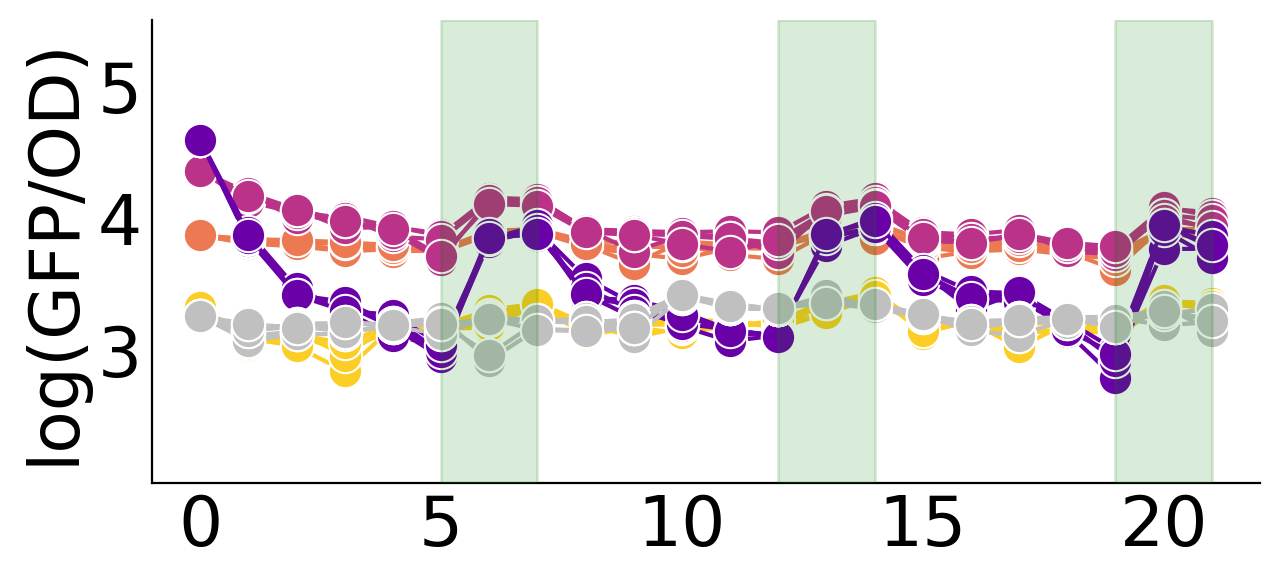

In [169]:
# Set up figure size
plt.figure(figsize=(6.5, 3), dpi=200)

plasma_colors = plt.cm.plasma_r(np.linspace(0.1, 0.8, 4))

# 2. Define the keys (category names) exactly as they appear in your 'PCN' column
# based on your plot image, they seem to be:
plasmid_names = ['p15A+', 'pBR322', 'CloDF13', 'pUC']

# 3. Create a dictionary mapping each plasmid to a plasma color
# zip() pairs the names with the colors in order
custom_palette = dict(zip(plasmid_names, plasma_colors))

# 4. Add the specific color for Chromosome
custom_palette['Chromosome'] = 'silver'

# Create line plot with points
ax_revision = sns.lineplot(
    data=combined_df,
    x='Day',
    y='log10(GFP/OD)',
    hue='Plasmid',  
    units='Replicate',  # Creates separate lines for each ExpRep (detail in Altair)
    estimator=None,  # Don't aggregate data points
    marker='o',      # Add markers on the line
    markersize=12,   # Large marker size
    alpha=1,       # Match opacity from Altair
    palette=custom_palette,
    legend=False     # No legend as in original
)

add_treatment_windows(ax_revision)

# Set axis limits to match Altair scales
plt.xlim(-1, 22)
plt.ylim(2, 5.5)

# Configure axis appearance
ax_revision.tick_params(axis='x', labelsize=25, length=0)
ax_revision.tick_params(axis='y', labelsize=25, length=0)
plt.xticks([0, 5, 10, 15, 20])  # 5 tick marks
plt.yticks([3,4, 5])  # 3 tick marks
plt.xlabel('')
plt.ylabel('log(GFP/OD)', fontsize=25)
plt.grid(False)

# Remove spines to match minimal Altair style
sns.despine(left=False, bottom=False, right=True, top=True)
# sns.move_legend(ax_revision, "upper left", bbox_to_anchor=(1, 1))

# Use tight layout to optimize spacing
plt.tight_layout()

plt.savefig('Figures_final/Figure3/Fig3E_transposase.pdf', format="pdf", bbox_inches="tight")

# Display plot
plt.show()

### Figure 4
**Saved outputs:** `Fig4G_withKan_noChr.pdf`

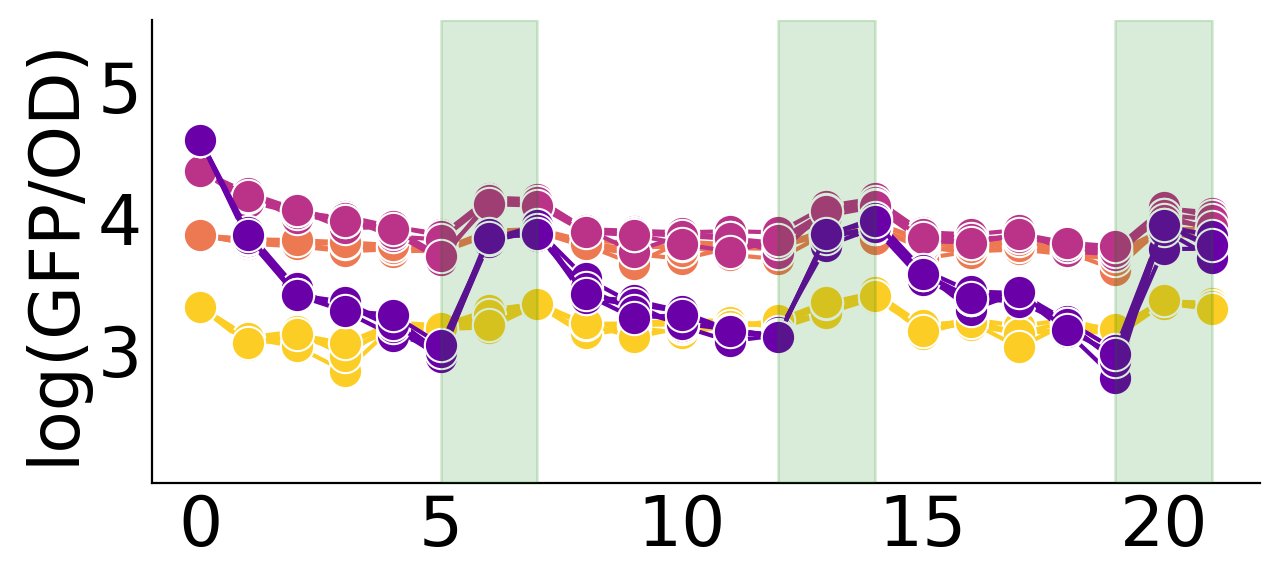

In [170]:
# Set up figure size
plt.figure(figsize=(6.5, 3), dpi=200)

plasma_colors = plt.cm.plasma_r(np.linspace(0.1, 0.8, 4))

# 2. Define the keys (category names) exactly as they appear in your 'PCN' column
# based on your plot image, they seem to be:
plasmid_names = ['p15A+', 'pBR322', 'CloDF13', 'pUC']

# 3. Create a dictionary mapping each plasmid to a plasma color
# zip() pairs the names with the colors in order
custom_palette = dict(zip(plasmid_names, plasma_colors))

# 4. Add the specific color for Chromosome
# custom_palette['Chromosome'] = 'silver'

df_no_chr = combined_df[~combined_df['Plasmid'].isin(['Chromosome', 'Chr'])]

# Create line plot with points
ax_revision = sns.lineplot(
    data=df_no_chr,
    x='Day',
    y='log10(GFP/OD)',
    hue='Plasmid',  
    units='Replicate',  # Creates separate lines for each ExpRep (detail in Altair)
    estimator=None,  # Don't aggregate data points
    marker='o',      # Add markers on the line
    markersize=12,   # Large marker size
    alpha=1,       # Match opacity from Altair
    palette=custom_palette,
    legend=False     # No legend as in original
)

add_treatment_windows(ax_revision)

# Set axis limits to match Altair scales
plt.xlim(-1, 22)
plt.ylim(2, 5.5)

# Configure axis appearance
ax_revision.tick_params(axis='x', labelsize=25, length=0)
ax_revision.tick_params(axis='y', labelsize=25, length=0)
plt.xticks([0, 5, 10, 15, 20])  # 5 tick marks
plt.yticks([3,4, 5])  # 3 tick marks
plt.xlabel('')
plt.ylabel('log(GFP/OD)', fontsize=25)
plt.grid(False)

# Remove spines to match minimal Altair style
sns.despine(left=False, bottom=False, right=True, top=True)
# sns.move_legend(ax_revision, "upper left", bbox_to_anchor=(1, 1))

# Use tight layout to optimize spacing
plt.tight_layout()

plt.savefig('Figures_final/Figure4/Fig4G_withKan_noChr.pdf', format="pdf", bbox_inches="tight")

# Display plot
plt.show()

### Figure 4
**Saved outputs:** `Fig4G_noKan.pdf`

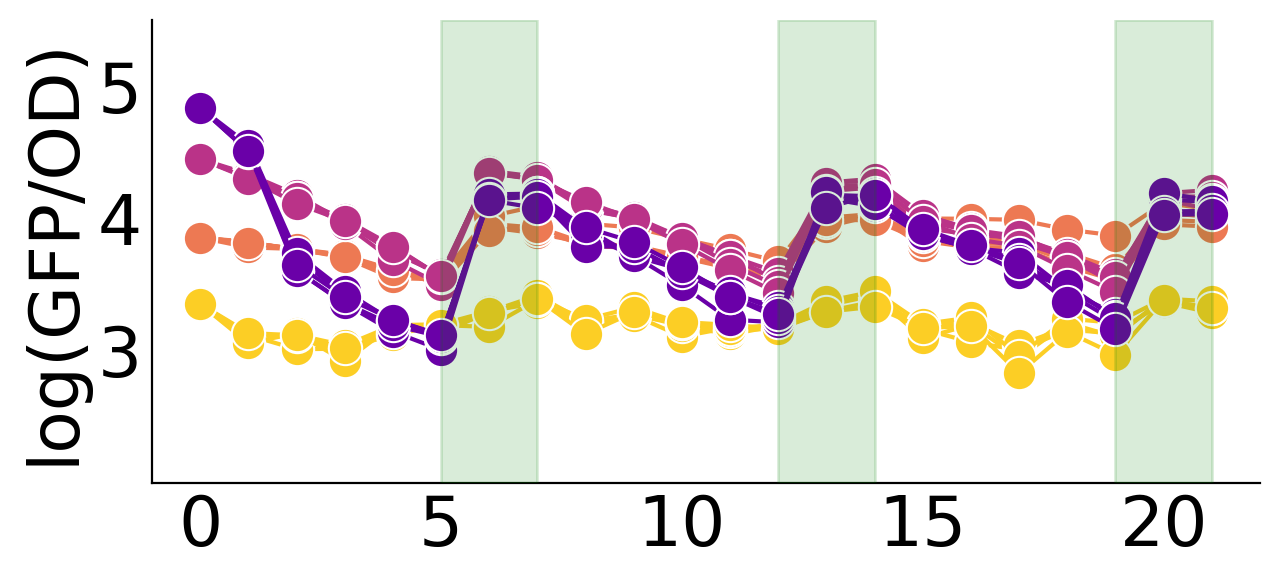

In [171]:
# Set up figure size
plt.figure(figsize=(6.5, 3), dpi=200)

plasma_colors = plt.cm.plasma_r(np.linspace(0.1, 0.8, 4))

plasmid_names = ['p15A+', 'pBR322', 'CloDF13', 'pUC']

# 3. Create a dictionary mapping each plasmid to a plasma color
# zip() pairs the names with the colors in order
custom_palette = dict(zip(plasmid_names, plasma_colors))

# Create line plot with points
ax_noKan_ = sns.lineplot(
    data=combined_noKan_df[combined_noKan_df['Plasmid']!='Chromosome'],
    x='Day',
    y='log10(GFP/OD)',
    hue='Plasmid',  
    units='Replicate',  # Creates separate lines for each ExpRep (detail in Altair)
    estimator=None,  # Don't aggregate data points
    marker='o',      # Add markers on the line
    markersize=12,   # Large marker size
    alpha=1,       # Match opacity from Altair
    palette=custom_palette ,
    legend=False     # No legend as in original
)

add_treatment_windows(ax_noKan_)

# Set axis limits to match Altair scales
plt.xlim(-1, 22)
plt.ylim(2, 5.5)

# Configure axis appearance
ax_noKan_.tick_params(axis='x', labelsize=25, length=0)
ax_noKan_.tick_params(axis='y', labelsize=25, length=0)
plt.xticks([0, 5, 10, 15, 20])  # 5 tick marks
plt.yticks([3,4, 5])  # 3 tick marks
plt.xlabel('')
plt.ylabel('log(GFP/OD)', fontsize=25)
plt.grid(False)

# Remove spines to match minimal Altair style
sns.despine(left=False, bottom=False, right=True, top=True)
# sns.move_legend(ax_revision, "upper left", bbox_to_anchor=(1, 1))

# Use tight layout to optimize spacing
plt.tight_layout()

plt.savefig('Figures_final/Figure4/Fig4G_noKan.pdf', format="pdf", bbox_inches="tight")

# Display plot
plt.show()

In [172]:
toCSV = pd.concat([finalWControl, completeDF_tet10_noP15A_NoKan], axis=0, ignore_index=True)
toCSV = toCSV.drop(columns=['tet', 'Selection'])

In [173]:
# Sort DF based on PCN + chr
toCSV["Kan"] = pd.Series(
        toCSV["Kan"], dtype="category"
    )

toCSV["Kan"] = toCSV[
            "Kan"
        ].cat.reorder_categories(
            [
                0,
                1
            ],
            ordered=True,
        )

In [174]:
toCSV.to_csv('withTransposase_GFP-OD.csv', index=False)

In [175]:
def calculateLossRateAvg(df):
    return_df_list = []
    for plasmid in PlasmidList:
        if plasmid in df['Plasmid'].values:
            copy_number = list(set(df[df['Plasmid'] == plasmid]['PCN']))[0]

            # print(plasmid)
            loss01 = \
            (df[(df['Day'] == UP_DAYS[0]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index() / \
            df[(df['Day'] == DOWN_DAYS[0]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index()).reset_index()['GFP/OD']

            KanSeries = df[(df['Day'] == UP_DAYS[1]) & (df['Plasmid'] == plasmid)]['Kan'].reset_index(drop=True)
            # print(KanSeries)

            loss02 = \
            (df[(df['Day'] == UP_DAYS[1]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index() / \
            df[(df['Day'] == DOWN_DAYS[1]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index()).reset_index()['GFP/OD']

            loss03 = \
            (df[(df['Day'] == UP_DAYS[2]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index() / \
            df[(df['Day'] == DOWN_DAYS[2]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index()).reset_index()['GFP/OD']

            loss = (loss01+loss02+loss03)/3

            generation = LossTreatmentDays * np.log2(TreatmentDilution)

            loss_rate = np.log(loss)/generation
            # print(loss_rate)
            loss_rate_mean = np.mean(loss_rate)
            loss_rate_std = np.std(loss_rate)

            loss_rate_DF = pd.DataFrame({'Plasmid': plasmid,\
                                         'PCN': copy_number,
                                         'Kan': KanSeries,
                                         'rate_of_loss_log(GFP/OD)': loss_rate})
            # print(loss_rate_DF)

            return_df_list.append(loss_rate_DF)
            # loss, type(loss), lossRate, type(lossRate)

    # reduce(lambda left, right: pd.merge(left, right, on='ID', how='outer'), dfs)
    return_df = pd.concat(return_df_list)
    return_df['Plasmid'] = pd.Series(return_df['Plasmid'], dtype="category")
    return_df["Plasmid"] = return_df[
            "Plasmid"
        ].cat.reorder_categories(
            [
                "pBR322",
                "CloDF13",
                "pUC",
            ],
            ordered=True,
        )


    return return_df

In [176]:
lossRate_tet10_df = calculateLossRateAvg(completeDF_tet10_noP15A)
lossRate_tet10_df['tet'] = 10

In [177]:
alt.Chart(lossRate_tet10_df).mark_circle(size=60).encode(
    alt.X("PCN", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_loss_log(GFP/OD)", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title='loss rate'),
    color=alt.Color('Plasmid').scale(scheme=colorScheme,reverse=True)
).properties(
    width=200,
    height=200
).facet(
    column=alt.Column('Kan', header=alt.Header(title=None))
).configure_header(
    labelFontSize=20  # Adjust this value to change the subtitle size
).properties(
    title=alt.TitleParams(
        text='loss rate per generation',
        fontSize=20,
        fontWeight='bold',
        # color='grey',
        anchor='middle'
    )
).interactive()

alt.FacetChart(...)

In [178]:
def calculateGainRateAvg(df):
    return_df_list = []
    for plasmid in PlasmidList:
        if plasmid in df['Plasmid'].values:
            copy_number = list(set(df[df['Plasmid'] == plasmid]['PCN']))[0]

            # print(plasmid)
            gain01 = \
            (df[(df['Day'] == UP_DAYS[1]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index() / \
            df[(df['Day'] == DOWN_DAYS[0]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index()).reset_index()['GFP/OD']

            KanSeries = df[(df['Day'] == UP_DAYS[1]) & (df['Plasmid'] == plasmid)]['Kan'].reset_index(drop=True)
            # print(KanSeries)

            gain02 = \
            (df[(df['Day'] == UP_DAYS[2]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index() / \
            df[(df['Day'] == DOWN_DAYS[1]) & (df['Plasmid'] == plasmid)]['GFP/OD'].reset_index()).reset_index()['GFP/OD']

            gain = (gain01+gain02)/2

            generation = SelectionTreatmentDays * np.log2(TreatmentDilution)

            gain_rate = np.log(gain)/generation
            gain_rate_mean = np.mean(gain_rate)
            gain_rate_std = np.std(gain_rate)

            gain_rate_DF = pd.DataFrame({'Plasmid': plasmid,\
                                         'PCN': copy_number,
                                         'Kan': KanSeries,
                                         'rate_of_gain_log(GFP/OD)': gain_rate})

            return_df_list.append(gain_rate_DF)

    return_df = pd.concat(return_df_list)
    return_df['Plasmid'] = pd.Series(return_df['Plasmid'], dtype="category")


    return return_df

In [179]:
gainRate_tet10_df = calculateGainRateAvg(completeDF_tet10_noP15A)
gainRate_tet10_df['tet'] = 10

In [180]:
alt.Chart(gainRate_tet10_df).mark_circle(size=60).encode(
    alt.X("PCN", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title='PCN'),
    alt.Y("rate_of_gain_log(GFP/OD)", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title='gain rate'),
    color=alt.Color('Plasmid').scale(scheme=colorScheme,reverse=True)
).properties(
    width=200,
    height=200
).facet(
    column=alt.Column('Kan', header=alt.Header(title=None))
).configure_header(
    labelFontSize=20  # Adjust this value to change the subtitle size
).properties(
    title=alt.TitleParams(
        text='gain rate per generation',
        fontSize=20,
        fontWeight='bold',
        # color='grey',
        anchor='middle'
    )
).interactive()

alt.FacetChart(...)

In [181]:
gainRate_tet10_df['Plasmid'] = pd.Series(gainRate_tet10_df['Plasmid'], dtype="category")
gainRate_tet10_df["Plasmid"] = gainRate_tet10_df["Plasmid"].cat.reorder_categories(
                [
                'pBR322',
                'CloDF13',
                'pUC',
                ],
            ordered=True,
                )

In [182]:
lossRate_tet10_df['Jumping'] = 1
gainRate_tet10_df['Jumping'] = 1

In [183]:
gainRate_tet10_df.to_csv('withJumping_gain.csv', index=False)
lossRate_tet10_df.to_csv('withJumping_loss.csv', index=False)

In [184]:
completeDF_tet10_noP15A.to_csv('withJumping_rawData_GFP.csv', index=False)

# Plot Calculated Rates

In [185]:
## import all packages here
import marimo as mo

# data analysis packages
import numpy as np
import pandas as pd

from functools import reduce

# plotting packages
import altair as alt
import seaborn as sns

# Import stats & color utilities from matplotlib
from statannotations.Annotator import Annotator
from matplotlib.colors import to_rgba
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

In [186]:
# Import GFP files
noJumping_gain_df = pd.read_csv('noJumping_gain_r.csv', dtype={'rate_of_gain_log(GFP/OD)': float, 
                        'Jumping': float})
noJumping_loss_df = pd.read_csv('noJumping_loss_r.csv', dtype={'rate_of_loss_log(GFP/OD)': float, 
                        'Jumping': float})

Jumping_gain_df = pd.read_csv('withJumping_gain.csv', dtype={'rate_of_gain_log(GFP/OD)': float, 
                        'Jumping': float})
Jumping_loss_df = pd.read_csv('withJumping_loss.csv', dtype={'rate_of_loss_log(GFP/OD)': float, 
                        'Jumping': float})

# Import qPCR files
noJumping_gain_qPCR_df = pd.read_csv('noJumping_gain_qPCR_r.csv')
noJumping_loss_qPCR_df = pd.read_csv('noJumping_loss_qPCR_r.csv')

Jumping_gain_qPCR_df = pd.read_csv('withJumping_gain_qPCR.csv')
Jumping_loss_qPCR_df = pd.read_csv('withJumping_loss_qPCR.csv')

In [187]:
# A function to sort dataframe based on plasmid copy number: p15A < pBR < CloDF < pUC

def sortName(df):
    # For GFP results
    if 'Plasmid' in df.columns.values:       
        df['Plasmid'] = pd.Series(
            df['Plasmid'], dtype="category"
        )  
        
        # Change pBR322 to pBR & CloDF13 to CloDF & p15A++ to p15A here for consistency
        df['Plasmid'] = df['Plasmid'].replace({
            'pBR322': 'pBR',
            'CloDF13': 'CloDF'
        })
    # For qPCR results
    else:
        df['PCN'] = pd.Series(
            df['PCN'], dtype="category"
        )  
        # Change pBR322 to pBR
        df['PCN'] = df['PCN'].replace({
            'p15A++': 'p15A',
            'pBR322': 'pBR',
        })
        
    return df

In [188]:
## Rename & add some column names for consistency here:
# GFP data
noJumping_gain_df.rename(columns={'rate_of_gain_log(GFP/OD)': 'rate_log(GFP/OD)'}, inplace=True)
noJumping_loss_df.rename(columns={'rate_of_loss_log(GFP/OD)': 'rate_log(GFP/OD)'}, inplace=True)
Jumping_gain_df.rename(columns={'rate_of_gain_log(GFP/OD)': 'rate_log(GFP/OD)'}, inplace=True)
Jumping_loss_df.rename(columns={'rate_of_loss_log(GFP/OD)': 'rate_log(GFP/OD)'}, inplace=True)

noJumping_gain_df.rename(columns={'Jumping': 'Transposase'}, inplace=True)
noJumping_loss_df.rename(columns={'Jumping': 'Transposase'}, inplace=True)
Jumping_gain_df.rename(columns={'Jumping': 'Transposase'}, inplace=True)
Jumping_loss_df.rename(columns={'Jumping': 'Transposase'}, inplace=True)

noJumping_gain_df['gain'] = 1
noJumping_loss_df['gain'] = 0
Jumping_gain_df['gain'] = 1
Jumping_loss_df['gain'] = 0

noJumping_gain_df_Use = noJumping_gain_df[['Plasmid', 'Kan', 'rate_log(GFP/OD)', 'Transposase', 'gain']]
noJumping_loss_df_Use = noJumping_loss_df[['Plasmid', 'Kan', 'rate_log(GFP/OD)', 'Transposase', 'gain']]
Jumping_gain_df_Use = Jumping_gain_df[['Plasmid', 'Kan', 'rate_log(GFP/OD)', 'Transposase', 'gain']]
Jumping_loss_df_Use = Jumping_loss_df[['Plasmid', 'Kan', 'rate_log(GFP/OD)', 'Transposase', 'gain']]

noJumping_gain_df_Use = sortName(noJumping_gain_df_Use)
noJumping_loss_df_Use = sortName(noJumping_loss_df_Use)
Jumping_gain_df_Use = sortName(Jumping_gain_df_Use)
Jumping_loss_df_Use = sortName(Jumping_loss_df_Use)

# qPCR data
noJumping_gain_qPCR_df.rename(columns={'rate_of_gain_log(transposon copy)': 'rate_log(transposon copy)'}, inplace=True)
noJumping_loss_qPCR_df.rename(columns={'rate_of_loss_log(transposon copy)': 'rate_log(transposon copy)'}, inplace=True)
Jumping_gain_qPCR_df.rename(columns={'rate_of_gain_log(transposon copy)': 'rate_log(transposon copy)'}, inplace=True)
Jumping_loss_qPCR_df.rename(columns={'rate_of_loss_log(transposon copy)': 'rate_log(transposon copy)'}, inplace=True)

noJumping_gain_qPCR_df.rename(columns={'rate_of_gain_log(plasmid copy)': 'rate_log(plasmid copy)'}, inplace=True)
noJumping_loss_qPCR_df.rename(columns={'rate_of_loss_log(plasmid copy)': 'rate_log(plasmid copy)'}, inplace=True)
Jumping_gain_qPCR_df.rename(columns={'rate_of_gain_log(plasmid copy)': 'rate_log(plasmid copy)'}, inplace=True)
Jumping_loss_qPCR_df.rename(columns={'rate_of_loss_log(plasmid copy)': 'rate_log(plasmid copy)'}, inplace=True)

noJumping_gain_qPCR_df.rename(columns={'rate_of_gain_log(T/P)': 'rate_log(T/P)'}, inplace=True)
noJumping_loss_qPCR_df.rename(columns={'rate_of_loss_log(T/P)': 'rate_log(T/P)'}, inplace=True)
Jumping_gain_qPCR_df.rename(columns={'rate_of_gain_log(T/P)': 'rate_log(T/P)'}, inplace=True)
Jumping_loss_qPCR_df.rename(columns={'rate_of_loss_log(T/P)': 'rate_log(T/P)'}, inplace=True)

noJumping_gain_qPCR_df.rename(columns={'Jumping': 'Transposase'}, inplace=True)
noJumping_loss_qPCR_df.rename(columns={'Jumping': 'Transposase'}, inplace=True)
Jumping_gain_qPCR_df.rename(columns={'Jumping': 'Transposase'}, inplace=True)
Jumping_loss_qPCR_df.rename(columns={'Jumping': 'Transposase'}, inplace=True)

noJumping_gain_qPCR_df['gain'] = 1
noJumping_loss_qPCR_df['gain'] = 0
Jumping_gain_qPCR_df['gain'] = 1
Jumping_loss_qPCR_df['gain'] = 0

noJumping_gain_qPCR_df_Use = noJumping_gain_qPCR_df[['PCN', 'Kan', 'rate_log(transposon copy)', 'rate_log(plasmid copy)', 'rate_log(T/P)', 'Transposase', 'gain', 'averagePCN']]
noJumping_loss_qPCR_df_Use = noJumping_loss_qPCR_df[['PCN', 'Kan', 'rate_log(transposon copy)', 'rate_log(plasmid copy)', 'rate_log(T/P)', 'Transposase', 'gain', 'averagePCN']]
Jumping_gain_qPCR_df_Use = Jumping_gain_qPCR_df[['PCN', 'Kan', 'rate_log(transposon copy)', 'rate_log(plasmid copy)', 'rate_log(T/P)', 'Transposase', 'gain', 'averagePCN']]
Jumping_loss_qPCR_df_Use = Jumping_loss_qPCR_df[['PCN', 'Kan', 'rate_log(transposon copy)', 'rate_log(plasmid copy)', 'rate_log(T/P)', 'Transposase', 'gain', 'averagePCN']]

noJumping_gain_qPCR_df_Use = sortName(noJumping_gain_qPCR_df_Use)
noJumping_loss_qPCR_df_Use = sortName(noJumping_loss_qPCR_df_Use)
Jumping_gain_qPCR_df_Use = sortName(Jumping_gain_qPCR_df_Use)
Jumping_loss_qPCR_df_Use = sortName(Jumping_loss_qPCR_df_Use)

/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_67811/3076739717.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Plasmid'] = pd.Series(
/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_67811/3076739717.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Plasmid'] = df['Plasmid'].replace({
/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_67811/3076739717.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc

In [189]:
rows_to_move = noJumping_loss_df_Use[noJumping_loss_df_Use['Transposase'] == 1]
noJumping_loss_df_Use = noJumping_loss_df_Use[noJumping_loss_df_Use['Transposase'] != 1]
Jumping_loss_df_Use = pd.concat([Jumping_loss_df_Use, rows_to_move], ignore_index=True)

In [190]:
rows_to_move = noJumping_gain_df_Use[noJumping_gain_df_Use['Transposase'] == 1]
noJumping_gain_df_Use = noJumping_gain_df_Use[noJumping_gain_df_Use['Transposase'] != 1]
Jumping_gain_df_Use = pd.concat([Jumping_gain_df_Use, rows_to_move], ignore_index=True)

In [191]:
combined_df = pd.concat([noJumping_gain_df_Use, noJumping_loss_df_Use, Jumping_gain_df_Use, Jumping_loss_df_Use], ignore_index=True)

# qPCR data processing
combined_qPCR_df = pd.concat([noJumping_gain_qPCR_df_Use, noJumping_loss_qPCR_df_Use, Jumping_gain_qPCR_df_Use, Jumping_loss_qPCR_df_Use], ignore_index=True)

# Concatenate the existing DataFrame with the new rows
combined_qPCR_df['rate_log(transposon copy)'] = combined_qPCR_df['rate_log(transposon copy)'].fillna(0)

In [193]:
# GFP files
noJumping_GFP_df = pd.read_csv('PlotCalculatedRates/noJumping_rawData_GFP.csv')
Jumping_GFP_df = pd.read_csv('PlotCalculatedRates/withJumping_rawData_GFP.csv')

# qPCR files
noJumping_qPCR_df = pd.read_csv('PlotCalculatedRates/noJumping_rawData.csv')
Jumping_qPCR_df = pd.read_csv('PlotCalculatedRates/withJumping_rawData.csv')

# rename qPCR files' column names to be consistent with the GFP files' column names
noJumping_qPCR_df = noJumping_qPCR_df.rename(columns={'PCN': 'Plasmid'})
Jumping_qPCR_df = Jumping_qPCR_df.rename(columns={'PCN': 'Plasmid'})

noJumping_qPCR_df = noJumping_qPCR_df.rename(columns={'ExpRep': 'Replicate'})
Jumping_qPCR_df = Jumping_qPCR_df.rename(columns={'ExpRep': 'Replicate'})

In [194]:
# Replace multiple parameter values for plotting consistency
# Original
noJumping_qPCR_df['Plasmid'] = noJumping_qPCR_df['Plasmid'].replace({'CloDF': 'CloDF13'})
Jumping_qPCR_df['Plasmid'] = Jumping_qPCR_df['Plasmid'].replace({'CloDF': 'CloDF13'})

noJumping_qPCR_df['Kan'] = noJumping_qPCR_df['Kan'].replace({'Kan': 1})
Jumping_qPCR_df['Kan'] = Jumping_qPCR_df['Kan'].replace({'Kan': 1})
noJumping_qPCR_df['Kan'] = noJumping_qPCR_df['Kan'].replace({'noKan': 0})
Jumping_qPCR_df['Kan'] = Jumping_qPCR_df['Kan'].replace({'noKan': 0})

In [195]:
# Merge the two DataFrames on matching columns
merged_df = pd.merge(noJumping_qPCR_df, noJumping_GFP_df, on=['Plasmid', 'Day', 'Replicate', 'Kan'])
# Merge the two DataFrames on matching columns
merged_df_J = pd.merge(Jumping_qPCR_df, Jumping_GFP_df, on=['Plasmid', 'Day', 'Replicate', 'Kan'])

# Supplementary Figure 4

In [196]:
# Scatter plot of GFP/OD vs transposon copy for no jumping data
SF4A = alt.Chart(merged_df).mark_point(size=100, opacity=0.2).encode(
    alt.X("log10(GFP/OD):Q", scale=alt.Scale(domain=[2.8, 5]), axis=alt.Axis(labelFontSize=30, tickCount=2, titleFontSize=15, grid=False), title= None),
    alt.Y("log(transposon copy):Q", scale=alt.Scale(domain=[-5, 5]), axis=alt.Axis(labelFontSize=30, tickCount=2, ticks=False, grid=False, title=None)),
).properties(
    title='',
    width=150,
    height=300
)

SF4A

alt.Chart(...)

In [197]:
SF4B = alt.Chart(merged_df).mark_point(size=100, opacity=0.2).encode(
    alt.X("log10(GFP/OD):Q", scale=alt.Scale(domain=[2.8, 5]),
          axis=alt.Axis(labelFontSize=30, values=[3, 5], titleFontSize=15, grid=False), title=None),
    alt.Y("log(transposon copy):Q", scale=alt.Scale(domain=[0, 5]),
          axis=alt.Axis(labelFontSize=30, tickCount=1, ticks=False, grid=False, title=None)),
).transform_filter(
    alt.datum["log(transposon copy)"] >= 0
).properties(title='', width=150, height=150)

SF4B

alt.Chart(...)

In [198]:
# Scatter plot of GFP/OD vs transposon copy for with jumping data
J = alt.Chart(merged_df_J).mark_point(size=100, opacity=0.2).encode(
    alt.X("log10(GFP/OD):Q", scale=alt.Scale(domain=[2.8, 5]), axis=alt.Axis(labelFontSize=30, tickCount=2, titleFontSize=15, grid=False), title= None),
    alt.Y("log(transposon copy):Q", scale=alt.Scale(domain=[-5, 5]), axis=alt.Axis(labelFontSize=30, tickCount=2, ticks=False, grid=False, title=None)),
).properties(
    title='',
    width=150,
    height=300
)

J

alt.Chart(...)

In [199]:
J_B = alt.Chart(merged_df_J).mark_point(size=100, opacity=0.2).encode(
    alt.X("log10(GFP/OD):Q",scale=alt.Scale(domain=[2.8, 5]),
        axis=alt.Axis(labelFontSize=30, tickCount=2, grid=False),title=None),
    alt.Y(
        "log(transposon copy):Q",scale=alt.Scale(domain=[0, 5]),
        axis=alt.Axis(labelFontSize=30, tickCount=1, ticks=False, grid=False, title=None))
).transform_filter(
    alt.datum["log(transposon copy)"] >= 0
).properties(title='',width=150,height=150)

J_B

alt.Chart(...)

In [200]:
# Plot data with jumping and without jumping together
SF4A_revision = SF4A + J
SF4A_revision

alt.LayerChart(...)

In [201]:
combined_r = SF4B + J_B
combined_r

alt.LayerChart(...)

# Figure 3D,F; Figure 4D,F,H; Supplementary Fig. S7B; Supplementary Fig. S8B,D,F

In [202]:
def plotStatQPCR(df, hueVar='Kan', ylim=0.5, Name='test.pdf', toPlot="rate_log(transposon copy)", ax=None):
    if ax is None:
        plt.figure(figsize=(5, 3))
        ax = plt.gca()

    plasmid_colors = plt.cm.plasma_r(np.linspace(0.1, 0.8, 4))
    silver = mcolors.to_rgba("#D5D5D5")
    pairs = [(("p15A", 1), ("p15A", 0)), (("pBR", 1), ("pBR", 0)), (("CloDF", 1), ("CloDF", 0)), (("pUC", 1), ("pUC", 0))]

    if "Chromosome" in df.PCN.values:
        order_list = ["Chromosome", "p15A", "pBR", "CloDF", "pUC"]
        colors_hue0 = [tuple(list(c[:-1]) + [0.2]) for c in plasmid_colors]
        colors_hue1 = [silver] + [tuple(list(c[:-1]) + [1.0]) for c in plasmid_colors]
    else:
        order_list = ["p15A", "pBR", "CloDF", "pUC"]
        colors_hue0 = [tuple(list(c[:-1]) + [0.2]) for c in plasmid_colors]
        colors_hue1 = [tuple(list(c[:-1]) + [1.0]) for c in plasmid_colors]

    hue_order = [0, 1]

    for i, plasmid in enumerate(order_list):
        for hue in hue_order:
            vals = df[(df["PCN"] == plasmid) & (df[hueVar] == hue)][toPlot].dropna()
            if len(vals) == 0: continue
            if plasmid == "Chromosome" and hue == 0: continue
            x = i + (-0.2 if hue == 0 else 0.2)
            color = (colors_hue0 if hue == 0 else colors_hue1)[i - 1 if "Chromosome" in df.PCN.values and hue == 0 else i]
            mean, sd = vals.mean(), vals.std()
            ax.scatter([x] * len(vals), vals, color=color, s=50, alpha=0.2 if hue == 0 else 1.0, zorder=5)
            ax.errorbar(x, mean, yerr=sd, fmt='none', ecolor='black', elinewidth=2, capsize=4, capthick=2, zorder=10)

            if hue == 0:
                base = np.array(plasmid_colors[i - 1 if "Chromosome" in df.PCN.values else i][:3])
                mean_color = tuple(base + (1 - base) * 0.45)
            else:
                base = np.array(color[:3])
                mean_color = tuple(base * 0.65)

            ax.scatter(x, mean, s=70, color=mean_color, edgecolor='black', linewidth=0.7, zorder=11)

    ax.set_xlim(-0.5, len(order_list) - 0.5)
    ax.set_xticks(range(len(order_list)))
    ax.set_xticklabels(["Chr" if lab == "Chromosome" else lab for lab in order_list])
    sns.despine(ax=ax, left=False, bottom=False, right=True, top=True)

    annotator = Annotator(ax, pairs, data=df, x="PCN", y=toPlot, hue=hueVar, order=order_list, hue_order=hue_order)
    annotator.configure(test="Mann-Whitney", text_format="star", loc="outside", fontsize=20)
    annotator.apply_and_annotate()

    ax.set_ylabel(r"$\mathrm{gen}^{-1}$", fontsize=30)
    ax.yaxis.set_label_coords(-0.15, 0.5)
    ax.set_xlabel("")
    ax.set_ylim(-0.01, ylim)
    ax.set_yticks([0, ylim])
    ax.set_yticklabels(["0", ylim])
    ax.tick_params(axis="y", labelsize=30, left=False)
    ax.tick_params(axis="x", labelsize=20)

    if ax is not None:
        pass

    fc_results = []
    for (cat1, hue1), (cat2, hue2) in pairs:
        mean_treatment = df[(df["PCN"] == cat2) & (df[hueVar] == hue2)][toPlot].mean()
        mean_control = df[(df["PCN"] == cat1) & (df[hueVar] == hue1)][toPlot].mean()
        fc_raw = mean_treatment / mean_control if mean_control != 0 else np.nan
        fc_results.append({"Plasmid": cat1, f"Mean ({hueVar}={hue2})": mean_treatment, f"Mean ({hueVar}={hue1})": mean_control, "Fold Change (Raw)": fc_raw})

    return pd.DataFrame(fc_results)

In [203]:
def plotStatGFP(df, hueVar='Kan', ylim=0.5, Name='test.pdf', toPlot="rate_log(GFP/OD)", ax=None):
    if ax is None:
        plt.figure(figsize=(5, 3))
        ax = plt.gca()

    plasmid_colors = plt.cm.plasma_r(np.linspace(0.1, 0.8, 4))
    silver = mcolors.to_rgba("#D5D5D5")
    pairs = [(("p15A", 1), ("p15A", 0)), (("pBR", 1), ("pBR", 0)), (("CloDF", 1), ("CloDF", 0)), (("pUC", 1), ("pUC", 0))]

    if "Chromosome" in df.Plasmid.values:
        order_list = ["Chromosome", "p15A", "pBR", "CloDF", "pUC"]
        colors_hue0 = [tuple(list(c[:-1]) + [0.2]) for c in plasmid_colors]
        colors_hue1 = [silver] + [tuple(list(c[:-1]) + [1.0]) for c in plasmid_colors]
    else:
        order_list = ["p15A", "pBR", "CloDF", "pUC"]
        colors_hue0 = [tuple(list(c[:-1]) + [0.2]) for c in plasmid_colors]
        colors_hue1 = [tuple(list(c[:-1]) + [1.0]) for c in plasmid_colors]

    hue_order = [0, 1]

    for i, plasmid in enumerate(order_list):
        for hue in hue_order:
            vals = df[(df["Plasmid"] == plasmid) & (df[hueVar] == hue)][toPlot].dropna()
            if len(vals) == 0: continue
            if plasmid == "Chromosome" and hue == 0: continue

            x = i + (-0.2 if hue == 0 else 0.2)
            color = (colors_hue0 if hue == 0 else colors_hue1)[i - 1 if "Chromosome" in df.Plasmid.values and hue == 0 else i]
            mean, sd = vals.mean(), vals.std()

            ax.scatter([x] * len(vals), vals, color=color, s=50, alpha=0.2 if hue == 0 else 1.0, zorder=5)
            ax.errorbar(x, mean, yerr=sd, fmt='none', ecolor='black', elinewidth=2, capsize=4, capthick=2, zorder=10)

            if hue == 0:
                base = np.array(plasmid_colors[i - 1 if "Chromosome" in df.Plasmid.values else i][:3])
                mean_color = tuple(base + (1 - base) * 0.45)
            else:
                base = np.array(color[:3])
                mean_color = tuple(base * 0.65)

            ax.scatter(x, mean, s=70, color=mean_color, edgecolor='black', linewidth=0.7, zorder=11)

    ax.set_xlim(-0.5, len(order_list) - 0.5)
    ax.set_xticks(range(len(order_list)))
    ax.set_xticklabels(["Chr" if lab == "Chromosome" else lab for lab in order_list])
    sns.despine(ax=ax, left=False, bottom=False, right=True, top=True)

    annotator = Annotator(ax, pairs, data=df, x="Plasmid", y=toPlot, hue=hueVar, order=order_list, hue_order=hue_order)
    annotator.configure(test="Mann-Whitney", text_format="star", loc="outside", fontsize=20)
    annotator.apply_and_annotate()

    ax.set_ylabel(r"$\mathrm{gen}^{-1}$", fontsize=30)
    ax.yaxis.set_label_coords(-0.15, 0.5)
    ax.set_xlabel("")
    ax.set_ylim(-0.01, ylim)
    ax.set_yticks([0, ylim])
    ax.set_yticklabels(["0", ylim])
    ax.tick_params(axis="y", labelsize=30, left=False)
    ax.tick_params(axis="x", labelsize=20)

    fc_results = []
    for (cat1, hue1), (cat2, hue2) in pairs:
        mean_treatment = df[(df["Plasmid"] == cat2) & (df[hueVar] == hue2)][toPlot].mean()
        mean_control = df[(df["Plasmid"] == cat1) & (df[hueVar] == hue1)][toPlot].mean()
        fc_raw = mean_treatment / mean_control if mean_control != 0 else np.nan
        fc_results.append({"Plasmid": cat1, f"Mean ({hueVar}={hue2})": mean_treatment, f"Mean ({hueVar}={hue1})": mean_control, "Fold Change (Raw)": fc_raw})

    return pd.DataFrame(fc_results)

### Figure 3
**Saved outputs:** `Fig3F_GFP_Loss.pdf`

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=0.000e+00
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:4.206e-01 U_stat=1.700e+01
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:8.413e-01 U_stat=1.400e+01


/Users/kristenlok/Library/Python/3.8/lib/python/site-packages/statannotations/compat.py:891: FutureWarning: The default dtype for empty Series will be 'object' instead of 'float64' in a future version. Specify a dtype explicitly to silence this warning.
  return pd.Series([])


,Plasmid,Mean (Transposase=0),Mean (Transposase=1),Fold Change (Raw)
0,p15A,0.008787,0.006270,1.401342
1,pBR,0.002666,0.005114,0.521355
2,CloDF,0.013970,0.013252,1.054187
3,pUC,0.038019,0.039302,0.967355


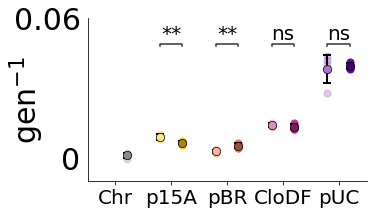

In [204]:
filtered_df_loss = combined_df[(combined_df['gain']==0) & (combined_df['Kan']==1)]

plotStatGFP(filtered_df_loss, 'Transposase', 0.06, 'Figures_final/Figure3/Fig3F_GFP_Loss.pdf')

### Figure 3
**Saved outputs:** `Fig3D_qPCR_Loss.pdf`

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=0.000e+00
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.476e-01 U_stat=1.600e+01
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=0.000e+00


/Users/kristenlok/Library/Python/3.8/lib/python/site-packages/statannotations/compat.py:891: FutureWarning: The default dtype for empty Series will be 'object' instead of 'float64' in a future version. Specify a dtype explicitly to silence this warning.
  return pd.Series([])


,Plasmid,Mean (Transposase=0),Mean (Transposase=1),Fold Change (Raw)
0,p15A,0.005686,0.000365,15.590406
1,pBR,0.000364,0.006968,0.052248
2,CloDF,0.015688,0.015136,1.036503
3,pUC,0.043401,0.057944,0.749018


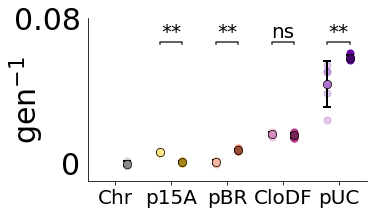

In [205]:
filtered_qPCR_df_loss = combined_qPCR_df[(combined_qPCR_df['gain']==0) & (combined_qPCR_df['Kan']==1)]

plotStatQPCR(filtered_qPCR_df_loss, 'Transposase', 0.08, 'Figures_final/Figure3/Fig3D_qPCR_Loss.pdf')

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=0.000e+00
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.476e-01 U_stat=1.600e+01
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=0.000e+00


/Users/kristenlok/Library/Python/3.8/lib/python/site-packages/statannotations/compat.py:891: FutureWarning: The default dtype for empty Series will be 'object' instead of 'float64' in a future version. Specify a dtype explicitly to silence this warning.
  return pd.Series([])


,Plasmid,Mean (Transposase=0),Mean (Transposase=1),Fold Change (Raw)
0,p15A,0.005686,0.000365,15.590406
1,pBR,0.000364,0.006968,0.052248
2,CloDF,0.015688,0.015136,1.036503
3,pUC,0.043401,0.057944,0.749018


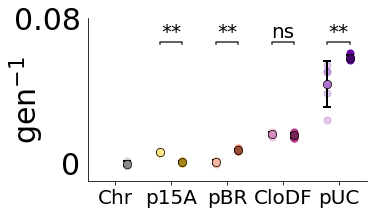

In [206]:
filtered_qPCR_df_loss = combined_qPCR_df[(combined_qPCR_df['gain']==0) & (combined_qPCR_df['Kan']==1)]

plotStatQPCR(filtered_qPCR_df_loss, 'Transposase', 0.08, 'Figures_final/Figure3/Fig3D_qPCR_Loss.pdf')

### Figure 3
**Saved outputs:** `Fig3F_GFP_Gain.pdf`

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.476e-01 U_stat=1.600e+01
pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.508e-01 U_stat=5.000e+00
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.587e-02 U_stat=1.000e+00
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:6.905e-01 U_stat=1.500e+01


/Users/kristenlok/Library/Python/3.8/lib/python/site-packages/statannotations/compat.py:891: FutureWarning: The default dtype for empty Series will be 'object' instead of 'float64' in a future version. Specify a dtype explicitly to silence this warning.
  return pd.Series([])


,Plasmid,Mean (Transposase=0),Mean (Transposase=1),Fold Change (Raw)
0,p15A,0.017534,0.015597,1.124244
1,pBR,0.008686,0.012385,0.701331
2,CloDF,0.017867,0.024362,0.733384
3,pUC,0.074115,0.067501,1.097976


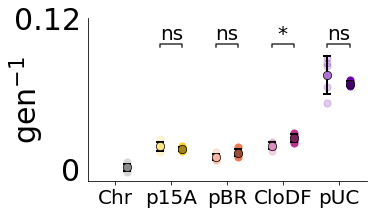

In [207]:
filtered_df_gain = combined_df[(combined_df['gain']==1) & (combined_df['Kan']==1)]

plotStatGFP(filtered_df_gain, 'Transposase', 0.12, 'Figures_final/Figure3/Fig3F_GFP_Gain.pdf')

### Figure 3
**Saved outputs:** `Fig3D_qPCR_Gain.pdf`

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:4.206e-01 U_stat=1.700e+01
pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=0.000e+00
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=0.000e+00
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:8.413e-01 U_stat=1.400e+01


/Users/kristenlok/Library/Python/3.8/lib/python/site-packages/statannotations/compat.py:891: FutureWarning: The default dtype for empty Series will be 'object' instead of 'float64' in a future version. Specify a dtype explicitly to silence this warning.
  return pd.Series([])


,Plasmid,Mean (Transposase=0),Mean (Transposase=1),Fold Change (Raw)
0,p15A,0.001701,0.000925,1.838404
1,pBR,-0.000402,0.014454,-0.027797
2,CloDF,0.008982,0.025678,0.349784
3,pUC,0.087728,0.105977,0.827798


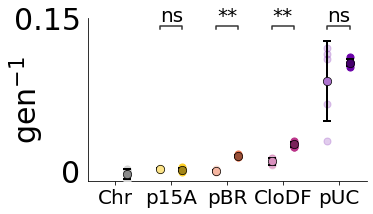

In [208]:
filtered_qPCR_df_gain = combined_qPCR_df[(combined_qPCR_df['gain']==1) & (combined_qPCR_df['Kan']==1)]

plotStatQPCR(filtered_qPCR_df_gain, 'Transposase', 0.15, 'Figures_final/Figure3/Fig3D_qPCR_Gain.pdf')

# Figure 3D,F combined
**Saved outputs:** `Figure3DF.pdf`

/Users/kristenlok/Library/Python/3.8/lib/python/site-packages/statannotations/compat.py:891: FutureWarning: The default dtype for empty Series will be 'object' instead of 'float64' in a future version. Specify a dtype explicitly to silence this warning.
  return pd.Series([])


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=0.000e+00
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.476e-01 U_stat=1.600e+01
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=0.000e+00


/Users/kristenlok/Library/Python/3.8/lib/python/site-packages/statannotations/compat.py:891: FutureWarning: The default dtype for empty Series will be 'object' instead of 'float64' in a future version. Specify a dtype explicitly to silence this warning.
  return pd.Series([])


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:4.206e-01 U_stat=1.700e+01
pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=0.000e+00
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=0.000e+00
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:8.413e-01 U_stat=1.400e+01
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01


/Users/kristenlok/Library/Python/3.8/lib/python/site-packages/statannotations/compat.py:891: FutureWarning: The default dtype for empty Series will be 'object' instead of 'float64' in a future version. Specify a dtype explicitly to silence this warning.
  return pd.Series([])


pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=0.000e+00
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:4.206e-01 U_stat=1.700e+01
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:8.413e-01 U_stat=1.400e+01
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.476e-01 U_stat=1.600e+01


/Users/kristenlok/Library/Python/3.8/lib/python/site-packages/statannotations/compat.py:891: FutureWarning: The default dtype for empty Series will be 'object' instead of 'float64' in a future version. Specify a dtype explicitly to silence this warning.
  return pd.Series([])


pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.508e-01 U_stat=5.000e+00
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.587e-02 U_stat=1.000e+00
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:6.905e-01 U_stat=1.500e+01


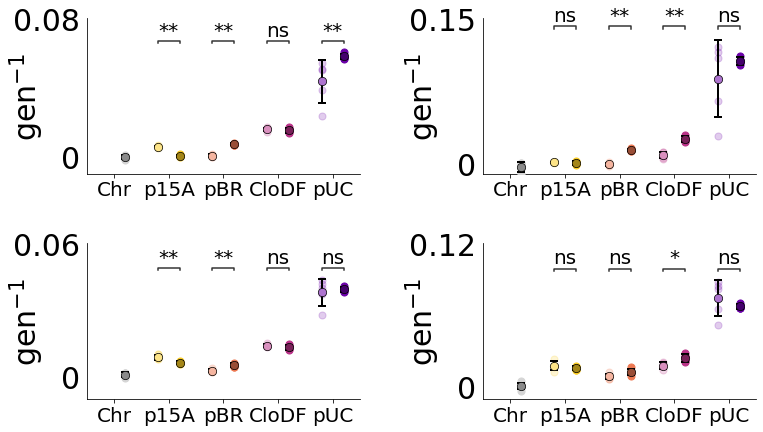

In [209]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

# F3D_loss — qPCR
filtered_qPCR_df_loss = combined_qPCR_df[(combined_qPCR_df['gain'] == 0) & (combined_qPCR_df['Kan'] == 1)]
plotStatQPCR(filtered_qPCR_df_loss, 'Transposase', 0.08, 'Figures_final/Figure3/Fig3D_qPCR_Loss.pdf', ax=axes[0, 0])

# F3D_gain — qPCR
filtered_qPCR_df_gain = combined_qPCR_df[(combined_qPCR_df['gain'] == 1) & (combined_qPCR_df['Kan'] == 1)]
plotStatQPCR(filtered_qPCR_df_gain, 'Transposase', 0.15, 'Figures_final/Figure3/Fig3D_qPCR_Gain.pdf', ax=axes[0, 1])

# F3F_loss — GFP
filtered_df_loss = combined_df[(combined_df['gain'] == 0) & (combined_df['Kan'] == 1)]
plotStatGFP(filtered_df_loss, 'Transposase', 0.06, 'Figures_final/Figure3/Fig3F_GFP_Loss.pdf', ax=axes[1, 0])

# F3F_gain — GFP
filtered_df_gain = combined_df[(combined_df['gain'] == 1) & (combined_df['Kan'] == 1)]
plotStatGFP(filtered_df_gain, 'Transposase', 0.12, 'Figures_final/Figure3/Fig3F_GFP_Gain.pdf', ax=axes[1, 1])

# Move y-axis labels closer to their axes
for ax in axes[:, 0]:
    ax.yaxis.set_label_coords(-0.15, 0.5)

for ax in axes[:, 1]:
    ax.yaxis.set_label_coords(-0.15, 0.5)

fig.subplots_adjust(wspace=0.45, hspace=0.45)
plt.savefig('Figures_final/Figure3/Figure3DF.pdf', format='pdf', bbox_inches='tight')
plt.show()

### Figure 4
**Saved outputs:** `Fig4H_GFP_Gain.pdf`

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:4.206e-01 U_stat=1.700e+01
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01


,Plasmid,Mean (Kan=0),Mean (Kan=1),Fold Change (Raw)
0,p15A,0.016817,0.015597,1.078265
1,pBR,0.034851,0.012385,2.814002
2,CloDF,0.058240,0.024362,2.390570
3,pUC,0.076413,0.067501,1.132019


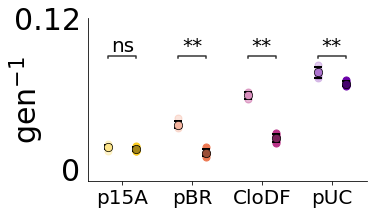

In [210]:
# Filter your data as in your original code
filtered_df_gain_kan = combined_df[(combined_df['gain']==1) & (combined_df['Transposase']==1) & (combined_df['Plasmid'] != 'Chromosome')]
plotStatGFP(filtered_df_gain_kan, 'Kan', 0.12, 'Figures_final/Figure4/Fig4H_GFP_Gain.pdf')

### Figure 4
**Saved outputs:** `Fig4F_qPCR_Gain.pdf`

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:2.222e-01 U_stat=1.900e+01
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:9.524e-02 U_stat=2.100e+01


,Plasmid,Mean (Kan=0),Mean (Kan=1),Fold Change (Raw)
0,p15A,0.002178,0.000925,2.353541
1,pBR,0.029942,0.014454,2.071596
2,CloDF,0.054946,0.025678,2.139781
3,pUC,0.109954,0.105977,1.037523


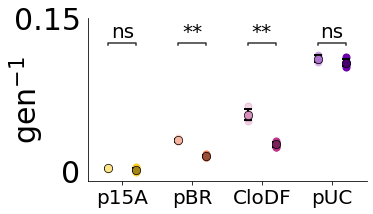

In [211]:
filtered_qpcr_df_gain_kan = combined_qPCR_df[(combined_qPCR_df['gain']==1) & (combined_qPCR_df['Transposase']==1) & (combined_qPCR_df['PCN'] != 'Chromosome')]
plotStatQPCR(filtered_qpcr_df_gain_kan, 'Kan', 0.15, 'Figures_final/Figure4/Fig4F_qPCR_Gain.pdf')

### Figure 4
**Saved outputs:** `Fig4D_qPCR_PCN_Gain.pdf`

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.556e-02 U_stat=2.200e+01
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01


,Plasmid,Mean (Kan=0),Mean (Kan=1),Fold Change (Raw)
0,p15A,0.016483,0.006043,2.727553
1,pBR,0.027350,0.011476,2.383293
2,CloDF,0.054954,0.022735,2.417131
3,pUC,0.099015,0.015653,6.325664


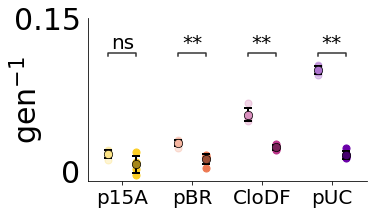

In [212]:
# PCN
plotStatQPCR(filtered_qpcr_df_gain_kan, 'Kan', 0.15, 'Figures_final/Figure4/Fig4D_qPCR_PCN_Gain.pdf', 'rate_log(plasmid copy)')

### Figure 4
**Saved outputs:** `Fig4H_GFP_Loss.pdf`

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.508e-01 U_stat=2.000e+01
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01


,Plasmid,Mean (Kan=0),Mean (Kan=1),Fold Change (Raw)
0,p15A,0.007105,0.006270,1.133158
1,pBR,0.011794,0.005114,2.306397
2,CloDF,0.025282,0.013252,1.907757
3,pUC,0.042726,0.039302,1.087117


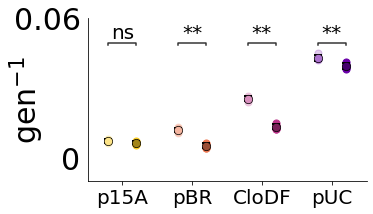

In [213]:
filtered_df_loss_kan = combined_df[(combined_df['gain']==0) & (combined_df['Transposase']==1) & (combined_df['Plasmid'] != 'Chromosome')]
plotStatGFP(filtered_df_loss_kan, 'Kan', 0.06, 'Figures_final/Figure4/Fig4H_GFP_Loss.pdf')

### Figure 4
**Saved outputs:** `Fig4F_qPCR_Loss.pdf`

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:3.095e-01 U_stat=1.800e+01


,Plasmid,Mean (Kan=0),Mean (Kan=1),Fold Change (Raw)
0,p15A,0.002228,0.000365,6.110685
1,pBR,0.016381,0.006968,2.350951
2,CloDF,0.030278,0.015136,2.000436
3,pUC,0.059139,0.057944,1.020624


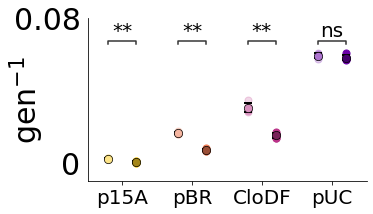

In [214]:
# Filter your data as in your original code
filtered_qpcr_df_loss_kan = combined_qPCR_df[(combined_qPCR_df['gain']==0) & (combined_qPCR_df['Transposase']==1) & (combined_qPCR_df['PCN'] != 'Chromosome')]
plotStatQPCR(filtered_qpcr_df_loss_kan, 'Kan', 0.08, 'Figures_final/Figure4/Fig4F_qPCR_Loss.pdf')

### Figure 4
**Saved outputs:** `Fig4D_qPCR_PCN_Loss.pdf`

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01


,Plasmid,Mean (Kan=0),Mean (Kan=1),Fold Change (Raw)
0,p15A,0.014796,0.003686,4.013941
1,pBR,0.016175,0.005501,2.940444
2,CloDF,0.030237,0.013440,2.249727
3,pUC,0.063241,0.027196,2.325376


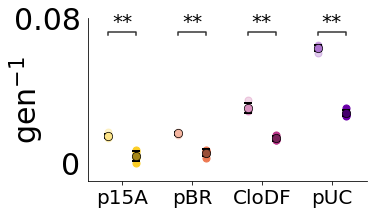

In [215]:
plotStatQPCR(filtered_qpcr_df_loss_kan, 'Kan', 0.08, 'Figures_final/Figure4/Fig4D_qPCR_PCN_Loss.pdf', 'rate_log(plasmid copy)')

# Figure 4D,F,H combined
**Saved outputs:** `Figure4DFH.pdf`

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.556e-02 U_stat=2.200e+01
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_sta

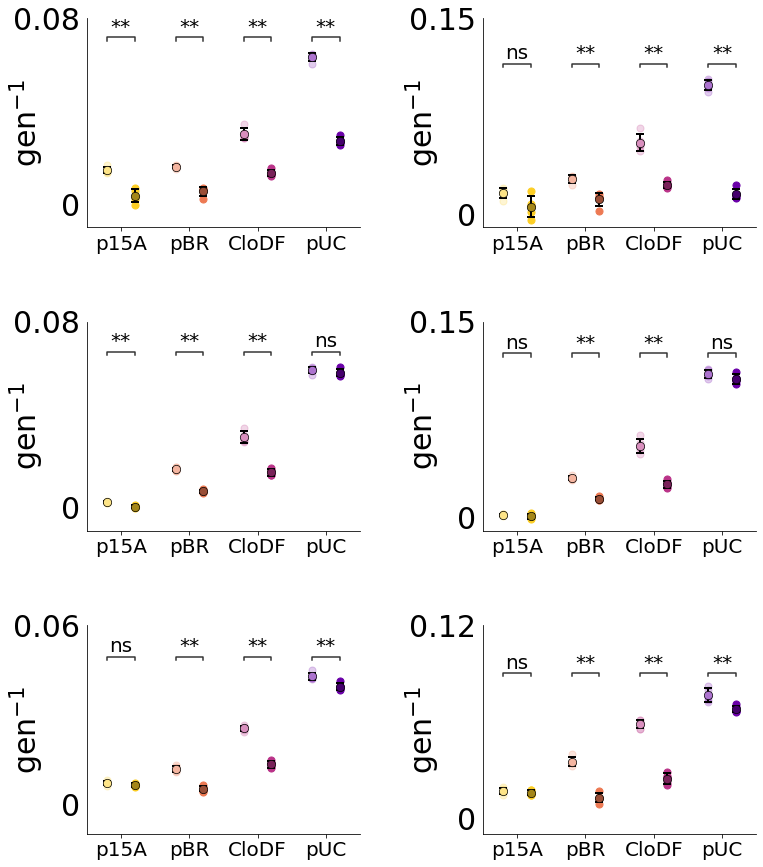

In [216]:
fig, axes = plt.subplots(3, 2, figsize=(12, 15))

# 4D — plasmid copy
filtered_qpcr_df_loss_kan = combined_qPCR_df[(combined_qPCR_df['gain'] == 0) & (combined_qPCR_df['Transposase'] == 1) & (combined_qPCR_df['PCN'] != 'Chromosome')]
plotStatQPCR(filtered_qpcr_df_loss_kan, 'Kan', 0.08, ax=axes[0, 0], toPlot='rate_log(plasmid copy)')

filtered_qpcr_df_gain_kan = combined_qPCR_df[(combined_qPCR_df['gain'] == 1) & (combined_qPCR_df['Transposase'] == 1) & (combined_qPCR_df['PCN'] != 'Chromosome')]
plotStatQPCR(filtered_qpcr_df_gain_kan, 'Kan', 0.15, ax=axes[0, 1], toPlot='rate_log(plasmid copy)')

# 4F — transposon copy
plotStatQPCR(filtered_qpcr_df_loss_kan, 'Kan', 0.08, ax=axes[1, 0])
plotStatQPCR(filtered_qpcr_df_gain_kan, 'Kan', 0.15, ax=axes[1, 1])

# 4H — GFP
filtered_df_loss_kan = combined_df[(combined_df['gain'] == 0) & (combined_df['Transposase'] == 1) & (combined_df['Plasmid'] != 'Chromosome')]
filtered_df_gain_kan = combined_df[(combined_df['gain'] == 1) & (combined_df['Transposase'] == 1) & (combined_df['Plasmid'] != 'Chromosome')]

plotStatGFP(filtered_df_loss_kan, 'Kan', 0.06, ax=axes[2, 0])
plotStatGFP(filtered_df_gain_kan, 'Kan', 0.12, ax=axes[2, 1])

# Move y-axis labels closer to their axes
for ax in axes[:, 0]:
    ax.yaxis.set_label_coords(-0.15, 0.5)

for ax in axes[:, 1]:
    ax.yaxis.set_label_coords(-0.15, 0.5)

fig.subplots_adjust(wspace=0.45, hspace=0.45)
plt.savefig('Figures_final/Figure4/Figure4DFH.pdf', format='pdf', bbox_inches='tight')
plt.show()

### Supplementary Figure 8
**Saved outputs:** `SF8F_GFP_Loss.pdf`

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:2.222e-01 U_stat=6.000e+00
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.508e-01 U_stat=2.000e+01


,Plasmid,Mean (Kan=0),Mean (Kan=1),Fold Change (Raw)
0,p15A,0.007273,0.008787,0.827675
1,pBR,0.008355,0.002666,3.133810
2,CloDF,0.020936,0.013970,1.498562
3,pUC,0.042597,0.038019,1.120422


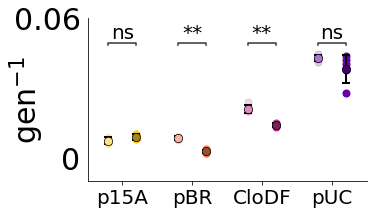

In [217]:
filtered_df_loss_noT = combined_df[(combined_df['gain']==0) & (combined_df['Transposase']==0) & (combined_df['Plasmid'] != 'Chromosome')]
filtered_df_loss_noT = filtered_df_loss_noT.loc[~(filtered_df_loss_noT['Plasmid'] == 'Chromosome')]

plotStatGFP(filtered_df_loss_noT, 'Kan', 0.06, 'Figures_final/supplementary/SF8F_GFP_Loss.pdf')

### Supplementary Figure 8
**Saved outputs:** `SF8F_GFP_Gain.pdf`

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:6.905e-01 U_stat=1.500e+01
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:8.413e-01 U_stat=1.100e+01


,Plasmid,Mean (Kan=0),Mean (Kan=1),Fold Change (Raw)
0,p15A,0.017772,0.017534,1.013525
1,pBR,0.019044,0.008686,2.192543
2,CloDF,0.044753,0.017867,2.504816
3,pUC,0.076200,0.074115,1.028139


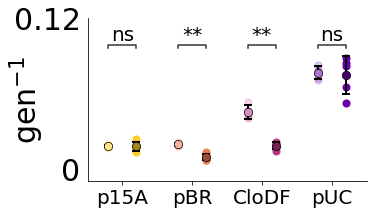

In [218]:
filtered_df_gain_noT = combined_df[(combined_df['gain']==1) & (combined_df['Transposase']==0) & (combined_df['Plasmid'] != 'Chromosome')]
filtered_df_gain_noT = filtered_df_gain_noT.loc[~(filtered_df_gain_noT['Plasmid'] == 'Chromosome')]

plotStatGFP(filtered_df_gain_noT, 'Kan', 0.12, 'Figures_final/supplementary/SF8F_GFP_Gain.pdf')

### Supplementary Figure 8
**Saved outputs:** `SF8D_qPCR_Loss.pdf`

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:3.175e-02 U_stat=2.300e+01
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:9.524e-02 U_stat=4.000e+00
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:3.095e-01 U_stat=1.800e+01
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:3.175e-02 U_stat=2.300e+01


,Plasmid,Mean (Kan=0),Mean (Kan=1),Fold Change (Raw)
0,p15A,0.005343,0.005686,0.939677
1,pBR,0.002687,0.000364,7.380323
2,CloDF,0.017350,0.015688,1.105919
3,pUC,0.056739,0.043401,1.307310


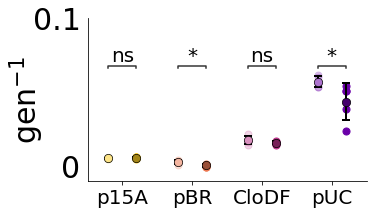

In [219]:
filtered_qPCR_df_loss_noT = combined_qPCR_df[(combined_qPCR_df['gain']==0) & (combined_qPCR_df['Transposase']==0) & (combined_qPCR_df['PCN'] != 'Chromosome')]
filtered_qPCR_df_loss_noT = filtered_qPCR_df_loss_noT.loc[~(filtered_qPCR_df_loss_noT['PCN'] == 'Chromosome')]

plotStatQPCR(filtered_qPCR_df_loss_noT, 'Kan', 0.1, 'Figures_final/supplementary/SF8D_qPCR_Loss.pdf')

### Supplementary Figure 8
**Saved outputs:** `SF8D_qPCR_Gain.pdf`

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=0.000e+00
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:3.095e-01 U_stat=1.800e+01


,Plasmid,Mean (Kan=0),Mean (Kan=1),Fold Change (Raw)
0,p15A,-0.000039,0.001701,-0.023201
1,pBR,0.009780,-0.000402,-24.343303
2,CloDF,0.029232,0.008982,3.254528
3,pUC,0.116328,0.087728,1.326017


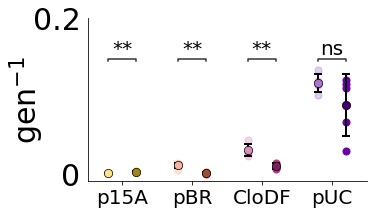

In [220]:
filtered_qPCR_df_gain_noT = combined_qPCR_df[(combined_qPCR_df['gain']==1) & (combined_qPCR_df['Transposase']==0) & (combined_qPCR_df['PCN'] != 'Chromosome')]
filtered_qPCR_df_gain_noT = filtered_qPCR_df_gain_noT.loc[~(filtered_qPCR_df_gain_noT['PCN'] == 'Chromosome')]

plotStatQPCR(filtered_qPCR_df_gain_noT, 'Kan', 0.2, 'Figures_final/supplementary/SF8D_qPCR_Gain.pdf')

### Supplementary Figure 8
**Saved outputs:** `SF8B_plasmid_qPCR_Loss.pdf`

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01


,Plasmid,Mean (Kan=0),Mean (Kan=1),Fold Change (Raw)
0,p15A,0.006275,-0.002516,-2.494658
1,pBR,0.004121,-0.001287,-3.201108
2,CloDF,0.018857,0.010969,1.719167
3,pUC,0.042901,0.006673,6.429036


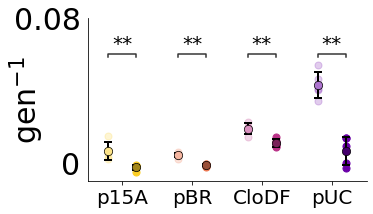

In [221]:
plotStatQPCR(filtered_qPCR_df_loss_noT, 'Kan', 0.08, 'Figures_final/supplementary/SF8B_plasmid_qPCR_Loss.pdf', 'rate_log(plasmid copy)')

### Supplementary Figure 8
**Saved outputs:** `SF8B_plasmid_qPCR_Gain.pdf`

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.508e-01 U_stat=2.000e+01
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01


,Plasmid,Mean (Kan=0),Mean (Kan=1),Fold Change (Raw)
0,p15A,0.000574,-0.002663,-0.215433
1,pBR,0.011031,-0.006072,-1.816726
2,CloDF,0.027549,-0.002352,-11.713387
3,pUC,0.074987,-0.007142,-10.499796


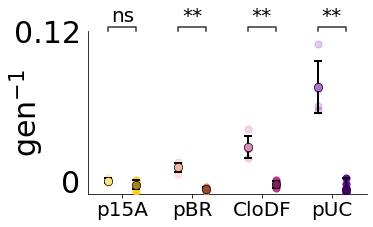

In [222]:
plotStatQPCR(filtered_qPCR_df_gain_noT, 'Kan', 0.12, 'Figures_final/supplementary/SF8B_plasmid_qPCR_Gain.pdf', 'rate_log(plasmid copy)')

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=2.500e+01
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.508e-01 U_stat=2.000e+01
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_sta

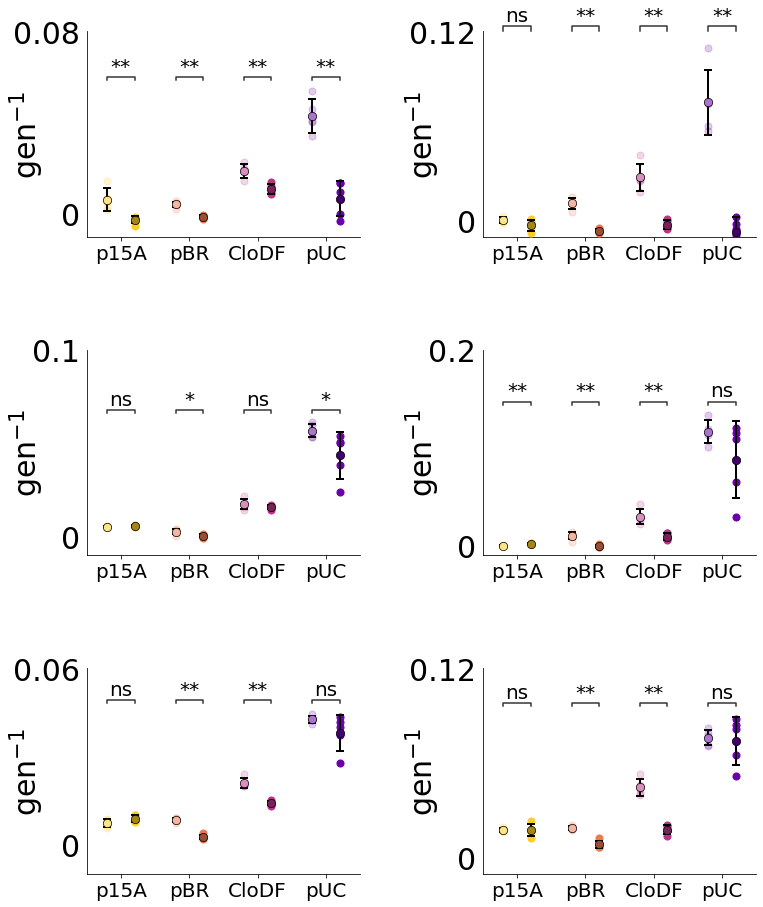

In [223]:
fig, axes = plt.subplots(3, 2, figsize=(12, 15.5))

# 8B — plasmid copy
filtered_qPCR_df_loss_noT = combined_qPCR_df[(combined_qPCR_df['gain'] == 0) & (combined_qPCR_df['Transposase'] == 0) & (combined_qPCR_df['PCN'] != 'Chromosome')]
filtered_qPCR_df_gain_noT = combined_qPCR_df[(combined_qPCR_df['gain'] == 1) & (combined_qPCR_df['Transposase'] == 0) & (combined_qPCR_df['PCN'] != 'Chromosome')]

plotStatQPCR(filtered_qPCR_df_loss_noT, 'Kan', 0.08, ax=axes[0, 0], toPlot='rate_log(plasmid copy)')
plotStatQPCR(filtered_qPCR_df_gain_noT, 'Kan', 0.12, ax=axes[0, 1], toPlot='rate_log(plasmid copy)')

# 8D — transposon copy
plotStatQPCR(filtered_qPCR_df_loss_noT, 'Kan', 0.1, ax=axes[1, 0])
plotStatQPCR(filtered_qPCR_df_gain_noT, 'Kan', 0.2, ax=axes[1, 1])

# 8F — GFP
filtered_df_loss_noT = combined_df[(combined_df['gain'] == 0) & (combined_df['Transposase'] == 0) & (combined_df['Plasmid'] != 'Chromosome')]
filtered_df_gain_noT = combined_df[(combined_df['gain'] == 1) & (combined_df['Transposase'] == 0) & (combined_df['Plasmid'] != 'Chromosome')]

plotStatGFP(filtered_df_loss_noT, 'Kan', 0.06, ax=axes[2, 0])
plotStatGFP(filtered_df_gain_noT, 'Kan', 0.12, ax=axes[2, 1])

# Move y-axis labels closer to their axes
for ax in axes[:, 0]:
    ax.yaxis.set_label_coords(-0.15, 0.5)

for ax in axes[:, 1]:
    ax.yaxis.set_label_coords(-0.15, 0.5)

fig.subplots_adjust(wspace=0.45, hspace=0.55)
plt.savefig('Figures_final/supplementary/SF8BDF.pdf', format='pdf', bbox_inches='tight')
plt.show()

### Supplementary Figure 7
**Saved outputs:** `SF7B_plasmid_TP_Loss.pdf`

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.476e-01 U_stat=9.000e+00
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=0.000e+00
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.556e-02 U_stat=3.000e+00
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=0.000e+00


,Plasmid,Mean (Kan=0),Mean (Kan=1),Fold Change (Raw)
0,p15A,-0.009983,-0.002204,4.529018
1,pBR,0.001104,0.001872,0.589455
2,CloDF,0.001195,0.002216,0.539455
3,pUC,0.004632,0.048851,0.094809


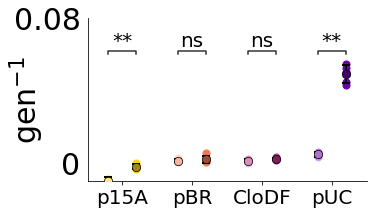

In [224]:
filtered_qPCR_df_loss_ = combined_qPCR_df[(combined_qPCR_df['gain']==0) & (combined_qPCR_df['Transposase']==1) & (combined_qPCR_df['PCN'] != 'Chromosome')]
filtered_qPCR_df_loss_ = filtered_qPCR_df_loss_.loc[~(filtered_qPCR_df_loss_['PCN'] == 'Chr')]

plotStatQPCR(filtered_qPCR_df_loss_, 'Kan', 0.08, 'Figures_final/supplementary/SF7B_plasmid_TP_Loss.pdf', 'rate_log(T/P)')

### Supplementary Figure 7
**Saved outputs:** `SF7B_plasmid_TP_Gain.pdf`

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:3.095e-01 U_stat=1.800e+01
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:3.175e-02 U_stat=2.000e+00
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:9.524e-02 U_stat=4.000e+00
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=0.000e+00


,Plasmid,Mean (Kan=0),Mean (Kan=1),Fold Change (Raw)
0,p15A,-0.011432,-0.002281,5.011767
1,pBR,0.004502,0.003886,1.158667
2,CloDF,0.002644,0.004005,0.660097
3,pUC,0.032408,0.135184,0.239735


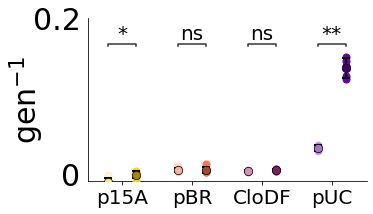

In [225]:
filtered_qPCR_df_gain_ = combined_qPCR_df[(combined_qPCR_df['gain']==1) & (combined_qPCR_df['Transposase']==1) & (combined_qPCR_df['PCN'] != 'Chromosome')]
filtered_qPCR_df_gain_ = filtered_qPCR_df_gain_.loc[~(filtered_qPCR_df_gain_['PCN'] == 'Chr')]

plotStatQPCR(filtered_qPCR_df_gain_, 'Kan', 0.2, 'Figures_final/supplementary/SF7B_plasmid_TP_Gain.pdf', 'rate_log(T/P)')

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.476e-01 U_stat=9.000e+00
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=0.000e+00
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.556e-02 U_stat=3.000e+00
pUC_0 vs. pUC_1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.937e-03 U_stat=0.000e+00
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pBR_0 vs. pBR_1: Mann-Whitney-Wilcoxon test two-sided, P_val:3.095e-01 U_stat=1.800e+01
p15A_0 vs. p15A_1: Mann-Whitney-Wilcoxon test two-sided, P_val:3.175e-02 U_stat=2.000e+00
CloDF_0 vs. CloDF_1: Mann-Whitney-Wilcoxon test two-sided, P_val:9.524e-02 U_sta

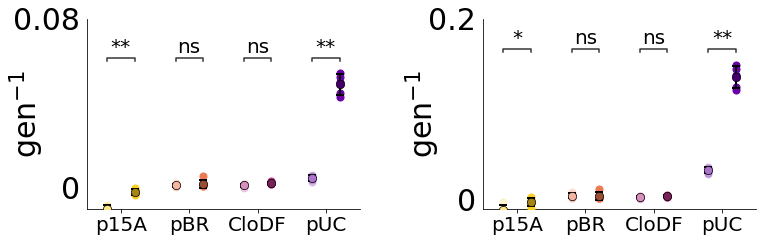

In [226]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

filtered_qPCR_df_loss_ = combined_qPCR_df[(combined_qPCR_df['gain'] == 0) & (combined_qPCR_df['Transposase'] == 1) & (combined_qPCR_df['PCN'] != 'Chromosome')]
filtered_qPCR_df_loss_ = filtered_qPCR_df_loss_.loc[~(filtered_qPCR_df_loss_['PCN'] == 'Chr')]
plotStatQPCR(filtered_qPCR_df_loss_, 'Kan', 0.08, ax=axes[0], toPlot='rate_log(T/P)')

filtered_qPCR_df_gain_ = combined_qPCR_df[(combined_qPCR_df['gain'] == 1) & (combined_qPCR_df['Transposase'] == 1) & (combined_qPCR_df['PCN'] != 'Chromosome')]
filtered_qPCR_df_gain_ = filtered_qPCR_df_gain_.loc[~(filtered_qPCR_df_gain_['PCN'] == 'Chr')]
plotStatQPCR(filtered_qPCR_df_gain_, 'Kan', 0.2, ax=axes[1], toPlot='rate_log(T/P)')

# Move y-axis labels closer to their axes
for ax in axes:
    ax.yaxis.set_label_coords(-0.15, 0.5)

fig.subplots_adjust(wspace=0.45, hspace=0.45)
plt.savefig('Figures_final/supplementary/SF7B.pdf', format='pdf', bbox_inches='tight')
plt.show()

# Figure 5B

In [227]:
colorScheme = 'plasma'

In [228]:
## delete this?
combined_df_Fig5 = combined_df[combined_df['Plasmid'] != "Chromosome"]

combined_df_Fig5["Plasmid"] = combined_df_Fig5["Plasmid"].astype("category")

combined_df_Fig5["Plasmid"] = combined_df_Fig5["Plasmid"].cat.reorder_categories(
        [
            "p15A",
            "pBR",
            "CloDF",
            "pUC"
        ],
        ordered=True,
    )

combined_qPCR_df_Fig5 = combined_qPCR_df[combined_qPCR_df['PCN'] != "Chromosome"]

combined_qPCR_df_Fig5["PCN"] = combined_qPCR_df_Fig5["PCN"].astype("category")

combined_qPCR_df_Fig5["PCN"] = combined_qPCR_df_Fig5["PCN"].cat.reorder_categories(
        [
            "p15A",
            "pBR",
            "CloDF",
            "pUC",
        ],
        ordered=True,
    )

/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_67811/3106731240.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  combined_df_Fig5["Plasmid"] = combined_df_Fig5["Plasmid"].astype("category")
/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_67811/3106731240.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  combined_df_Fig5["Plasmid"] = combined_df_Fig5["Plasmid"].cat.reorder_categories(
/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_67811/3106731240.py:18: SettingWithCop

In [229]:
combined_df_Fig5 = combined_df.copy()
combined_df_Fig5["Plasmid"] = pd.Categorical(combined_df_Fig5["Plasmid"], categories=["Chromosome", "p15A", "pBR", "CloDF", "pUC"], ordered=True)

combined_qPCR_df_Fig5 = combined_qPCR_df.copy()
combined_qPCR_df_Fig5["PCN"] = pd.Categorical(combined_qPCR_df_Fig5["PCN"], categories=["Chromosome", "p15A", "pBR", "CloDF", "pUC"], ordered=True)

In [230]:
GFP_gain_noT = combined_df_Fig5[(combined_df_Fig5['gain']==1) & (combined_df_Fig5['Transposase']==0)]

GFP_gain_withT = combined_df_Fig5[(combined_df_Fig5['gain']==1) & (combined_df_Fig5['Transposase']==1)]

GFP_loss_noT = combined_df_Fig5[(combined_df_Fig5['gain']==0) & (combined_df_Fig5['Transposase']==0)]

GFP_loss_withT = combined_df_Fig5[(combined_df_Fig5['gain']==0) & (combined_df_Fig5['Transposase']==1)]

In [231]:
qPCR_gain_noT = combined_qPCR_df_Fig5[(combined_qPCR_df_Fig5['gain']==1) & (combined_qPCR_df_Fig5['Transposase']==0)]

qPCR_gain_withT = combined_qPCR_df_Fig5[(combined_qPCR_df_Fig5['gain']==1) & (combined_qPCR_df_Fig5['Transposase']==1)]

qPCR_loss_noT = combined_qPCR_df_Fig5[(combined_qPCR_df_Fig5['gain']==0) & (combined_qPCR_df_Fig5['Transposase']==0)]

qPCR_loss_withT = combined_qPCR_df_Fig5[(combined_qPCR_df_Fig5['gain']==0) & (combined_qPCR_df_Fig5['Transposase']==1)]

### F5B gain -T

In [232]:
alt.Chart(GFP_gain_noT).mark_point(size=70).encode(
        alt.X("Plasmid", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title=None),
        alt.Y("rate_log(GFP/OD)", scale=alt.Scale(domain=[-0.02, 0.15]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, tickCount = 3, ticks=False, grid=False), title=None),
        color=alt.Color('Plasmid').scale(scheme=colorScheme,reverse=True),
        shape=alt.Shape('Kan:O', scale=alt.Scale(range=['arrow', 'triangle']))
    ).properties(
        title='GFP gain rate',
        width=150,
        height=150
    ).interactive()

alt.Chart(...)

In [233]:
F5B_gain_noT = alt.Chart(qPCR_gain_noT).mark_point(size=70).encode(
        alt.X("averagePCN", scale=alt.Scale(type='log'), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False, values=[10, 50, 600], ticks=True), title=None),
        alt.Y("rate_log(transposon copy)", scale=alt.Scale(domain=[-0.01, 0.15]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, tickCount = 3, ticks=False, grid=False), title=None),
        color=alt.Color('PCN',legend=None).scale(scheme=colorScheme,reverse=True),
        shape=alt.Shape('Kan:O', scale=alt.Scale(range=['arrow', 'triangle']), legend=None)
    ).properties(
        title='',
        width=200,
        height=200,
    ).interactive()

F5B_gain_noT

alt.Chart(...)

In [234]:
qPCR_gain_noT_PCN_rep = qPCR_gain_noT.copy()
qPCR_gain_noT_PCN_rep.loc[0:19, 'replicate_averagePCN'] = averagePCN_rep_kan_noT.loc[0:19, 'replicate_averagePCN'].values

In [235]:
qPCR_gain_noT_PCN_rep = qPCR_gain_noT_PCN_rep.copy()
qPCR_gain_noT_PCN_rep.loc[20:39, 'replicate_averagePCN'] = averagePCN_rep_noKan_noT.loc[0:19, 'replicate_averagePCN'].values

### Figure 5B
**Saved outputs:** `F5B_gain_noT.pdf`

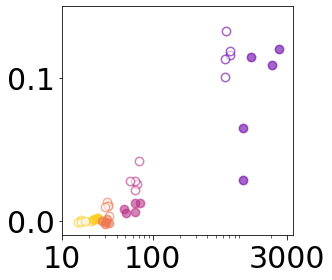

In [236]:
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FixedLocator

fig, ax = plt.subplots(figsize=(4.7, 4))

for pcn, color in zip(['p15A', 'pBR', 'CloDF', 'pUC'], plt.cm.plasma_r(np.linspace(0.1, 0.8, 4))):
    for kan, marker, face in [(0, 'o', 'white'), (1, 'o', color)]:
        d = qPCR_gain_noT_PCN_rep[(qPCR_gain_noT_PCN_rep['PCN'] == pcn) & (qPCR_gain_noT_PCN_rep['Kan'] == kan)]
        ax.scatter(d['replicate_averagePCN'], d['rate_log(transposon copy)'], s=70, marker=marker,
                   facecolors=face, edgecolors=color, linewidths=1.5, alpha=0.6)

ax.set_xscale('log')
ax.set_xlim(10, 3500)
ax.set_ylim(-0.01, 0.15)

# Explicit major ticks
ax.xaxis.set_major_locator(FixedLocator([10, 100, 3000]))
ax.xaxis.set_major_formatter(plt.ScalarFormatter())

# Minor log ticks
ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))
ax.tick_params(axis='x', which='major', labelsize=30, length=5)
ax.tick_params(axis='x', which='minor', length=3)

ax.tick_params(axis='y', labelsize=30)
ax.set_xlabel('')
ax.set_ylabel('')
ax.grid(False)

plt.tight_layout()
plt.savefig('Figures_final/Figure5B/F5B_gain_noT.pdf')
plt.show()

### F5B loss -T

In [237]:
alt.Chart(GFP_loss_noT).mark_point(size=70).encode(
        alt.X("Plasmid", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title=None),
        alt.Y("rate_log(GFP/OD)", scale=alt.Scale(domain=[-0.02, 0.08]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, tickCount = 3, ticks=False, grid=False), title=None),
        color=alt.Color('Plasmid').scale(scheme=colorScheme,reverse=True),
        shape=alt.Shape('Kan:O', scale=alt.Scale(range=['arrow', 'triangle']))
    ).properties(
        title='GFP loss rate',
        width=150,
        height=150
    ).interactive()

alt.Chart(...)

In [238]:
F5B_loss_noT = alt.Chart(qPCR_loss_noT).mark_point(size=70).encode(
        alt.X("averagePCN", scale=alt.Scale(type='log'), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False, values=[10, 50, 600], ticks=False), title=None),
        alt.Y("rate_log(transposon copy)", scale=alt.Scale(domain=[-0.03, 0.44]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, tickCount = 3, ticks=False, grid=False), title=None),
        color=alt.Color('PCN',legend=None).scale(scheme=colorScheme,reverse=True),
        shape=alt.Shape('Kan:O', scale=alt.Scale(range=['arrow', 'triangle']), legend=None)
    ).properties(
        title='',
        width=150,
        height=150,
    ).interactive()

F5B_loss_noT

alt.Chart(...)

In [239]:
qPCR_loss_noT_PCN_rep = qPCR_loss_noT.copy()
qPCR_loss_noT_PCN_rep.loc[40:59, 'replicate_averagePCN'] = averagePCN_rep_kan_noT.loc[0:19, 'replicate_averagePCN'].values

In [240]:
qPCR_loss_noT_PCN_rep = qPCR_loss_noT_PCN_rep.copy()
qPCR_loss_noT_PCN_rep.loc[60:79, 'replicate_averagePCN'] = averagePCN_rep_noKan_noT.loc[0:19, 'replicate_averagePCN'].values

### Figure 5B
**Saved outputs:** `F5B_loss_noT.pdf`

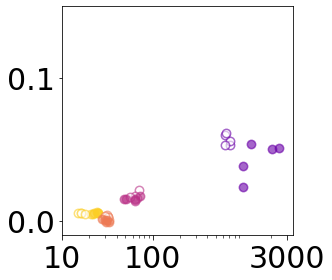

In [241]:
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FixedLocator

fig, ax = plt.subplots(figsize=(4.7, 4))

for pcn, color in zip(['p15A', 'pBR', 'CloDF', 'pUC'], plt.cm.plasma_r(np.linspace(0.1, 0.8, 4))):
    for kan, marker, face in [(0, 'o', 'white'), (1, 'o', color)]:
        d = qPCR_loss_noT_PCN_rep[(qPCR_loss_noT_PCN_rep['PCN'] == pcn) & (qPCR_loss_noT_PCN_rep['Kan'] == kan)]
        ax.scatter(d['replicate_averagePCN'], d['rate_log(transposon copy)'], s=70, marker=marker,
                   facecolors=face, edgecolors=color, linewidths=1.5, alpha=0.6)

ax.set_xscale('log')
ax.set_xlim(10, 3500)
ax.set_ylim(-0.01, 0.15)

# Explicit major ticks
ax.xaxis.set_major_locator(FixedLocator([10, 100, 3000]))
ax.xaxis.set_major_formatter(plt.ScalarFormatter())

# Minor log ticks
ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))
ax.tick_params(axis='x', which='major', labelsize=30, length=5)
ax.tick_params(axis='x', which='minor', length=3)

ax.tick_params(axis='y', labelsize=30)
ax.set_xlabel('')
ax.set_ylabel('')
ax.grid(False)

#from matplotlib.lines import Line2D

#plasmid_colors = dict(zip(
#    ['p15A', 'pBR', 'CloDF', 'pUC'],
#    plt.cm.plasma_r(np.linspace(0.1, 0.8, 4))
#))

#legend_elements = [
#    Line2D([0], [0], marker='o', linestyle='None', markerfacecolor=color,
#           markeredgecolor=color, markersize=8, label=pcn)
#    for pcn, color in plasmid_colors.items()
#] + [
#    Line2D([0], [0], marker='o', linestyle='None', markerfacecolor='white',
#           markeredgecolor='black', markersize=8, label='−Kan'),
#    Line2D([0], [0], marker='o', linestyle='None', markerfacecolor='black',
#           markeredgecolor='black', markersize=8, label='+Kan')]

#ax.legend(handles=legend_elements, fontsize=12, frameon=True,fancybox=True, edgecolor='black', framealpha=1,loc='lower left', bbox_to_anchor=(1.02, 0.5))

plt.tight_layout()
#plt.subplots_adjust(right=0.72)
plt.savefig('Figures_final/Figure5B/F5B_loss_noT.pdf')
plt.show()

### F5B gain +T

In [242]:
alt.Chart(GFP_gain_withT).mark_point(size=70).encode(
        alt.X("Plasmid", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title=None),
        alt.Y("rate_log(GFP/OD)", scale=alt.Scale(domain=[-0.02, 0.15]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, tickCount = 3, ticks=False, grid=False), title=None),
        color=alt.Color('Plasmid').scale(scheme=colorScheme,reverse=True),
        shape=alt.Shape('Kan:O', scale=alt.Scale(range=['arrow', 'triangle']))
    ).properties(
        title='GFP gain rate',
        width=150,
        height=150
    ).interactive()

alt.Chart(...)

In [243]:
F5B_gain_withT = alt.Chart(qPCR_gain_withT).mark_point(size=70).encode(
        alt.X("averagePCN", scale=alt.Scale(type='log'), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False, values=[10, 50, 400], ticks=False), title=None),
        alt.Y("rate_log(transposon copy)", scale=alt.Scale(domain=[-0.03, 0.44]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, tickCount = 3, ticks=False, grid=False), title=None),
        color=alt.Color('PCN',legend=None).scale(scheme=colorScheme,reverse=True),
        shape=alt.Shape('Kan:O', scale=alt.Scale(range=['arrow', 'triangle']), legend=None)
    ).properties(
        title='',
        width=150,
        height=150,
    ).interactive()

F5B_gain_withT

alt.Chart(...)

In [244]:
qPCR_gain_withT_PCN_rep = qPCR_gain_withT.copy()
qPCR_gain_withT_PCN_rep.loc[80:104, 'replicate_averagePCN'] = averagePCN_rep_kan_withT.loc[0:24, 'replicate_averagePCN'].values

In [245]:
qPCR_gain_withT_PCN_rep = qPCR_gain_withT_PCN_rep.copy()
qPCR_gain_withT_PCN_rep.loc[105:129, 'replicate_averagePCN'] = averagePCN_rep_noKan_withT.loc[0:24, 'replicate_averagePCN'].values

### Figure 5B
**Saved outputs:** `F5B_gain_withT.pdf`

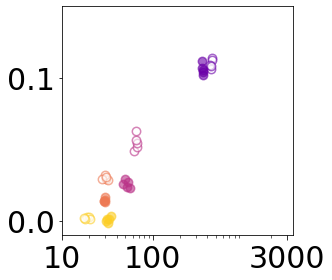

In [246]:
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FixedLocator

fig, ax = plt.subplots(figsize=(4.7, 4))

for pcn, color in zip(['p15A', 'pBR', 'CloDF', 'pUC'], plt.cm.plasma_r(np.linspace(0.1, 0.8, 4))):
    for kan, marker, face in [(0, 'o', 'white'), (1, 'o', color)]:
        d = qPCR_gain_withT_PCN_rep[(qPCR_gain_withT_PCN_rep['PCN'] == pcn) & (qPCR_gain_withT_PCN_rep['Kan'] == kan)]
        ax.scatter(d['replicate_averagePCN'], d['rate_log(transposon copy)'], s=70, marker=marker,
                   facecolors=face, edgecolors=color, linewidths=1.5, alpha=0.6)

ax.set_xscale('log')
ax.set_xlim(10, 3500)
ax.set_ylim(-0.01, 0.15)

# Explicit major ticks
ax.xaxis.set_major_locator(FixedLocator([10, 100, 3000]))
ax.xaxis.set_major_formatter(plt.ScalarFormatter())

# Minor log ticks
ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))
ax.tick_params(axis='x', which='major', labelsize=30, length=5)
ax.tick_params(axis='x', which='minor', length=3)

ax.tick_params(axis='y', labelsize=30)
ax.set_xlabel('')
ax.set_ylabel('')
ax.grid(False)

plt.tight_layout()
plt.savefig('Figures_final/Figure5B/F5B_gain_withT.pdf')
plt.show()

### F5B loss +T

In [247]:
alt.Chart(GFP_loss_withT).mark_point(size=70).encode(
        alt.X("Plasmid", axis=alt.Axis(labelFontSize=15, titleFontSize=15, grid=False), title=None),
        alt.Y("rate_log(GFP/OD)", scale=alt.Scale(domain=[-0.02, 0.08]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, tickCount = 3, ticks=False, grid=False), title=None),
        color=alt.Color('Plasmid').scale(scheme=colorScheme,reverse=True),
        shape=alt.Shape('Kan:O', scale=alt.Scale(range=['arrow', 'triangle']))
    ).properties(
        title='GFP loss rate',
        width=150,
        height=150
    ).interactive()

alt.Chart(...)

In [248]:
F5B_loss_withT = alt.Chart(qPCR_loss_withT).mark_point(size=70).encode(
        alt.X("averagePCN", scale=alt.Scale(type='log'), axis=alt.Axis(labelFontSize=30, titleFontSize=15, grid=False, values=[10, 50, 400], ticks=False), title=None),
        alt.Y("rate_log(transposon copy)", scale=alt.Scale(domain=[-0.01, 0.08]), axis=alt.Axis(labelFontSize=30, titleFontSize=15, tickCount = 2, ticks=False, grid=False), title=None),
        color=alt.Color('PCN',legend=None).scale(scheme=colorScheme,reverse=True),
        shape=alt.Shape('Kan:O', scale=alt.Scale(range=['arrow', 'triangle']), legend=None)
    ).properties(
        title='',
        width=150,
        height=150,
    ).interactive()

F5B_loss_withT

alt.Chart(...)

In [249]:
qPCR_loss_withT_PCN_rep = qPCR_loss_withT.copy()
qPCR_loss_withT_PCN_rep.loc[130:154, 'replicate_averagePCN'] = averagePCN_rep_kan_withT.loc[0:24, 'replicate_averagePCN'].values

In [250]:
qPCR_loss_withT_PCN_rep = qPCR_loss_withT_PCN_rep.copy()
qPCR_loss_withT_PCN_rep.loc[155:179, 'replicate_averagePCN'] = averagePCN_rep_noKan_withT.loc[0:24, 'replicate_averagePCN'].values

### Figure 5B
**Saved outputs:** `F5B_loss_withT.pdf`

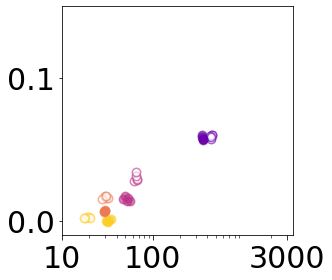

In [251]:
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FixedLocator

fig, ax = plt.subplots(figsize=(4.7, 4))

for pcn, color in zip(['p15A', 'pBR', 'CloDF', 'pUC'], plt.cm.plasma_r(np.linspace(0.1, 0.8, 4))):
    for kan, marker, face in [(0, 'o', 'white'), (1, 'o', color)]:
        d = qPCR_loss_withT_PCN_rep[(qPCR_loss_withT_PCN_rep['PCN'] == pcn) & (qPCR_loss_withT_PCN_rep['Kan'] == kan)]
        ax.scatter(d['replicate_averagePCN'], d['rate_log(transposon copy)'], s=70, marker=marker,
                   facecolors=face, edgecolors=color, linewidths=1.5, alpha=0.6)

ax.set_xscale('log')
ax.set_xlim(10, 3500)
ax.set_ylim(-0.01, 0.15)

# Explicit major ticks
ax.xaxis.set_major_locator(FixedLocator([10, 100, 3000]))
ax.xaxis.set_major_formatter(plt.ScalarFormatter())

# Minor log ticks
ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))
ax.tick_params(axis='x', which='major', labelsize=30, length=5)
ax.tick_params(axis='x', which='minor', length=3)

ax.tick_params(axis='y', labelsize=30)
ax.set_xlabel('')
ax.set_ylabel('')
ax.grid(False)

plt.tight_layout()
plt.savefig('Figures_final/Figure5B/F5B_loss_withT.pdf')
plt.show()

# Figure 3B

### Figure 3B +transposase

**Saved outputs:** `Figure3B_+transposase.pdf`

/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_99724/2302399030.py:49: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  ax = sns.lineplot(


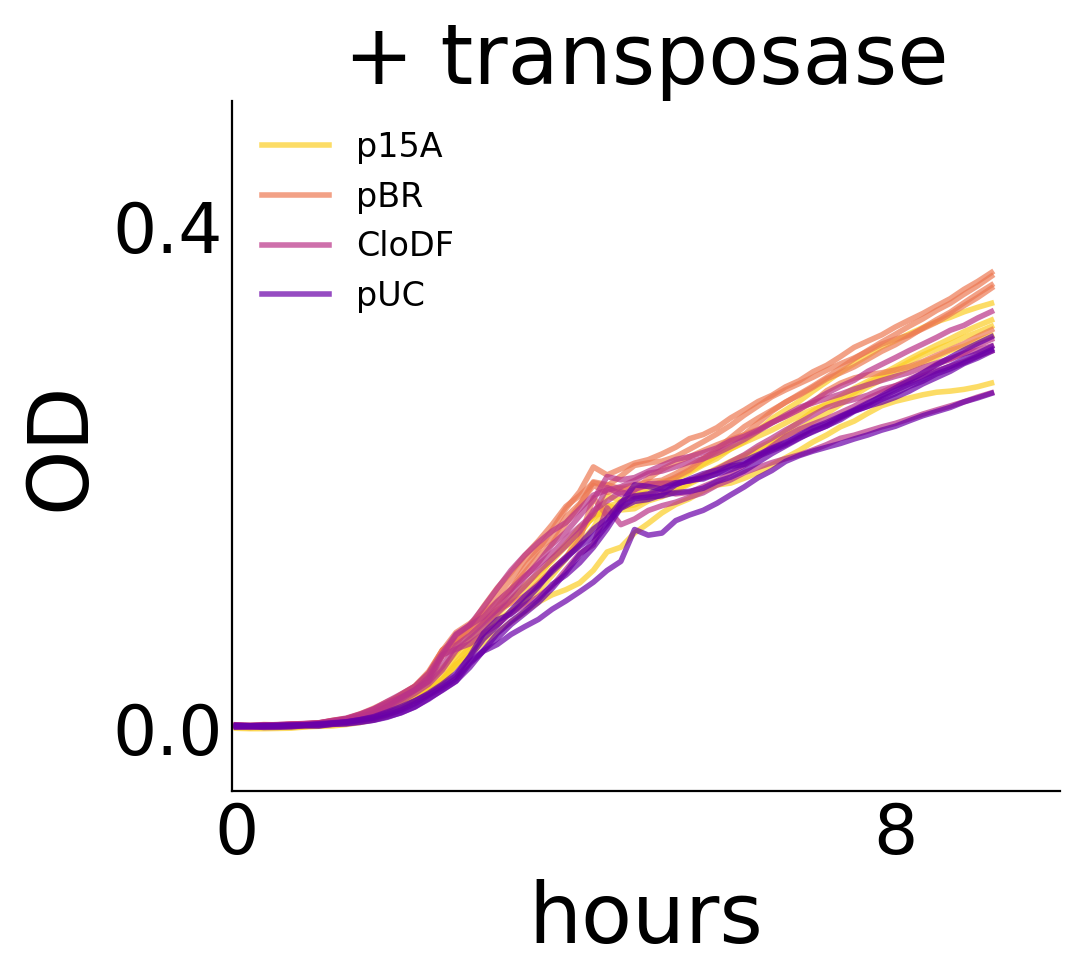

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

file = "9.12.26_Yuanchi_growthcurves.xlsx"
df = pd.read_excel(file, sheet_name="Sheet2", header=None)

plasmids = ['p15A', 'pBR', 'CloDF', 'pUC']
well_rows = {
    'p15A': ['B6', 'C6', 'D6', 'E6', 'F6'],
    'pBR':  ['B7', 'C7', 'D7', 'E7', 'F7'],
    'CloDF':['B8', 'C8', 'D8', 'E8', 'F8'],
    'pUC':  ['B9', 'C9', 'D9', 'E9', 'F9']
}

# Time in hours from the Excel "Time [s]" row
times = pd.to_numeric(df.iloc[36, 1:], errors='coerce') / 3600

data = []

for plasmid in plasmids:
    for rep, well in enumerate(well_rows[plasmid], 1):
        row = df.index[df.iloc[:, 0] == well][0]
        values = pd.to_numeric(df.iloc[row, 1:], errors='coerce')

        for time, od in zip(times, values):
            if pd.notna(time) and pd.notna(od):
                data.append({
                    'Time': time,
                    'PCN': plasmid,
                    'Replicate': rep,
                    'Well': well,
                    'OD': od
                })

df_main = pd.DataFrame(data)

# Subtract LB blank if desired
df_main['OD'] = df_main['OD'] - 0.0541

df_main = df_main.sort_values(['PCN', 'Replicate', 'Time'])

# Plasma color scheme
colors = plt.cm.plasma_r(np.linspace(0.1, 0.8, 4))

plt.figure(figsize=(5.5, 5), dpi=200)

ax = sns.lineplot(
    data=df_main,
    x='Time',
    y='OD',
    hue='PCN',
    hue_order=plasmids,
    units='Well',
    estimator=None,
    palette=colors,
    alpha=0.7,
    linewidth=2,
)


plt.xlim(-0.05, 10)
plt.ylim(-0.05, 0.5)
plt.xticks([0, 8])
plt.yticks([0, 0.4])

ax.tick_params(axis='x', labelsize=25, length=0)
ax.tick_params(axis='y', labelsize=25, length=0)

plt.title('+ transposase', fontsize=30)
plt.xlabel('hours', fontsize=30)
plt.ylabel('OD', fontsize=30)
plt.grid(False)

ax.legend(
    title=None,
    loc='upper left',
    frameon=False,
    fontsize=12
)

sns.despine(left=False, bottom=False, right=True, top=True)

plt.tight_layout()

plt.savefig('Figures_final/Figure3/Figure3B_+transposase.pdf', format='pdf',bbox_inches='tight')

plt.show()

### Figure 3B -transposase

**Saved outputs:** `Figure3B_-transposase.pdf`

/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_99724/1906521705.py:48: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  ax = sns.lineplot(


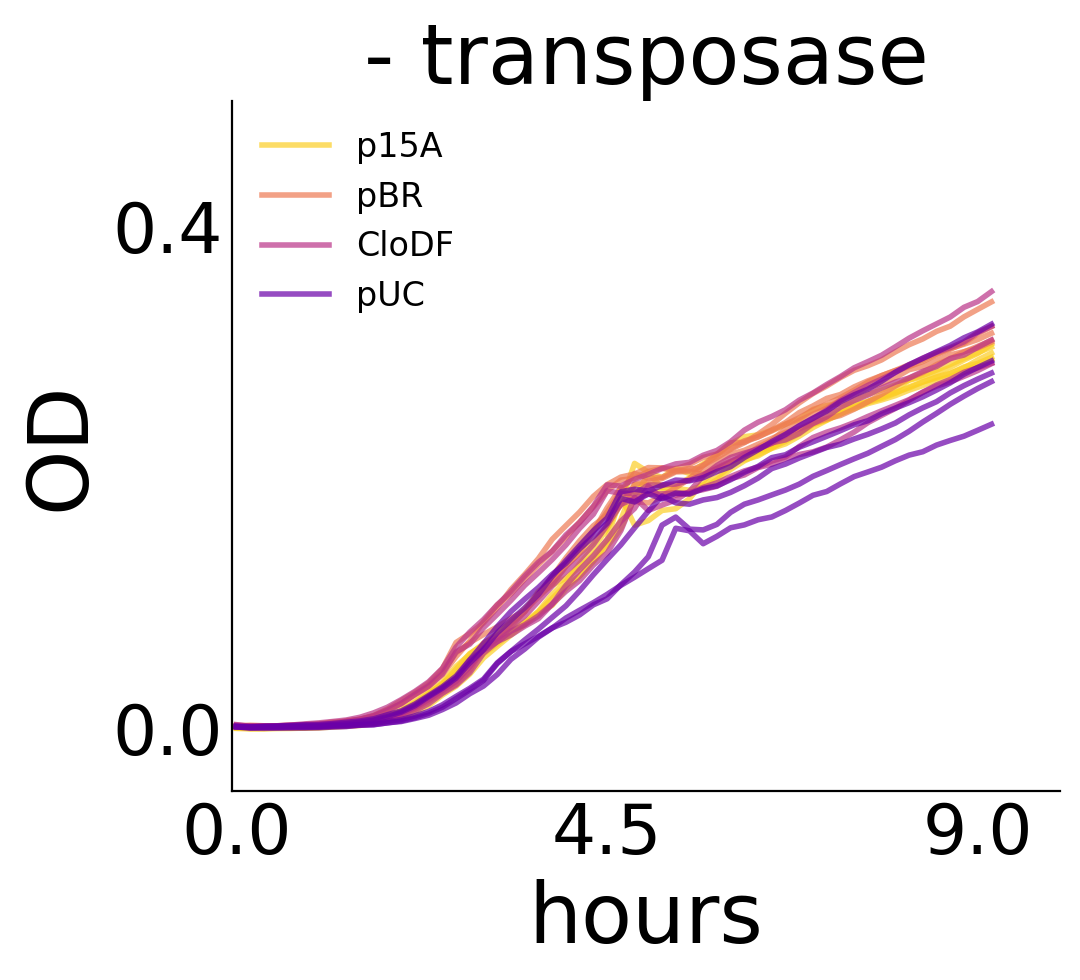

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

file = "9.12.26_Yuanchi_growthcurves.xlsx"
df = pd.read_excel(file, sheet_name="Sheet2", header=None)

plasmids = ['p15A', 'pBR', 'CloDF', 'pUC']
well_rows = {
    'p15A': ['B2', 'C2', 'D2', 'E2', 'F2'],
    'pBR':  ['B3', 'C3', 'D3', 'E3', 'F3'],
    'CloDF':['B4', 'C4', 'D4', 'E4', 'F4'],
    'pUC':  ['B5', 'C5', 'D5', 'E5', 'F5']
}
# Time in hours from the Excel "Time [s]" row
times = pd.to_numeric(df.iloc[36, 1:], errors='coerce') / 3600

data = []

for plasmid in plasmids:
    for rep, well in enumerate(well_rows[plasmid], 1):
        row = df.index[df.iloc[:, 0] == well][0]
        values = pd.to_numeric(df.iloc[row, 1:], errors='coerce')

        for time, od in zip(times, values):
            if pd.notna(time) and pd.notna(od):
                data.append({
                    'Time': time,
                    'PCN': plasmid,
                    'Replicate': rep,
                    'Well': well,
                    'OD': od
                })

df_main = pd.DataFrame(data)

# Subtract LB blank if desired
df_main['OD'] = df_main['OD'] - 0.0541

df_main = df_main.sort_values(['PCN', 'Replicate', 'Time'])

# Plasma color scheme
colors = plt.cm.plasma_r(np.linspace(0.1, 0.8, 4))

plt.figure(figsize=(5.5, 5), dpi=200)

ax = sns.lineplot(
    data=df_main,
    x='Time',
    y='OD',
    hue='PCN',
    hue_order=plasmids,
    units='Well',
    estimator=None,
    palette=colors,
    alpha=0.7,
    linewidth=2
)


plt.xlim(-0.05, 10)
plt.ylim(-0.05, 0.5)
plt.xticks([0, 4.5, 9])
plt.yticks([0, 0.4])

ax.tick_params(axis='x', labelsize=25, length=0)
ax.tick_params(axis='y', labelsize=25, length=0)
plt.title('- transposase', fontsize=30)
plt.xlabel('hours', fontsize=30)
plt.ylabel('OD', fontsize=30)
plt.grid(False)

ax.legend(
    title=None,
    loc='upper left',
    frameon=False,
    fontsize=12
)

ax.get_legend().set_title(None)

sns.despine(left=False, bottom=False, right=True, top=True)

plt.tight_layout()

plt.savefig('Figures_final/Figure3/Figure3B_-transposase.pdf', format='pdf',bbox_inches='tight')

plt.show()

# Figure 4B

### Figure 4B +Kan,+Tet

**Saved outputs:** `Figure4B_+Kan_+Tet.pdf`

/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_99724/3863806061.py:48: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  ax = sns.lineplot(


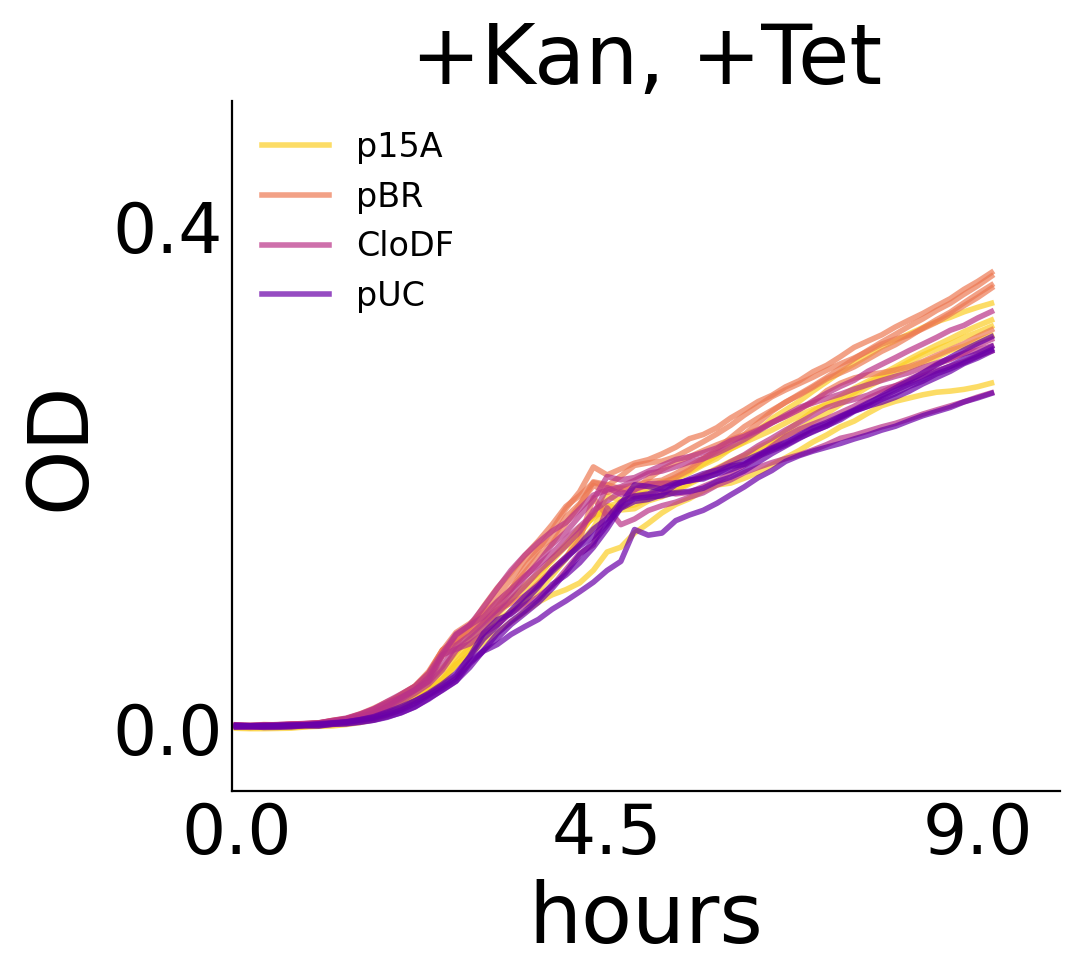

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

file = "9.12.26_Yuanchi_growthcurves.xlsx"
df = pd.read_excel(file, sheet_name="Sheet2", header=None)

plasmids = ['p15A', 'pBR', 'CloDF', 'pUC']
well_rows = {
    'p15A': ['B6', 'C6', 'D6', 'E6', 'F6'],
    'pBR':  ['B7', 'C7', 'D7', 'E7', 'F7'],
    'CloDF':['B8', 'C8', 'D8', 'E8', 'F8'],
    'pUC':  ['B9', 'C9', 'D9', 'E9', 'F9']
}
# Time in hours from the Excel "Time [s]" row
times = pd.to_numeric(df.iloc[36, 1:], errors='coerce') / 3600

data = []

for plasmid in plasmids:
    for rep, well in enumerate(well_rows[plasmid], 1):
        row = df.index[df.iloc[:, 0] == well][0]
        values = pd.to_numeric(df.iloc[row, 1:], errors='coerce')

        for time, od in zip(times, values):
            if pd.notna(time) and pd.notna(od):
                data.append({
                    'Time': time,
                    'PCN': plasmid,
                    'Replicate': rep,
                    'Well': well,
                    'OD': od
                })

df_main = pd.DataFrame(data)

# Subtract LB blank if desired
df_main['OD'] = df_main['OD'] - 0.0541

df_main = df_main.sort_values(['PCN', 'Replicate', 'Time'])

# Plasma color scheme
colors = plt.cm.plasma_r(np.linspace(0.1, 0.8, 4))

plt.figure(figsize=(5.5, 5), dpi=200)

ax = sns.lineplot(
    data=df_main,
    x='Time',
    y='OD',
    hue='PCN',
    hue_order=plasmids,
    units='Well',
    estimator=None,
    palette=colors,
    alpha=0.7,
    linewidth=2
)


plt.xlim(-0.05, 10)
plt.ylim(-0.05, 0.5)
plt.xticks([0, 4.5, 9])
plt.yticks([0, 0.4])

ax.tick_params(axis='x', labelsize=25, length=0)
ax.tick_params(axis='y', labelsize=25, length=0)
plt.title('+Kan, +Tet', fontsize=30)
plt.xlabel('hours', fontsize=30)
plt.ylabel('OD', fontsize=30)
plt.grid(False)

ax.legend(
    title=None,
    loc='upper left',
    frameon=False,
    fontsize=12
)

ax.get_legend().set_title(None)

sns.despine(left=False, bottom=False, right=True, top=True)

plt.tight_layout()

plt.savefig('Figures_final/Figure4/Figure4B_+Kan_+Tet.pdf', format='pdf',bbox_inches='tight')

plt.show()

### Figure 4B -Kan,+Tet

**Saved outputs:** `Figure4B_-Kan_+Tet.pdf`

/var/folders/wb/w4d_wff91hz5pg5nwj41180h0000gn/T/ipykernel_99724/1817672822.py:49: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  ax = sns.lineplot(


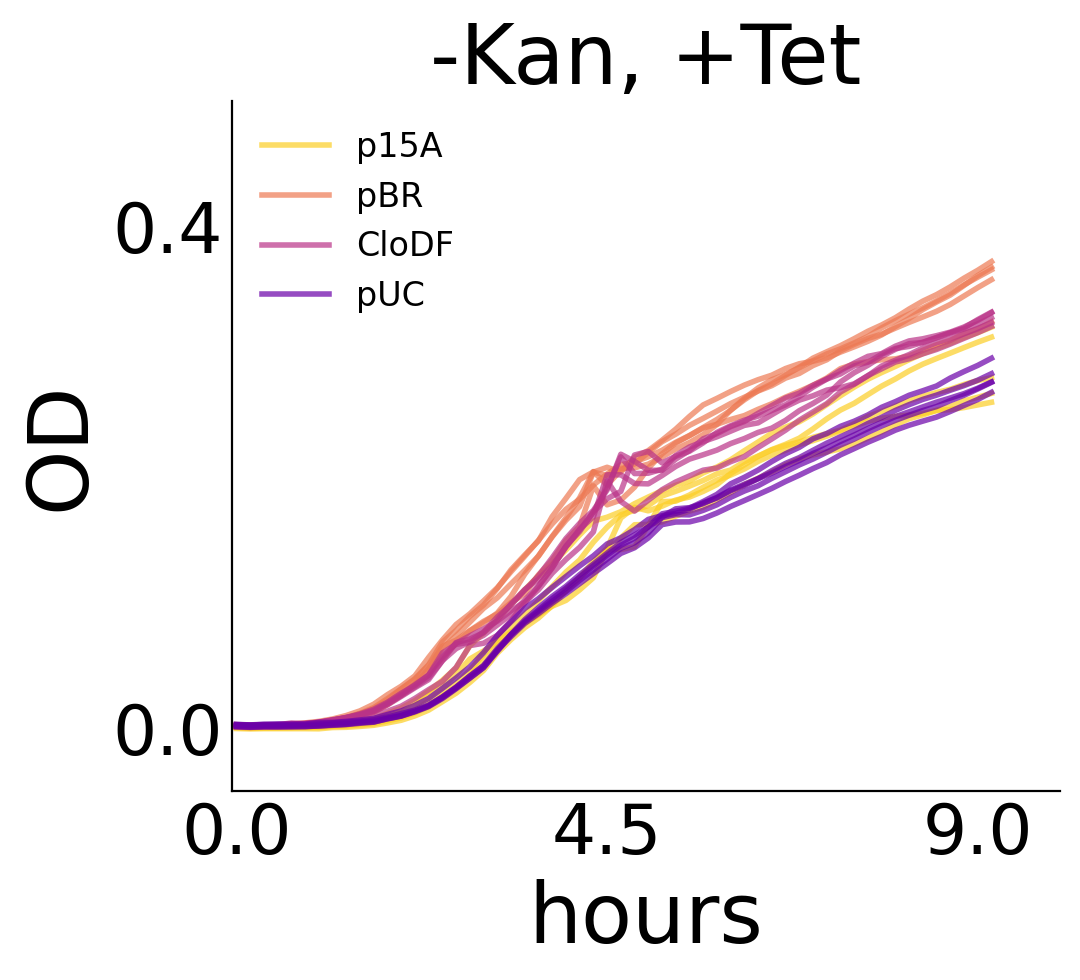

In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

file = "9.12.26_Yuanchi_growthcurves.xlsx"
df = pd.read_excel(file, sheet_name="Sheet2", header=None)

plasmids = ['p15A', 'pBR', 'CloDF', 'pUC']
well_rows = {
    'p15A': ['B10', 'C10', 'D10', 'E10', 'F10'],
    'pBR':  ['B11', 'C11', 'D11', 'E11', 'F11'],
    'CloDF':['G2', 'G3', 'G4', 'G5', 'G6'],
    'pUC':  ['G7', 'G8', 'G9', 'G10', 'G11']
}

# Time in hours from the Excel "Time [s]" row
times = pd.to_numeric(df.iloc[36, 1:], errors='coerce') / 3600

data = []

for plasmid in plasmids:
    for rep, well in enumerate(well_rows[plasmid], 1):
        row = df.index[df.iloc[:, 0] == well][0]
        values = pd.to_numeric(df.iloc[row, 1:], errors='coerce')

        for time, od in zip(times, values):
            if pd.notna(time) and pd.notna(od):
                data.append({
                    'Time': time,
                    'PCN': plasmid,
                    'Replicate': rep,
                    'Well': well,
                    'OD': od
                })

df_main = pd.DataFrame(data)

# Subtract LB blank if desired
df_main['OD'] = df_main['OD'] - 0.0541

df_main = df_main.sort_values(['PCN', 'Replicate', 'Time'])

# Plasma color scheme
colors = plt.cm.plasma_r(np.linspace(0.1, 0.8, 4))

plt.figure(figsize=(5.5, 5), dpi=200)

ax = sns.lineplot(
    data=df_main,
    x='Time',
    y='OD',
    hue='PCN',
    hue_order=plasmids,
    units='Well',
    estimator=None,
    palette=colors,
    alpha=0.7,
    linewidth=2
)


plt.xlim(-0.05, 10)
plt.ylim(-0.05, 0.5)
plt.xticks([0, 4.5, 9])
plt.yticks([0, 0.4])

ax.tick_params(axis='x', labelsize=25, length=0)
ax.tick_params(axis='y', labelsize=25, length=0)
plt.title('-Kan, +Tet', fontsize=30)
plt.xlabel('hours', fontsize=30)
plt.ylabel('OD', fontsize=30)
plt.grid(False)

ax.legend(
    title=None,
    loc='upper left',
    frameon=False,
    fontsize=12
)

ax.get_legend().set_title(None)

sns.despine(left=False, bottom=False, right=True, top=True)

plt.tight_layout()

plt.savefig('Figures_final/Figure4/Figure4B_-Kan_+Tet.pdf', format='pdf',bbox_inches='tight')

plt.show()